[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DilaraLiyanage/colombo-rainfall-simulator/blob/main/notebook/colombo-rainfall-simulator.ipynb)

# Colombo Rainfall Simulator

Historical precipitation, calibrated homogeneous and seasonal rainfall generators, analytical verification, convergence, comparative holdout evaluation and controlled sensitivity.

## 1. Problem and question

How do rainfall occurrence patterns and intensity influence the probability of extreme rainfall events in Colombo? Historical summaries describe associations, not causal effects.

## 2. Model, assumptions and equations

For hourly accumulation $h_t$ ending at local timestamp $t$, daily precipitation is $R_d=\sum_{t:\operatorname{date}(t-1\mathrm{h})=d}h_t$. The wet indicator is $W_d=\mathbf{1}(R_d\geq0.1)$ and model rainfall is $R_d^*=R_d W_d$. Extreme events are $E_d=\mathbf{1}(R_d>q_{0.95,\mathrm{cal}})$, using all original calibration totals and linear quantile interpolation. The same threshold applies to the holdout. The approved baseline is a homogeneous first-order two-state chain and a lower-truncated Gamma wet-amount distribution. Calibration and alternative fits are implemented below; stochastic generation is implemented below. Seasons follow Deoras et al. (2023), reference 7.

## 3. Implementation

Open-Meteo Historical Weather API, Best Match (user-supplied acquisition setting). The supplied acquisition URL is reported to request latitude 6.9355 and longitude 79.8487. Both CSV metadata records report returned latitude 6.924429 and longitude 79.90725, elevation 4 m. The full query and acquisition date are not available here; the relationship between the reported URL and these exact snapshots requires confirmation. Local timestamps are interpreted as exported, without conversion to UTC. Best Match may combine products; no exclusive ERA5/ERA5-Land claim. Data credits: https://open-meteo.com/en/license (CC BY 4.0); upstream Copernicus/ECMWF notices apply. See `data/README.md`.

C01 uses the exact scientific pins in `requirements.txt`. If installed versions differ, it creates a temporary pinned environment. If only loaded versions differ, it uses a fresh interpreter in the existing environment. In either case it starts a fresh worker kernel without restarting the visible notebook. The `%%scientific` cell magic dispatches to that worker (or executes directly when versions already match). Worker scientific imports are explicitly checked; errors stop execution. Additional interactive inspection can use the same cell magic. Environment installation and remote download require network access.

In [ ]:
# C01
# Establish the exact tested scientific environment before loading scientific libraries.
import atexit
import importlib.metadata
import os
from pathlib import Path
import subprocess
import sys
import tempfile
import time
from IPython.display import display

_bootstrap_start = time.perf_counter()
PINS = {"numpy": "2.3.5", "pandas": "2.3.3", "scipy": "1.17.0", "matplotlib": "3.10.8"}

def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None

# Never reload NumPy/pandas binary extensions in a running kernel.
_mismatch = any(_installed_version(k) != v for k, v in PINS.items())
_stale = any(k in sys.modules and getattr(sys.modules[k], "__version__", None) != v
             for k, v in PINS.items())
_isolated = _mismatch or _stale or os.environ.get("RAINFALL_ISOLATED") == "1"
_shell = get_ipython()
if "_close_scientific_worker" in globals():
    _close_scientific_worker()
_manager = None
_client = None
_workspace = None

def _close_scientific_worker():
    """Release the child kernel and temporary environment on re-run or exit."""
    if _client is not None:
        _client.stop_channels()
    if _manager is not None and _manager.has_kernel:
        _manager.shutdown_kernel(now=True)
    if _workspace is not None:
        _workspace.cleanup()

if _isolated:
    from jupyter_client import KernelManager
    _workspace = tempfile.TemporaryDirectory(prefix="rainfall-")
    # A fresh interpreter is sufficient if the installed versions already match.
    _python = Path(sys.executable)
    if _mismatch:
        _venv = Path(_workspace.name) / "env"
        subprocess.check_call([sys.executable, "-m", "venv", "--system-site-packages", str(_venv)])
        _python = _venv / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
        # A nested virtual environment may not inherit the parent kernel packages.
        _kernel_pins = [f"{k}=={_installed_version(k)}" for k in ("ipykernel", "matplotlib-inline")]
        subprocess.check_call([str(_python), "-m", "pip", "install", "-q",
                               *[f"{k}=={v}" for k, v in PINS.items()], *_kernel_pins])
    _connection = str(Path(_workspace.name) / "kernel.json")
    _manager = KernelManager(kernel_name="python3", connection_file=_connection)
    _manager.kernel_spec.argv = [str(_python), "-m", "ipykernel_launcher", "-f", "{connection_file}"]
    _manager.start_kernel()
    _client = _manager.client()
    _client.start_channels()
    _client.wait_for_ready(timeout=90)
    atexit.register(_close_scientific_worker)

def _forward_output(message):
    """Display scientific worker output in the visible notebook cell."""
    kind = message["header"]["msg_type"]
    content = message["content"]
    if kind == "stream":
        print(content["text"], end="")
    elif kind in ("display_data", "execute_result"):
        display(content["data"], raw=True, metadata=content.get("metadata", {}))
    elif kind == "error":
        print("\n".join(content.get("traceback", [])))

def _run_scientific(source):
    if _client is None:
        exec(compile(source, "<scientific cell>", "exec"), _shell.user_ns)
    else:
        reply = _client.execute_interactive(source, timeout=600, output_hook=_forward_output)
        if reply["content"]["status"] != "ok":
            raise RuntimeError(reply["content"].get("evalue", "Scientific worker failed"))

def _scientific_magic(line, cell):
    _run_scientific(cell)

_shell.register_magic_function(_scientific_magic, "cell", "scientific")
EXECUTION_MODE = "isolated pinned worker" if _isolated else "direct pinned kernel"
BOOTSTRAP_SECONDS = time.perf_counter() - _bootstrap_start
print("Scientific execution mode:", EXECUTION_MODE)
# The worker inherits the output-root and raw-data environment variables.
_run_scientific(f"PINS = {PINS!r}\nBOOTSTRAP_SECONDS = {BOOTSTRAP_SECONDS!r}\nEXECUTION_MODE = {EXECUTION_MODE!r}")
if _isolated:
    _run_scientific("get_ipython().run_line_magic('matplotlib', 'inline')")
_run_scientific("""
import sys, subprocess, importlib.metadata, time, json, platform
RUN_START = time.perf_counter() - BOOTSTRAP_SECONDS
from pathlib import Path
import os, io, hashlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib, scipy
assert {"numpy":np.__version__, "pandas":pd.__version__, "scipy":scipy.__version__, "matplotlib":matplotlib.__version__} == PINS, "Loaded scientific versions differ from installed pins"
from IPython.display import display
SEED = 42
EXPERIMENT = dict(seed=SEED, verification_reps=600, verification_days=3650,
                  counts=[25,50,100,250,500,1000], batches=20, convergence_days=365,
                  holdout_reps=1000, annual_reps=1000, sigma=4, confidence=0.95)
rng = np.random.default_rng(SEED)
# Future independent replications: call once per experiment, then allocate one stream per replicate.
def replication_streams(n):
    return [np.random.default_rng(child) for child in np.random.SeedSequence(SEED).spawn(n)]
QUANTILES = (.95, .99)
FIT_QUANTILES = (.90, .95, .99)
RTOL, ATOL = 1e-8, 1e-9
OPT_SETTINGS = {"ftol":1e-13,"gtol":1e-6,"maxiter":1000}
OPT_BOUNDS = (-10,12)
DPI = 300
FIGURE_DATA = {}
WET = 0.1
START, END = pd.Timestamp('2001-01-01'), pd.Timestamp('2025-12-31')
CAL_END = pd.Timestamp('2020-12-31')
BASE = 'https://raw.githubusercontent.com/DilaraLiyanage/colombo-rainfall-simulator/main/data/raw/'
# RAINFALL_DATA_DIR optionally points directly to the raw snapshot directory.
DATA_DIR = Path(os.environ.get('RAINFALL_DATA_DIR', 'data/raw'))
OUTPUT = Path(os.environ.get('RAINFALL_OUTPUT_DIR', '.'))
RAW_DIR = OUTPUT/'data'/'raw'
PROCESSED_DIR = OUTPUT/'data'/'processed'
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT/'figures').mkdir(parents=True, exist_ok=True)
print('Runtime:', 'Colab' if 'COLAB_RELEASE_TAG' in os.environ else 'local Python', '| pandas', pd.__version__, '| numpy', np.__version__)
""")

In [2]:
%%scientific
# C02
# Prefer frozen public snapshot; fall back to existing local file, not interactive upload.
# Explicit local override supports offline, reproducible execution.
def load_export(kind):
    name = f'open-meteo-6.92N79.91E4m-{kind}.csv'
    try:
        if 'RAINFALL_DATA_DIR' in os.environ:
            raise OSError('Explicit local snapshot directory selected')
        with urllib.request.urlopen(BASE + name, timeout=15) as response:
            raw = response.read()
        source = 'GitHub raw'
    except (OSError, ValueError):
        candidates = [DATA_DIR / name, RAW_DIR / name, Path('../data/raw') / name]
        path = next((x for x in candidates if x.is_file()), None)
        if path is None:
            raise FileNotFoundError(f'Place {name} in data/raw/ or set RAINFALL_DATA_DIR; public snapshot not available.')
        raw = path.read_bytes()
        source = 'local snapshot'
    expected_sha256 = {'hourly': 'd14a8d9739fdf5337172a82b28226fa446af02919a92dfbef8cc52701d5d9601', 'daily': 'dc672e756178597e04c779eddee2003ae4312003578ea85d0f1730aa5c5fdcda'}
    assert hashlib.sha256(raw).hexdigest() == expected_sha256[kind], f'Snapshot checksum mismatch: {name}'
    meta = pd.read_csv(io.BytesIO(raw), nrows=1)
    frame = pd.read_csv(io.BytesIO(raw), skiprows=3)
    print(kind, source, 'SHA256:', hashlib.sha256(raw).hexdigest(), 'rows:', len(frame))
    display(meta)
    print(frame.columns.tolist())
    return (frame, meta)
hourly, hm = load_export('hourly')
daily_ref, dm = load_export('daily')
assert hm.equals(dm)
assert hm.loc[0, 'timezone'] == 'Asia/Colombo' and hm.loc[0, 'utc_offset_seconds'] == 19800
hourly['time'] = pd.to_datetime(hourly['time'], errors='raise')
daily_ref['time'] = pd.to_datetime(daily_ref['time'], errors='raise')
h = hourly.set_index('time')['precipitation (mm)']
ref = daily_ref.set_index('time')['precipitation_sum (mm)']
assert h.index.is_unique and ref.index.is_unique
assert h.index.is_monotonic_increasing and ref.index.is_monotonic_increasing
assert np.isfinite(h).all() and np.isfinite(ref).all()
assert (h >= 0).all() and (ref >= 0).all()

hourly local snapshot SHA256: d14a8d9739fdf5337172a82b28226fa446af02919a92dfbef8cc52701d5d9601 rows: 219168


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,6.924429,79.90725,4.0,19800,Asia/Colombo,GMT+5:30


['time', 'precipitation (mm)']
daily local snapshot SHA256: dc672e756178597e04c779eddee2003ae4312003578ea85d0f1730aa5c5fdcda rows: 9132


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,6.924429,79.90725,4.0,19800,Asia/Colombo,GMT+5:30


['time', 'precipitation_sum (mm)', 'precipitation_hours (h)']


In [3]:
%%scientific
# C03
expected_hours = pd.date_range(START + pd.Timedelta(hours=1), END + pd.Timedelta(days=1), freq='h')
selected = h.loc[expected_hours[0]:expected_hours[-1]]
assert len(selected) == 219144 and selected.index.equals(expected_hours)
assert selected.notna().all() and (selected >= 0).all()

def aggregate(series, corrected=True):
    dates = (series.index - pd.Timedelta(hours=int(corrected))).normalize()
    grouped = series.groupby(dates)
    return (grouped.sum(), grouped.size())
rain, counts = aggregate(selected)
assert len(rain) == 9131 and rain.index.equals(pd.date_range(START, END))
assert (counts == 24).all()
assert np.isclose(selected.sum(), rain.sum(), rtol=1e-12, atol=1e-08)
print('PASS: hourly continuity, uniqueness, finite nonnegative values, daily coverage, 24/day, mass conservation')
print('Hourly records:', len(selected), 'Daily records:', len(rain), 'Total mm:', rain.sum())

PASS: hourly continuity, uniqueness, finite nonnegative values, daily coverage, 24/day, mass conservation
Hourly records: 219144 Daily records: 9131 Total mm: 68017.7


In [4]:
%%scientific
# C04
# Both methods use complete dates, with the extra leading hour available in the original export.
# Difference between methods must equal next midnight minus current midnight.
correct, nc = aggregate(h, True)
uncorrect, nu = aggregate(h, False)
comparison = pd.concat([correct.rename('corrected'), uncorrect.rename('uncorrected'), ref.rename('reference'), nc.rename('n_corrected'), nu.rename('n_uncorrected')], axis=1).loc[START:END]
comparison = comparison.loc[(comparison.n_corrected == 24) & (comparison.n_uncorrected == 24)].dropna()
assert len(comparison) == 9131
TOL = 0.1
rows = []
for col in ['corrected', 'uncorrected']:
    err = comparison[col] - comparison.reference
    rows.append({'method': col, 'days': len(err), 'MAE_mm': err.abs().mean(), 'RMSE_mm': np.sqrt((err ** 2).mean()), 'max_abs_mm': err.abs().max(), 'material_days': int((err.abs() > TOL + 1e-09).sum()), 'mean_bias_mm': err.mean()})
metrics = pd.DataFrame(rows).set_index('method')
display(metrics)
mid = h.reindex(comparison.index).to_numpy()
next_mid = h.reindex(comparison.index + pd.Timedelta(days=1)).to_numpy()
np.testing.assert_allclose(comparison.corrected - comparison.uncorrected, next_mid - mid, atol=1e-09, rtol=1e-12)
print('Largest corrected residuals:')
display(comparison.assign(abs_error=(comparison.corrected - comparison.reference).abs()).nlargest(5, 'abs_error'))
print('Corrected signed residual by year (mm/day):')
display((comparison.corrected - comparison.reference).groupby(comparison.index.year).mean().round(4))

,days,MAE_mm,RMSE_mm,max_abs_mm,material_days,mean_bias_mm
method,,,,,,
corrected,9131,4.060672e-01,1.303786e+00,2.200000e+01,3353,2.101046e-17
uncorrected,9131,1.178677e-16,5.944685e-16,1.421085e-14,0,2.898666e-17


Largest corrected residuals:


,corrected,uncorrected,reference,n_corrected,n_uncorrected,abs_error
time,,,,,,
2006-11-06,56.6,34.6,34.6,24,24.0,22.0
2006-11-07,89.7,111.7,111.7,24,24.0,22.0
2006-11-16,44.8,63.0,63.0,24,24.0,18.2
2006-11-15,32.9,14.7,14.7,24,24.0,18.2
2021-03-27,53.1,35.0,35.0,24,24.0,18.1


Corrected signed residual by year (mm/day):


time
2001    0.0000
2002   -0.0000
2003    0.0000
2004    0.0000
2005    0.0000
2006   -0.0000
2007    0.0000
2008   -0.0000
2009    0.0000
2010    0.0000
2011   -0.0000
2012    0.0000
2013    0.0000
2014    0.0005
2015   -0.0005
2016    0.0000
2017   -0.0000
2018    0.0000
2019    0.0003
2020   -0.0003
2021    0.0000
2022   -0.0000
2023    0.0008
2024   -0.0008
2025   -0.0000
dtype: float64

In [5]:
%%scientific
# C05
# The exports have centesimal precision; round only binary summation noise, not physical values.
df = rain.rename('rainfall_mm').rename_axis('date').reset_index()
df['rainfall_mm'] = df.rainfall_mm.round(10)
df['is_wet'] = df.rainfall_mm >= WET
df['model_rainfall_mm'] = df.rainfall_mm.where(df.is_wet, 0.0)
df['year'] = df.date.dt.year
df['month'] = df.date.dt.month
season_map = {1: 'NEM', 2: 'NEM', 3: 'FIM', 4: 'FIM', 5: 'SWM', 6: 'SWM', 7: 'SWM', 8: 'SWM', 9: 'SWM', 10: 'SIM', 11: 'SIM', 12: 'NEM'}
df['season'] = df.month.map(season_map)
df['split'] = np.where(df.date <= CAL_END, 'calibration', 'evaluation')
cal_mask = df.split.eq('calibration')
q95, q99 = df.loc[cal_mask, 'rainfall_mm'].quantile(list(QUANTILES), interpolation='linear').to_numpy()
df['is_extreme'] = df.rainfall_mm > q95
columns = ['date', 'rainfall_mm', 'model_rainfall_mm', 'is_wet', 'year', 'month', 'season', 'is_extreme', 'split']
df = df[columns]
cal = df.loc[cal_mask].copy()
evaluation = df.loc[~cal_mask].copy()
print(f'Calibration q95={q95:.6f} mm; q99={q99:.6f} mm')
for label, part in [('all', df), ('calibration', cal), ('evaluation', evaluation)]:
    loss = (part.rainfall_mm - part.model_rainfall_mm).sum()
    print(label, 'trace loss mm:', round(loss, 6), 'percent:', 100 * loss / part.rainfall_mm.sum())
for name, part in [('processed_daily', df), ('calibration_daily', cal), ('evaluation_daily', evaluation)]:
    part.to_csv(PROCESSED_DIR / f'{name}.csv', index=False, date_format='%Y-%m-%d')

Calibration q95=25.200000 mm; q99=46.296000 mm
all trace loss mm: 0.0 percent: 0.0
calibration trace loss mm: 0.0 percent: 0.0
evaluation trace loss mm: 0.0 percent: 0.0


## 4. Verification

Executable preprocessing checks are distinct from scientific simulation verification. Missing hours are never filled with zero. Midnight belongs to the previous accumulation day; leap dates are retained.

In [6]:
%%scientific
# C06
toy = pd.Series([2.0, 3.0, 5.0], index=pd.to_datetime(['2020-02-29 23:00', '2020-03-01 00:00', '2020-03-01 01:00']))
toy_daily, _ = aggregate(toy)
assert toy_daily.loc['2020-02-29'] == 5 and toy_daily.loc['2020-03-01'] == 5
assert len(cal) == 7305 and len(evaluation) == 1826
assert cal.date.is_monotonic_increasing and evaluation.date.is_monotonic_increasing
assert not set(cal.date) & set(evaluation.date)
assert cal.date.iloc[0] == START and cal.date.iloc[-1] == CAL_END
assert evaluation.date.iloc[0] == pd.Timestamp('2021-01-01') and evaluation.date.iloc[-1] == END
assert len(df[df.date.dt.strftime('%m-%d') == '02-29']) == 6
assert (df.is_extreme == (df.rainfall_mm > q95)).all()
assert (df.is_wet == (df.rainfall_mm >= WET)).all()
assert (df.loc[~df.is_wet, 'model_rainfall_mm'] == 0).all()
assert q95 == cal.rainfall_mm.quantile(0.95)
print('PASS: midnight/leap example, six leap days, chronological disjoint splits, fixed calibration threshold and wet classification')
display(toy_daily)

PASS: midnight/leap example, six leap days, chronological disjoint splits, fixed calibration threshold and wet classification


2020-02-29    5.0
2020-03-01    5.0
dtype: float64

## 5. Experiments and results

Historical exploratory summaries precede calibration and simulation. Holdout figures and statistics are descriptive and must not be used to choose fitted parameters or thresholds. Monthly climatology uses mean monthly totals across years, not mean daily precipitation.

In [7]:
%%scientific
# C07
def describe(part):
    x = part.rainfall_mm
    return pd.Series({'days': len(part), 'total_mm': x.sum(), 'mean_mm_day': x.mean(), 'std_mm_day': x.std(), 'median_mm': x.median(), 'max_mm': x.max(), 'wet_days': part.is_wet.sum(), 'wet_frequency': part.is_wet.mean(), 'mean_wet_mm': part.loc[part.is_wet, 'rainfall_mm'].mean(), 'extreme_days': part.is_extreme.sum(), 'extreme_frequency': part.is_extreme.mean()})
summary = pd.DataFrame({'calibration': describe(cal), 'evaluation (historical)': describe(evaluation)})
display(summary)
print('Calibration seasonal summaries:')
display(cal.groupby('season').apply(describe, include_groups=False))
summary.to_csv(PROCESSED_DIR / 'summary.csv')
metrics.to_csv(PROCESSED_DIR / 'aggregation_metrics.csv')

,calibration,evaluation (historical)
days,7305.000000,1826.000000
total_mm,52521.100000,15496.600000
mean_mm_day,7.189747,8.486637
std_mm_day,10.384421,11.759587
median_mm,3.600000,4.200000
max_mm,240.200000,204.600000
wet_days,6283.000000,1684.000000
wet_frequency,0.860096,0.922234
mean_wet_mm,8.359239,9.202257
extreme_days,365.000000,149.000000


Calibration seasonal summaries:


,days,total_mm,mean_mm_day,std_mm_day,median_mm,max_mm,wet_days,wet_frequency,mean_wet_mm,extreme_days,extreme_frequency
season,,,,,,,,,,,
FIM,1220.0,6333.6,5.191475,8.121758,2.3,81.4,1100.0,0.901639,5.757818,38.0,0.031148
NEM,1805.0,6080.9,3.368920,7.604891,0.3,97.4,1028.0,0.569529,5.915272,44.0,0.024377
SIM,1220.0,14456.9,11.849918,14.422237,7.7,133.0,1135.0,0.930328,12.737357,150.0,0.122951
SWM,3060.0,25649.7,8.382255,9.690734,5.6,240.2,3020.0,0.986928,8.493278,133.0,0.043464


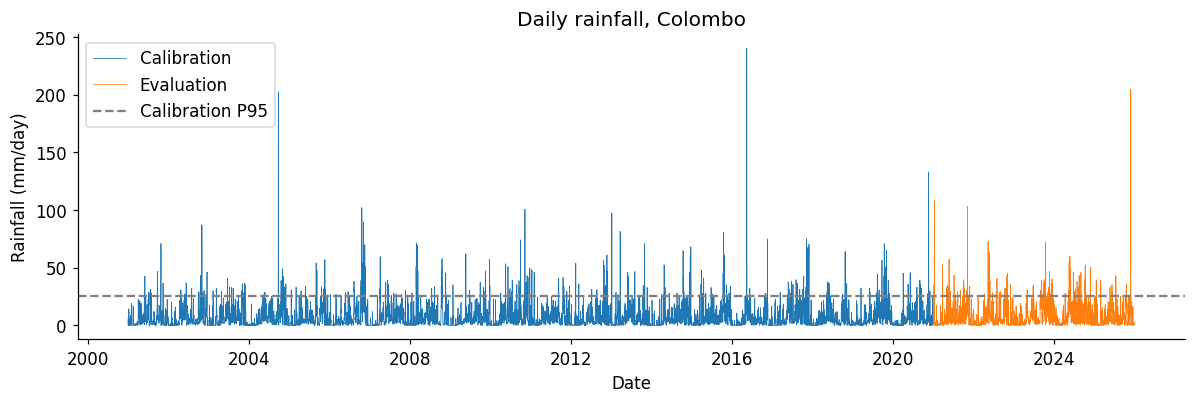

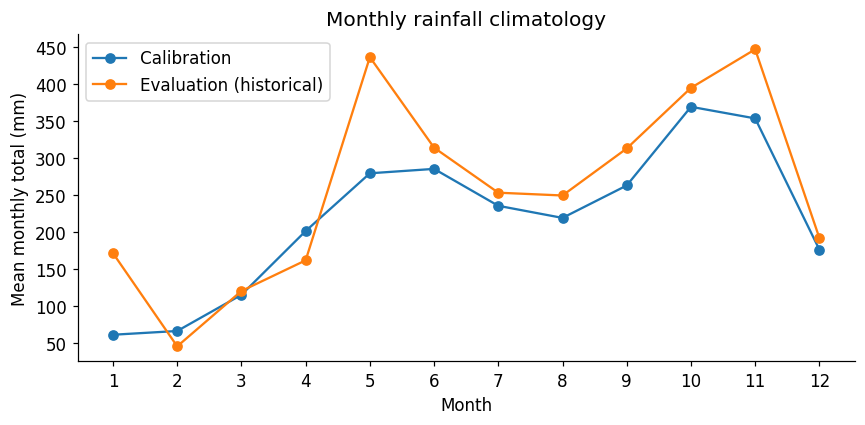

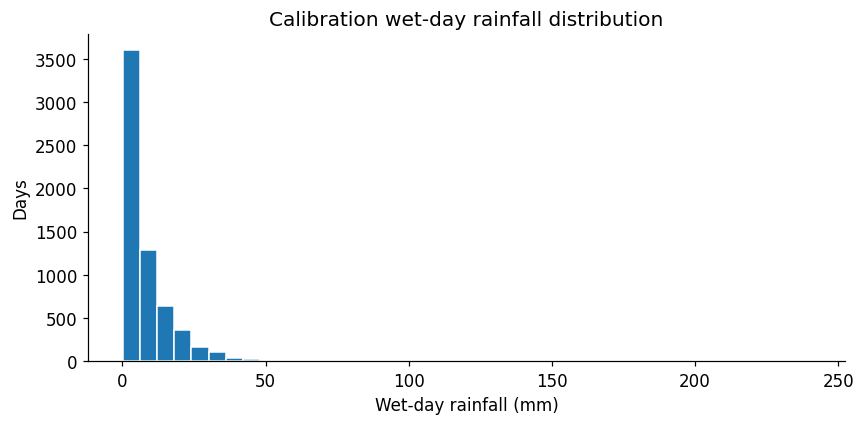

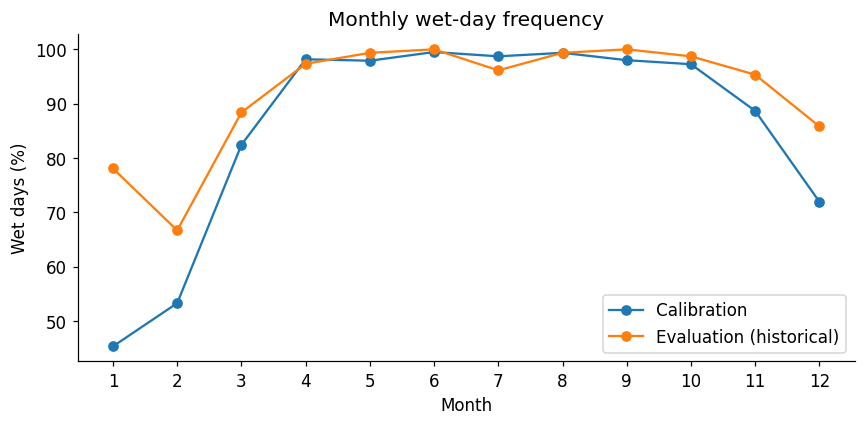

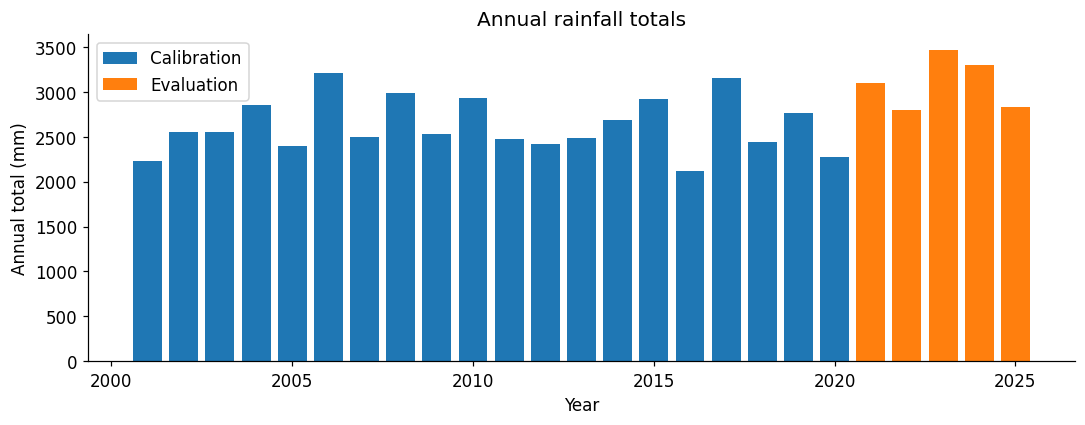

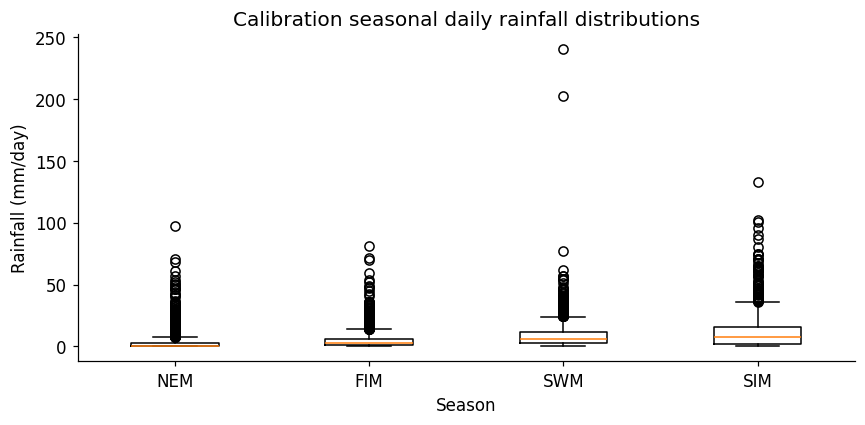

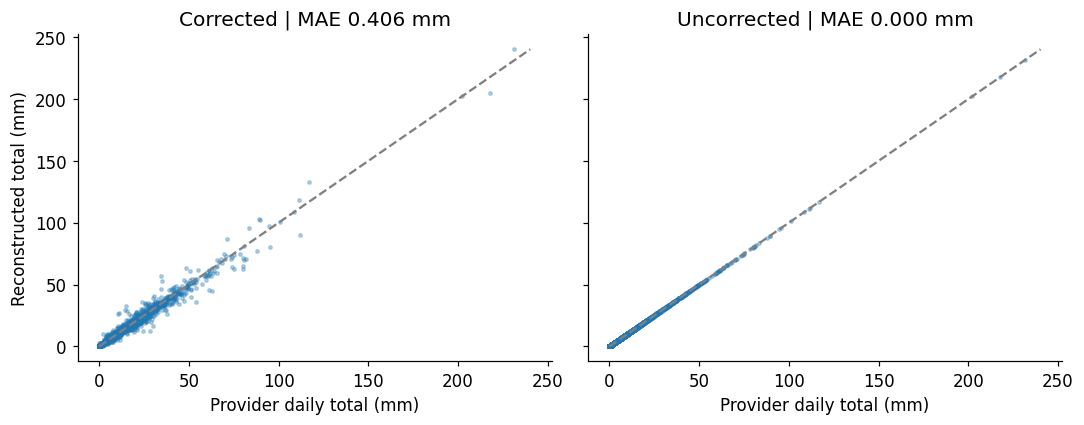

In [8]:
%%scientific
# C08
# Capture plotted numerical primitives, independent of raster rendering.
plt.style.use('default')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

def finish(fig, name):
    payload = []
    for ax in fig.axes:

        def arr(v):
            return np.asarray(v).tolist()
        payload.append({'lines': [[arr(l.get_xdata(orig=False)), arr(l.get_ydata(orig=False))] for l in ax.lines], 'images': [arr(im.get_array()) for im in ax.images], 'collections': [arr(col.get_offsets()) for col in ax.collections], 'rectangles': [[patch.get_x(), patch.get_y(), patch.get_width(), patch.get_height()] for patch in ax.patches if hasattr(patch, 'get_width')], 'paths': [arr(patch.get_path().vertices) for patch in ax.patches if not hasattr(patch, 'get_width')]})
    if int(name[1:3]) >= 15:
        for ax, entry in zip(fig.axes, payload):
            entry['collection_segments'] = [[arr(seg) for seg in collection.get_segments()] for collection in ax.collections if hasattr(collection, 'get_segments')]
            entry['collection_paths'] = [[arr(path.vertices) for path in collection.get_paths()] for collection in ax.collections]
    FIGURE_DATA[name] = payload
    fig.tight_layout()
    fig.savefig(OUTPUT / 'figures' / f'{name}.png', dpi=DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(cal.date, cal.rainfall_mm, lw=0.5, label='Calibration')
ax.plot(evaluation.date, evaluation.rainfall_mm, lw=0.5, label='Evaluation')
ax.axhline(q95, ls='--', color='gray', label='Calibration P95')
ax.set(ylabel='Rainfall (mm/day)', xlabel='Date', title='Daily rainfall, Colombo')
ax.legend()
finish(fig, 'F01_daily_rainfall')
fig, ax = plt.subplots(figsize=(8, 4))
for part, label in [(cal, 'Calibration'), (evaluation, 'Evaluation (historical)')]:
    monthly = part.groupby(['year', 'month']).rainfall_mm.sum().groupby('month').mean()
    ax.plot(monthly.index, monthly.values, marker='o', label=label)
ax.set(xticks=range(1, 13), xlabel='Month', ylabel='Mean monthly total (mm)', title='Monthly rainfall climatology')
ax.legend()
finish(fig, 'F02_monthly_climatology')
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cal.loc[cal.is_wet, 'rainfall_mm'], bins=40, edgecolor='white')
ax.set(xlabel='Wet-day rainfall (mm)', ylabel='Days', title='Calibration wet-day rainfall distribution')
finish(fig, 'F03_wet_day_histogram')
fig, ax = plt.subplots(figsize=(8, 4))
for part, label in [(cal, 'Calibration'), (evaluation, 'Evaluation (historical)')]:
    s = part.groupby('month').is_wet.mean() * 100
    ax.plot(s.index, s.values, marker='o', label=label)
ax.set(xticks=range(1, 13), xlabel='Month', ylabel='Wet days (%)', title='Monthly wet-day frequency')
ax.legend()
finish(fig, 'F04_monthly_wet_frequency')
fig, ax = plt.subplots(figsize=(10, 4))
for part, label in [(cal, 'Calibration'), (evaluation, 'Evaluation')]:
    s = part.groupby('year').rainfall_mm.sum()
    ax.bar(s.index, s.values, label=label)
ax.set(xlabel='Year', ylabel='Annual total (mm)', title='Annual rainfall totals')
ax.legend()
finish(fig, 'F05_annual_rainfall')
fig, ax = plt.subplots(figsize=(8, 4))
seasons = ['NEM', 'FIM', 'SWM', 'SIM']
ax.boxplot([cal.loc[cal.season == s, 'rainfall_mm'] for s in seasons])
ax.set(xticks=range(1, 5), xticklabels=seasons, ylabel='Rainfall (mm/day)', xlabel='Season', title='Calibration seasonal daily rainfall distributions')
finish(fig, 'F06_seasonal_distributions')
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
limit = comparison[['reference', 'corrected', 'uncorrected']].max().max()
for ax, col in zip(axs, ['corrected', 'uncorrected']):
    ax.scatter(comparison.reference, comparison[col], s=5, alpha=0.3)
    ax.plot([0, limit], [0, limit], ls='--', color='gray')
    ax.set(xlabel='Provider daily total (mm)', title=col.capitalize() + f" | MAE {metrics.loc[col, 'MAE_mm']:.3f} mm")
axs[0].set_ylabel('Reconstructed total (mm)')
finish(fig, 'F07_daily_aggregation_comparison')

### Calibration of rainfall occurrence
All fits below use only `cal`, the contiguous 2001–2020 record. For states 0 (dry) and 1 (wet), $\hat p_{ij}=n_{ij}/\sum_j n_{ij}$. The stationary distribution satisfies $\pi P=\pi$, with $\pi_1=p_{01}/(p_{01}+p_{10})$. Spell lengths under a homogeneous chain have geometric distributions on positive integers: $P(L_i=l)=p_{i,1-i}p_{ii}^{l-1}$ and $E[L_i]=1/p_{i,1-i}$. Exclude boundary-censored runs from empirical spell summaries. For BIC use identical 7,304 destination observations and conditional likelihoods, with 1 independent parameter for order zero and 2 for order one. Lower BIC is preferred.

In [9]:
%%scientific
# C09
from scipy import stats, optimize, integrate
from scipy.special import xlogy
assert len(cal) == 7305 and cal.date.min() == pd.Timestamp('2001-01-01') and (cal.date.max() == CAL_END)
assert cal.date.diff().iloc[1:].eq(pd.Timedelta(days=1)).all()
assert np.isclose(q95, 25.2, rtol=RTOL, atol=ATOL) and np.isclose(q99, 46.296, rtol=RTOL, atol=ATOL)
s = cal.is_wet.to_numpy(dtype=int)
pairs = pd.DataFrame({'previous': s[:-1], 'current': s[1:], 'season': cal.season.to_numpy()[1:]})

def transition_counts(pair):
    counts = np.zeros((2, 2), dtype=int)
    np.add.at(counts, (pair.previous.to_numpy(), pair.current.to_numpy()), 1)
    assert counts.sum() == len(pair) and (counts.sum(axis=1) > 0).all()
    matrix = counts / counts.sum(axis=1, keepdims=True)
    assert np.all((matrix >= 0) & (matrix <= 1)) and np.allclose(matrix.sum(axis=1), 1)
    return (counts, matrix)
N, P = transition_counts(pairs)
assert N.sum() == 7304
pi = np.array([P[1, 0], P[0, 1]]) / (P[0, 1] + P[1, 0])
assert np.all(pi >= 0) and np.isclose(pi.sum(), 1) and np.allclose(pi @ P, pi)
ll1 = xlogy(N, P).sum()
dest = N.sum(axis=0)
ll0 = xlogy(dest, dest / dest.sum()).sum()
occurrence_bic = pd.DataFrame({'order': [0, 1], 'log_likelihood': [ll0, ll1], 'parameters': [1, 2]})
occurrence_bic['BIC'] = -2 * occurrence_bic.log_likelihood + occurrence_bic.parameters * np.log(len(pairs))
transition_table = pd.DataFrame([{'from_state': i, 'to_state': j, 'count': N[i, j], 'probability': P[i, j]} for i in range(2) for j in range(2)])
transition_table.to_csv(PROCESSED_DIR / 'markov_transitions.csv', index=False)
occurrence_bic.to_csv(PROCESSED_DIR / 'occurrence_bic.csv', index=False)
display(transition_table, occurrence_bic)
print('Stationary dry/wet:', pi, 'Empirical wet frequency:', s.mean())
print('Transition and stationary assertions passed.')

,from_state,to_state,count,probability
0,0,0,670,0.655577
1,0,1,352,0.344423
2,1,0,352,0.056033
3,1,1,5930,0.943967


,order,log_likelihood,parameters,BIC
0,0,-2956.836554,1,5922.569286
1,1,-2014.438536,2,4046.669426


Stationary dry/wet: [0.13992333 0.86007667] Empirical wet frequency: 0.8600958247775496
Transition and stationary assertions passed.


In [10]:
%%scientific
# C10
# First and last runs may be censored; retain only complete interior spells.
boundaries = np.r_[0, np.flatnonzero(np.diff(s)) + 1, len(s)]
lengths = np.diff(boundaries)
states = s[boundaries[:-1]]
assert lengths.sum() == len(s)
spells = {i: lengths[1:-1][states[1:-1] == i] for i in (0, 1)}
spell_summary = pd.DataFrame([{'state': i, 'complete_spells': len(v), 'empirical_mean_days': v.mean(), 'median_days': np.median(v), 'max_days': v.max(), 'p95_days': np.quantile(v, 0.95), 'theoretical_mean_days': 1 / P[i, 1 - i]} for i, v in spells.items()])
spell_summary.to_csv(PROCESSED_DIR / 'spell_statistics.csv', index=False)
display(spell_summary)
print('Excluded endpoint runs:', lengths[[0, -1]])

,state,complete_spells,empirical_mean_days,median_days,max_days,p95_days,theoretical_mean_days
0,0,352,2.903409,2.0,18,10.0,2.903409
1,1,351,17.871795,4.0,245,106.5,17.846591


Excluded endpoint runs: [4 6]


### Lower-truncated intensity likelihood
For a parent density $f_\theta$ with CDF $F_\theta$, the wet-day density is $g_\theta(x)=f_\theta(x)/[1-F_\theta(\tau)]$ for $x\geq\tau=0.1$, and zero otherwise. Thus $\ell(\theta)=\sum_i\log f_\theta(x_i)-n\log\bar F_\theta(\tau)$. Use zero parent location, positive shape/scale via log parameters and survival functions for stable tail calculations. Exponential has one parameter, Gamma and log-normal two. Quantiles use the parent inverse survival function at $(1-u)\bar F(\tau)$. The Gamma conditional mean is $\alpha\beta\bar F_{\alpha+1,\beta}(\tau)/\bar F_{\alpha,\beta}(\tau)$. The exponential conditional mean is $\tau+\beta$; the log-normal conditional mean is $e^{\mu+\sigma^2/2}\Phi((\mu+\sigma^2-\log\tau)/\sigma)/\bar F(\tau)$. Fit with multiple deterministic starts; AIC/BIC are relative descriptive criteria, not absolute fit tests. Wet-day dependence and rounded data limit the interpretation of independent continuous likelihoods.

In [11]:
%%scientific
# C11
x = cal.loc[cal.is_wet, 'rainfall_mm'].to_numpy()
assert len(x) == s.sum() and np.all(x >= WET)

def parent(name, z):
    a = np.exp(z)
    if name == 'Gamma':
        return stats.gamma(a[0], loc=0, scale=a[1])
    if name == 'Exponential':
        return stats.expon(loc=0, scale=a[0])
    if name == 'Log-normal':
        return stats.lognorm(a[0], loc=0, scale=a[1])
    raise ValueError(name)

def fit_truncated(name, values):
    assert np.all(values >= WET)
    if name == 'Gamma':
        init = np.log(stats.gamma.fit(values, floc=0)[::2])
    elif name == 'Exponential':
        init = np.log([values.mean() - WET])
    else:
        init = np.log(stats.lognorm.fit(values, floc=0)[::2])

    def objective(z):
        d = parent(name, z)
        v = -(d.logpdf(values).sum() - len(values) * d.logsf(WET))
        return v if np.isfinite(v) else 1e+100
    starts = [init, init + 0.4, init - 0.4]
    results = [optimize.minimize(objective, z, method='L-BFGS-B', bounds=[OPT_BOUNDS] * len(z), options=OPT_SETTINGS) for z in starts]
    good = [r for r in results if r.success and np.isfinite(r.fun)]
    assert good, name
    best = min(good, key=lambda r: r.fun)
    assert best.fun <= objective(init) + 1e-06 and np.all(np.abs(best.x) < 9.99)
    d = parent(name, best.x)
    norm = d.sf(WET)
    assert norm > 0 and np.isclose(integrate.quad(lambda t: d.pdf(t) / norm, WET, np.inf)[0], 1, atol=1e-07)
    return (d, best, results)
names = ['Gamma', 'Exponential', 'Log-normal']
fits = {name: fit_truncated(name, x) for name in names}

def survival(d, t):
    return np.where(np.asarray(t) < WET, 1.0, d.sf(t) / d.sf(WET))

def quantile(d, u):
    return d.isf((1 - np.asarray(u)) * d.sf(WET))

def fit_row(name, fit, values):
    d, r, rs = fit
    pars = np.exp(r.x)
    k = len(pars)
    ll = -r.fun
    return {'distribution': name, 'n': len(values), 'shape': pars[0] if k == 2 else np.nan, 'scale_mm': pars[-1], 'log_likelihood': ll, 'AIC': 2 * k - 2 * ll, 'BIC': k * np.log(len(values)) - 2 * ll, 'converged': r.success, 'successful_starts': sum((t.success for t in rs)), 'iterations': r.nit, 'gradient_inf_norm': np.max(np.abs(r.jac)), 'normalisation': d.sf(WET)}
fit_table = pd.DataFrame([fit_row(name, fit, x) for name, fit in fits.items()])
fit_table.to_csv(PROCESSED_DIR / 'distribution_fits.csv', index=False)
display(fit_table)
print('All selected optimisations converged; truncated densities integrate to one.')

,distribution,n,shape,scale_mm,log_likelihood,AIC,BIC,converged,successful_starts,iterations,gradient_inf_norm,normalisation
0,Gamma,6283,0.708847,11.343819,-19389.890899,38783.781799,38797.273004,True,3,9,0.000364,0.961744
1,Exponential,6283,NaN,8.259239,-19548.501964,39099.003929,39105.749531,True,3,5,0.000000,0.987965
2,Log-normal,6283,1.352630,4.129066,-19702.582815,39409.165630,39422.656836,True,3,7,0.000364,0.997026


All selected optimisations converged; truncated densities integrate to one.


In [12]:
%%scientific
# C12
# Compare conditional wet-day quantiles and strict exceedance at fixed all-day thresholds.
qs = FIT_QUANTILES
thresholds = [q95, q99]
quantile_table = pd.DataFrame([{'distribution': name, 'quantile': u, 'observed_mm': np.quantile(x, u), 'fitted_mm': quantile(fit[0], u), 'error_mm': quantile(fit[0], u) - np.quantile(x, u)} for name, fit in fits.items() for u in qs])
tail_table = pd.DataFrame([{'distribution': name, 'threshold_mm': t, 'observed_wet_exceedance': np.mean(x > t), 'fitted_wet_exceedance': float(survival(fit[0], t)), 'error': float(survival(fit[0], t)) - np.mean(x > t)} for name, fit in fits.items() for t in thresholds])
quantile_table.to_csv(PROCESSED_DIR / 'distribution_quantiles.csv', index=False)
tail_table.to_csv(PROCESSED_DIR / 'distribution_tail_errors.csv', index=False)
display(quantile_table, tail_table)

,distribution,quantile,observed_mm,fitted_mm,error_mm
0,Gamma,0.90,20.000,20.521050,0.521050
1,Gamma,0.95,26.800,27.651072,0.851072
2,Gamma,0.99,48.754,44.643746,-4.110254
3,Exponential,0.90,20.000,19.117601,-0.882399
4,Exponential,0.95,26.800,24.842470,-1.957530
5,Exponential,0.99,48.754,38.135202,-10.618798
6,Log-normal,0.90,20.000,23.425170,3.425170
7,Log-normal,0.95,26.800,38.278269,11.478269
8,Log-normal,0.99,48.754,96.182837,47.428837


,distribution,threshold_mm,observed_wet_exceedance,fitted_wet_exceedance,error
0,Gamma,25.200,0.058093,0.063347,0.005253
1,Gamma,46.296,0.011778,0.008569,-0.003209
2,Exponential,25.200,0.058093,0.047882,-0.010212
3,Exponential,46.296,0.011778,0.003723,-0.008055
4,Log-normal,25.200,0.058093,0.090842,0.032749
5,Log-normal,46.296,0.011778,0.037088,0.025310


### Analytical benchmarks and seasonal preparation
Under the stationary homogeneous chain and independent conditional wet-day amounts, $E[R]=\pi_1 E[X\mid X\geq\tau]$ and $P(R>u)=\pi_1\bar F_\theta(u)/\bar F_\theta(\tau)$ for $u\geq\tau$. These are deterministic targets, not simulated estimates. Seasonal counts classify each adjacent transition by the destination date, including transitions crossing season boundaries. No disjoint blocks are joined. A seasonal chain is time-inhomogeneous, so separate stationary probabilities are not a global stationary distribution.

In [13]:
%%scientific
# C13
from scipy.special import gammaincc
G = fits['Gamma'][0]
alpha = G.args[0]
beta = G.kwds['scale']
wet_mean = alpha * beta * gammaincc(alpha + 1, WET / beta) / gammaincc(alpha, WET / beta)
quad_mean = integrate.quad(lambda t: t * G.pdf(t) / G.sf(WET), WET, np.inf)[0]
assert np.isclose(wet_mean, quad_mean, rtol=1e-08)
for t in thresholds:
    assert np.isclose(survival(G, t), integrate.quad(lambda v: G.pdf(v) / G.sf(WET), t, np.inf)[0], rtol=1e-08)
bench = pd.DataFrame([('stationary_wet_probability', pi[1], s.mean()), ('mean_wet_mm', wet_mean, x.mean()), ('expected_daily_mm', pi[1] * wet_mean, cal.model_rainfall_mm.mean()), ('mean_wet_spell_days', 1 / P[1, 0], spells[1].mean()), ('mean_dry_spell_days', 1 / P[0, 1], spells[0].mean()), ('daily_P95_exceedance', pi[1] * survival(G, q95), np.mean(cal.rainfall_mm > q95)), ('daily_P99_exceedance', pi[1] * survival(G, q99), np.mean(cal.rainfall_mm > q99))], columns=['metric', 'analytical', 'historical_calibration'])
bench.to_csv(PROCESSED_DIR / 'analytical_benchmarks.csv', index=False)
display(bench)
print('Analytical mean and exceedances independently checked by quadrature.')

,metric,analytical,historical_calibration
0,stationary_wet_probability,0.860077,0.860096
1,mean_wet_mm,8.359239,8.359239
2,expected_daily_mm,7.189587,7.189747
3,mean_wet_spell_days,17.846591,17.871795
4,mean_dry_spell_days,2.903409,2.903409
5,daily_P95_exceedance,0.054483,0.049966
6,daily_P99_exceedance,0.007370,0.010130


Analytical mean and exceedances independently checked by quadrature.


In [14]:
%%scientific
# C14
seasons = ['NEM', 'FIM', 'SWM', 'SIM']
seasonal_rows = []
seasonal_counts = []
for season in seasons:
    counts, matrix = transition_counts(pairs[pairs.season == season])
    values = cal.loc[cal.is_wet & cal.season.eq(season), 'rainfall_mm'].to_numpy()
    fit = fit_truncated('Gamma', values)
    row = fit_row('Gamma', fit, values)
    row['season'] = season
    for i in (0, 1):
        for j in (0, 1):
            row[f'n{i}{j}'] = counts[i, j]
            row[f'p{i}{j}'] = matrix[i, j]
    seasonal_rows.append(row)
    seasonal_counts.append(counts)
assert np.array_equal(np.sum(seasonal_counts, axis=0), N)
seasonal = pd.DataFrame(seasonal_rows)
seasonal.to_csv(PROCESSED_DIR / 'seasonal_parameters.csv', index=False)
display(seasonal)
print('Seasonal counts exactly partition the homogeneous counts; all fits converged.')

,distribution,n,shape,scale_mm,log_likelihood,AIC,BIC,converged,successful_starts,iterations,gradient_inf_norm,normalisation,season,n00,p00,n01,p01,n10,p10,n11,p11
0,Gamma,1028,0.258186,16.126728,-2612.187012,5228.374024,5238.244764,True,3,10,0.000045,0.702860,NEM,566,0.727506,212,0.272494,211,0.205653,815,0.794347
1,Gamma,1100,0.470697,10.715368,-2905.691818,5815.383637,5825.389768,True,3,10,0.000045,0.875282,FIM,54,0.428571,72,0.571429,66,0.060329,1028,0.939671
2,Gamma,3020,1.166920,7.233505,-9428.199965,18860.399930,18872.425954,True,3,9,0.000182,0.993796,SWM,10,0.256410,29,0.743590,30,0.009930,2991,0.990070
3,Gamma,1135,0.795474,15.705930,-3999.702066,8003.404133,8013.472909,True,3,9,0.000091,0.980800,SIM,40,0.506329,39,0.493671,45,0.039439,1096,0.960561


Seasonal counts exactly partition the homogeneous counts; all fits converged.


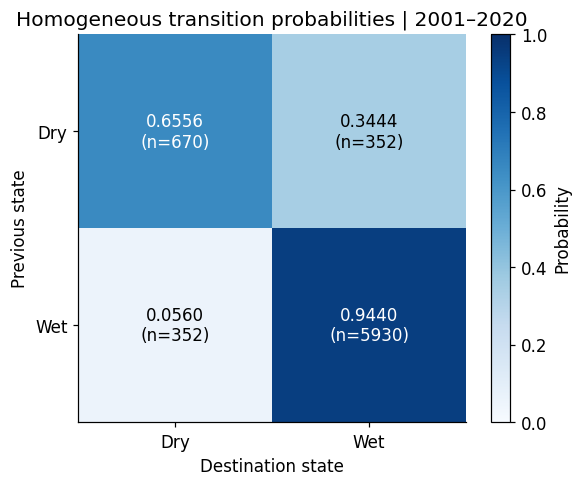

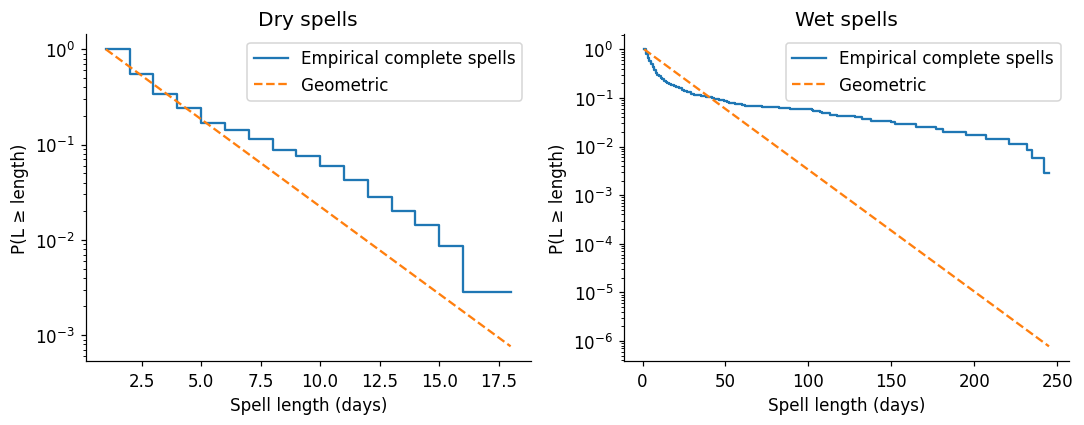

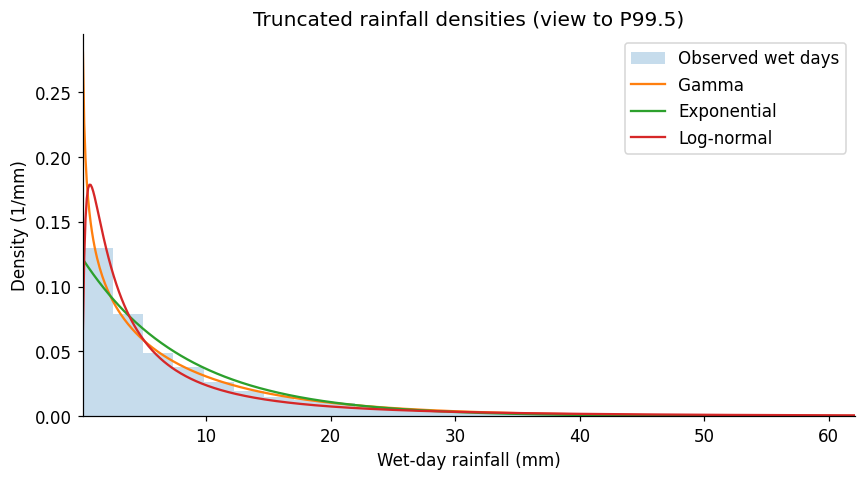

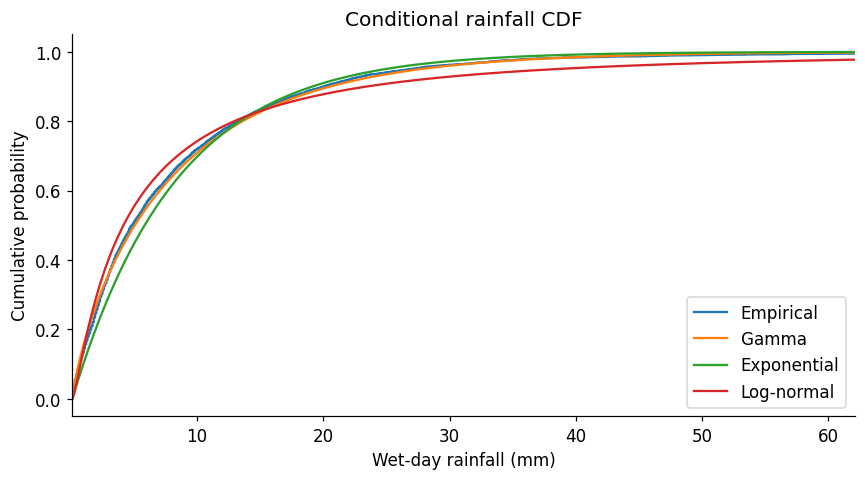

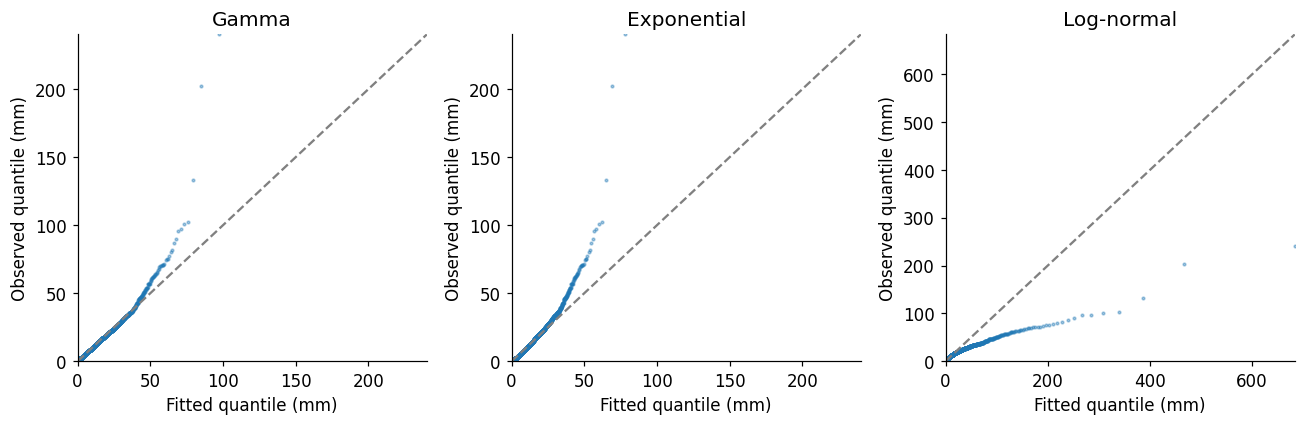

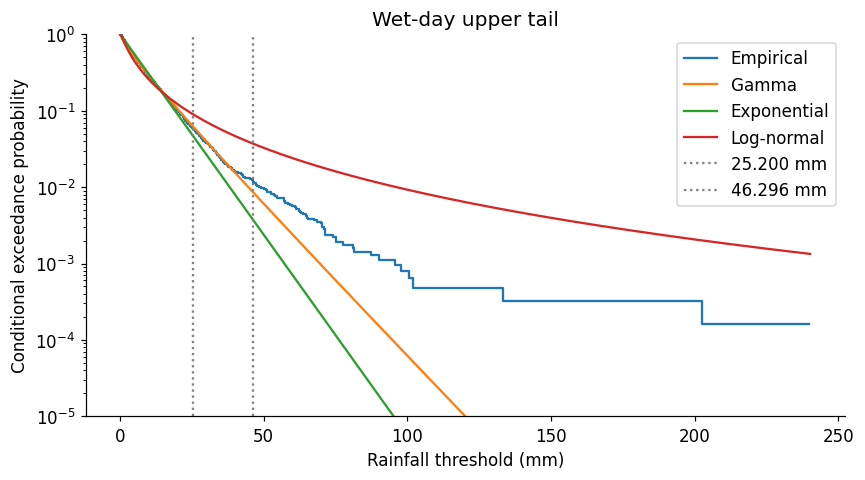

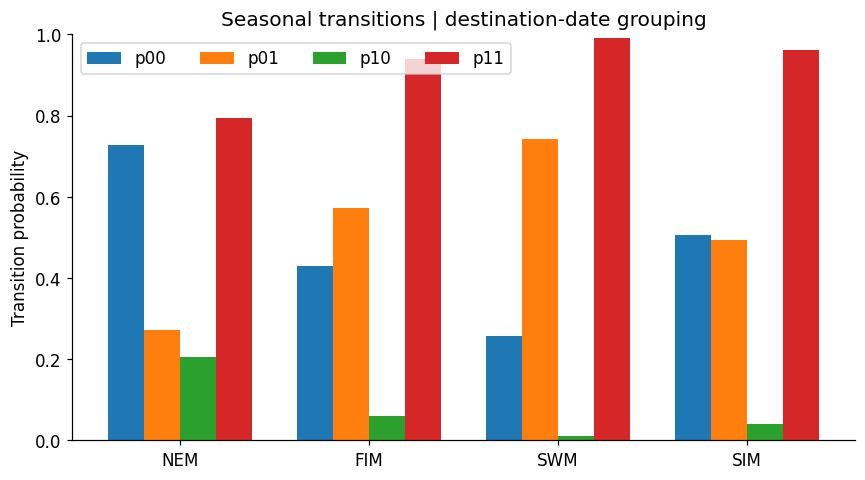

In [15]:
%%scientific
# C15
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(P, vmin=0, vmax=1, cmap='Blues')
for i in (0, 1):
    for j in (0, 1):
        ax.text(j, i, f'{P[i, j]:.4f}\n(n={N[i, j]})', ha='center', va='center', color='white' if P[i, j] > 0.5 else 'black')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Dry', 'Wet'], yticklabels=['Dry', 'Wet'], xlabel='Destination state', ylabel='Previous state', title='Homogeneous transition probabilities | 2001–2020')
fig.colorbar(im, ax=ax, label='Probability')
finish(fig, 'F08_transition_matrix')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, ax in enumerate(axes):
    v = spells[i]
    k = np.arange(1, max(v) + 1)
    ax.step(k, [np.mean(v >= t) for t in k], where='post', label='Empirical complete spells')
    ax.plot(k, stats.geom.sf(k - 1, P[i, 1 - i]), label='Geometric', ls='--')
    ax.set(yscale='log', xlabel='Spell length (days)', ylabel='P(L ≥ length)', title=['Dry spells', 'Wet spells'][i])
    ax.legend()
finish(fig, 'F09_spell_distributions')
grid = np.linspace(WET, np.quantile(x, 0.995), 600)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(x, bins=np.linspace(WET, x.max(), 100), density=True, alpha=0.25, label='Observed wet days')
for name, (d, *_) in fits.items():
    ax.plot(grid, d.pdf(grid) / d.sf(WET), label=name)
ax.set(xlim=(WET, grid[-1]), xlabel='Wet-day rainfall (mm)', ylabel='Density (1/mm)', title='Truncated rainfall densities (view to P99.5)')
ax.legend()
finish(fig, 'F10_fitted_densities')
fig, ax = plt.subplots(figsize=(8, 4.5))
sx = np.sort(x)
ax.step(sx, np.arange(1, len(x) + 1) / len(x), where='post', label='Empirical')
for name, (d, *_) in fits.items():
    ax.plot(grid, 1 - survival(d, grid), label=name)
ax.set(xlim=(WET, grid[-1]), xlabel='Wet-day rainfall (mm)', ylabel='Cumulative probability', title='Conditional rainfall CDF')
ax.legend()
finish(fig, 'F11_fitted_cdfs')
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
u = (np.arange(1, len(x) + 1) - 0.5) / len(x)
for ax, (name, (d, *_)) in zip(axes, fits.items()):
    theoretical = quantile(d, u)
    lim = max(sx.max(), theoretical.max())
    ax.scatter(theoretical, sx, s=3, alpha=0.4)
    ax.plot([0, lim], [0, lim], ls='--', color='gray')
    ax.set(xlabel='Fitted quantile (mm)', ylabel='Observed quantile (mm)', title=name, xlim=(0, lim), ylim=(0, lim))
finish(fig, 'F12_distribution_qq')
fig, ax = plt.subplots(figsize=(8, 4.5))
tgrid = np.linspace(WET, x.max(), 500)
empirical = np.array([np.mean(x > t) for t in tgrid])
ax.step(tgrid[empirical > 0], empirical[empirical > 0], where='post', label='Empirical')
for name, (d, *_) in fits.items():
    ax.plot(tgrid, survival(d, tgrid), label=name)
for t in thresholds:
    ax.axvline(t, ls=':', color='gray', label=f'{t:.3f} mm')
ax.set(yscale='log', ylim=(1e-05, 1), xlabel='Rainfall threshold (mm)', ylabel='Conditional exceedance probability', title='Wet-day upper tail')
ax.legend()
finish(fig, 'F13_upper_tail')
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(4)
width = 0.19
for k, key in enumerate(['p00', 'p01', 'p10', 'p11']):
    ax.bar(pos + (k - 1.5) * width, seasonal[key], width, label=key)
ax.set(xticks=pos, xticklabels=seasons, ylim=(0, 1), ylabel='Transition probability', title='Seasonal transitions | destination-date grouping')
ax.legend(ncol=4)
finish(fig, 'F14_seasonal_transitions')

### Calibration findings (local execution)
The first-order conditional BIC (4046.67) is lower than order zero (5922.57) by 1875.90. This is evidence of dependence, not proof that one-day memory is sufficient. Complete wet spells have median 4 days, mean 17.87 days and maximum 245 days; the geometric model has mean 17.85 days but does not reproduce the observed spread well. Seasonal heterogeneity can generate long persistence even if transitions are first order within each season. The SWM dry-origin row has only 39 transitions, so its estimate warrants particular caution.

Gamma gives the lowest AIC and BIC among the three candidates. Conditional wet-day P99 is underestimated (44.64 versus 48.754 mm); the log-normal overestimates it (96.18 mm). Gamma gives daily exceedance probabilities 5.4483% and 0.7370% at the fixed all-day P95 and P99, respectively, compared with historical 4.9966% and 1.0130%. This is a fitted-model discrepancy, not a simulation failure. Retain Gamma as approved and investigate tail adequacy before claiming reliable extremes. Fitted likelihoods use a continuous approximation to rounded rainfall values. No fitted-distribution p-values are treated as conclusive. Numerical checks passed locally; independent Colab verification remains pending; Monte Carlo verification follows below.

### Reproducibility inventory
All outputs are regenerated from checksum-validated raw inputs. The manifest identifies producing cells. Figure primitives are captured separately from PNGs because fonts, antialiasing and rasterisation can differ across platforms. C17–C23 use namespaced SeedSequence child streams for independent experiments. C23 extends the manifest to all generated files.

In [16]:
%%scientific
# C16
# Output inventory is declarative; all listed scientific outputs are generated above.
manifest = pd.DataFrame([{'path': 'data/processed/processed_daily.csv', 'cell': 'C05', 'description': 'processed daily'}, {'path': 'data/processed/calibration_daily.csv', 'cell': 'C05', 'description': 'calibration daily'}, {'path': 'data/processed/evaluation_daily.csv', 'cell': 'C05', 'description': 'evaluation daily'}, {'path': 'data/processed/summary.csv', 'cell': 'C07', 'description': 'summary'}, {'path': 'data/processed/aggregation_metrics.csv', 'cell': 'C07', 'description': 'aggregation metrics'}, {'path': 'data/processed/markov_transitions.csv', 'cell': 'C09', 'description': 'markov transitions'}, {'path': 'data/processed/occurrence_bic.csv', 'cell': 'C09', 'description': 'occurrence bic'}, {'path': 'data/processed/spell_statistics.csv', 'cell': 'C10', 'description': 'spell statistics'}, {'path': 'data/processed/distribution_fits.csv', 'cell': 'C11', 'description': 'distribution fits'}, {'path': 'data/processed/distribution_quantiles.csv', 'cell': 'C12', 'description': 'distribution quantiles'}, {'path': 'data/processed/distribution_tail_errors.csv', 'cell': 'C12', 'description': 'distribution tail errors'}, {'path': 'data/processed/analytical_benchmarks.csv', 'cell': 'C13', 'description': 'analytical benchmarks'}, {'path': 'data/processed/seasonal_parameters.csv', 'cell': 'C14', 'description': 'seasonal parameters'}, {'path': 'data/processed/output_manifest.csv', 'cell': 'C16', 'description': 'output manifest'}, {'path': 'data/processed/runtime_versions.csv', 'cell': 'C16', 'description': 'runtime versions'}, {'path': 'figures/F01_daily_rainfall.png', 'cell': 'C08', 'description': 'daily rainfall'}, {'path': 'figures/F02_monthly_climatology.png', 'cell': 'C08', 'description': 'monthly climatology'}, {'path': 'figures/F03_wet_day_histogram.png', 'cell': 'C08', 'description': 'wet day histogram'}, {'path': 'figures/F04_monthly_wet_frequency.png', 'cell': 'C08', 'description': 'monthly wet frequency'}, {'path': 'figures/F05_annual_rainfall.png', 'cell': 'C08', 'description': 'annual rainfall'}, {'path': 'figures/F06_seasonal_distributions.png', 'cell': 'C08', 'description': 'seasonal distributions'}, {'path': 'figures/F07_daily_aggregation_comparison.png', 'cell': 'C08', 'description': 'daily aggregation comparison'}, {'path': 'figures/F08_transition_matrix.png', 'cell': 'C15', 'description': 'transition matrix'}, {'path': 'figures/F09_spell_distributions.png', 'cell': 'C15', 'description': 'spell distributions'}, {'path': 'figures/F10_fitted_densities.png', 'cell': 'C15', 'description': 'fitted densities'}, {'path': 'figures/F11_fitted_cdfs.png', 'cell': 'C15', 'description': 'fitted cdfs'}, {'path': 'figures/F12_distribution_qq.png', 'cell': 'C15', 'description': 'distribution qq'}, {'path': 'figures/F13_upper_tail.png', 'cell': 'C15', 'description': 'upper tail'}, {'path': 'figures/F14_seasonal_transitions.png', 'cell': 'C15', 'description': 'seasonal transitions'}, {'path': 'data/processed/figure_data.json', 'cell': 'C16', 'description': 'Numerical plotting primitives for regression comparison'}])
manifest.loc[len(manifest)] = ['data/processed/model_parameters.json', 'C16', 'Calibrated homogeneous and seasonal model parameters for future consumers']
model_export = {'schema_version': 1, 'calibration_start': START.date().isoformat(), 'calibration_end': CAL_END.date().isoformat(), 'seed': SEED, 'wet_threshold_mm': WET, 'extreme_threshold_mm': float(q95), 'secondary_threshold_mm': float(q99), 'state_order': ['dry', 'wet'], 'homogeneous': {'transition_matrix': P.tolist(), 'stationary_distribution': pi.tolist(), 'amount_distribution': {'name': 'lower_truncated_gamma', 'shape': float(alpha), 'scale_mm': float(beta), 'lower_mm': WET, 'parent_location_mm': 0}}, 'seasonal': {row['season']: {'transition_matrix': [[float(row['p00']), float(row['p01'])], [float(row['p10']), float(row['p11'])]], 'amount_distribution': {'name': 'lower_truncated_gamma', 'shape': float(row['shape']), 'scale_mm': float(row['scale_mm']), 'lower_mm': WET, 'parent_location_mm': 0}} for row in seasonal_rows}}
(PROCESSED_DIR / 'model_parameters.json').write_text(json.dumps(model_export, indent=2, allow_nan=False) + '\n', encoding='utf-8')
(PROCESSED_DIR / 'figure_data.json').write_text(json.dumps(FIGURE_DATA, default=str, sort_keys=True), encoding='utf-8')
actual_versions = {k: importlib.metadata.version(k) for k in PINS}
assert actual_versions == PINS
runtime = pd.DataFrame([{'component': 'python', 'version': platform.python_version()}, *[{'component': k, 'version': v} for k, v in actual_versions.items()], *[{'component': k, 'version': importlib.metadata.version(k)} for k in ('ipython', 'matplotlib-inline')]])
runtime.to_csv(PROCESSED_DIR / 'runtime_versions.csv', index=False)
manifest.to_csv(PROCESSED_DIR / 'output_manifest.csv', index=False)
assert all(((OUTPUT / path).is_file() for path in manifest.path))
assert len(FIGURE_DATA) == 14
print('Generated outputs:', len(manifest), '| elapsed seconds:', round(time.perf_counter() - RUN_START, 2))
display(runtime)

Generated outputs: 31 | elapsed seconds: 8.66


,component,version
0,python,3.13.5
1,numpy,2.3.5
2,pandas,2.2.3
3,scipy,1.17.0
4,matplotlib,3.10.8
5,ipython,9.14.0
6,matplotlib-inline,0.2.2


### Homogeneous generator
For origin state $i$, a uniform draw below $p_{i1}$ yields a wet destination. Wet amounts use $X=\bar F^{-1}((1-U)\bar F(\tau))$; dry amounts are zero. Initial state denotes the preceding day. Independent child SeedSequences are namespaced by experiment.

In [17]:
%%scientific
# C17
from scipy.special import gammainccinv
def validate(matrix, shape, scale, lower):
    """Check the model domain before sampling."""
    assert matrix.shape == (2,2), 'Matrix must be 2 by 2'
    assert np.isfinite(matrix).all() and ((matrix>=0)&(matrix<=1)).all(), 'Invalid probability'
    np.testing.assert_allclose(matrix.sum(axis=1),1,rtol=0,atol=ATOL)
    assert np.isfinite([shape,scale,lower]).all() and min(shape,scale,lower)>0, 'Invalid Gamma parameters'
def stationary(matrix):
    """Unique stationary distribution; reject two absorbing classes."""
    denominator=matrix[0,1]+matrix[1,0]
    if denominator==0:
        raise ValueError('No unique stationary distribution')
    return np.array([matrix[1,0],matrix[0,1]])/denominator
def generate_states(matrix, uniforms, origins):
    """Generate chronologically dependent states across independent trajectories."""
    states=np.empty(uniforms.shape,dtype=np.int8)
    previous=origins.copy()
    for day in range(uniforms.shape[1]):
        previous=(uniforms[:,day]<matrix[previous,1]).astype(np.int8)
        states[:,day]=previous
    return states
def sample_amounts(uniforms, shape, scale, lower):
    """Exact conditional inverse survival sampling, without clipping."""
    uniforms = np.asarray(uniforms)
    assert np.isfinite(uniforms).all() and ((uniforms >= 0) & (uniforms < 1)).all(), "Uniforms must lie in [0, 1)"
    values = scale * gammainccinv(shape, (1 - uniforms) * gammaincc(shape, lower / scale))
    # Exact zero uniform maps to the lower endpoint, avoiding inverse-roundoff.
    return np.where(uniforms == 0, lower, values)
def ensemble(days:int,reps:int,matrix:np.ndarray,shape:float,scale:float,lower:float,seed:int=SEED,namespace:tuple=(),initial=None):
    """Initial state denotes the day before the first simulated day."""
    validate(matrix,shape,scale,lower)
    assert days>0 and reps>0 and initial in (None,0,1)
    children=np.random.SeedSequence(seed,spawn_key=namespace).spawn(reps)
    assert len({c.spawn_key for c in children})==reps
    u=np.empty((reps,days))
    v=np.empty_like(u)
    origins=np.empty(reps,dtype=np.int8)
    prob=stationary(matrix)[1] if initial is None else initial
    for i,child in enumerate(children):
        generator=np.random.default_rng(child)
        origins[i]=generator.random()<prob
        u[i]=generator.random(days)
        v[i]=generator.random(days)
    states=generate_states(matrix,u,origins)
    amounts=np.zeros(states.shape)
    wet=states==1
    amounts[wet]=sample_amounts(v[wet],shape,scale,lower)
    return states,amounts
def trajectory(days, matrix, shape, scale, lower, seed=SEED, initial=None):
    """Generate a single rainfall trajectory."""
    states,amounts=ensemble(days,1,matrix,shape,scale,lower,seed,initial=initial)
    return states[0],amounts[0]
def complete_spells(states,state):
    """Exclude potentially censored first and last spells."""
    boundaries=np.r_[0,np.flatnonzero(np.diff(states))+1,len(states)]
    return np.diff(boundaries)[1:-1][states[boundaries[:-1]][1:-1]==state]
def trajectory_stats(states,amounts,primary,secondary):
    """Compute one observation per independent trajectory."""
    count=states.sum(axis=1)
    result=pd.DataFrame(dict(stationary_wet_probability=states.mean(axis=1),expected_daily_mm=amounts.mean(axis=1),mean_wet_mm=np.divide(amounts.sum(axis=1),count,out=np.full(len(states),np.nan),where=count>0),daily_P95_exceedance=(amounts>primary).mean(axis=1),daily_P99_exceedance=(amounts>secondary).mean(axis=1)))
    for state,label in [(0,'dry'),(1,'wet')]:
        runs=[complete_spells(row,state) for row in states]
        result[f'mean_{label}_spell_days']=[v.mean() if len(v) else np.nan for v in runs]
    return result
def uncertainty(values):
    """Student-t confidence interval and empirical trajectory prediction interval."""
    values=np.asarray(values,dtype=float)
    values=values[np.isfinite(values)]
    n=len(values)
    assert n>=2
    mean=values.mean()
    se=values.std(ddof=1)/np.sqrt(n)
    half=stats.t.ppf((1 + EXPERIMENT["confidence"]) / 2, n-1)*se
    lo,hi=np.quantile(values,[.025,.975])
    return dict(n=n,mean=mean,mcse=se,ci_low=mean-half,ci_high=mean+half,pi_low=lo,pi_high=hi)
MODEL=(P,alpha,beta,WET)

In [18]:
%%scientific
# C18
checks=[]
def check(name,condition):
    assert condition,name
    checks.append(dict(test=name,outcome='PASS'))
for label,bad in [('dimensions',np.ones((3,3))),('bounds',np.array([[1.1,-.1],[0,1]])),('row sums',np.ones((2,2)))]:
    try:
        validate(bad,alpha,beta,WET)
    except AssertionError:
        check(label,True)
    else:
        check(label,False)
try:
    validate(P,-1,beta,WET)
except AssertionError:
    check('invalid Gamma rejected',True)
else:
    check('invalid Gamma rejected',False)
for initial in (0,1):
    st,am=ensemble(12,3,np.eye(2),alpha,beta,WET,initial=initial)
    check(f'absorbing {initial}',(st==initial).all() and ((am==0).all() if initial==0 else (am>=WET).all()))
try:
    stationary(np.eye(2))
except ValueError:
    check('nonunique stationary rejected',True)
else:
    check('nonunique stationary rejected',False)
st,am=ensemble(12,3,np.array([[0,1],[1,0]]),alpha,beta,WET,initial=0)
check('alternation',(st==np.tile([1,0],6)).all())
u=np.array([[.1,.7,.2,.9]])
check('Bernoulli identical rows',np.array_equal(generate_states(np.array([[.6,.4],[.6,.4]]),u,np.array([0])),(u<.4).astype(int)))
a,b=ensemble(200,4,*MODEL,namespace=(0,))
c,d=ensemble(200,4,*MODEL,namespace=(0,))
e,f=ensemble(200,4,*MODEL,seed=SEED+1,namespace=(0,))
check('output dimensions',a.shape==b.shape==(4,200))
check('binary states',np.isin(a,[0,1]).all())
check('finite nonnegative amounts',np.isfinite(b).all() and (b>=0).all())
check('dry zero and wet support',(b[a==0]==0).all() and (b[a==1]>=WET).all())
check('same seed',np.array_equal(a,c) and np.array_equal(b,d))
check('different seed',not np.array_equal(b,f))
check('distinct child streams',len({v.spawn_key for v in np.random.SeedSequence(SEED).spawn(4)})==4 and not np.array_equal(b[0],b[1]))
check('known spells',np.array_equal(complete_spells(np.array([0,1,1,0,0,1,0]),1),[2,1]) and np.array_equal(complete_spells(np.array([0,1,1,0,0,1,0]),0),[2]))
check('strict exceedance',(np.array([0,2,3,0,0,4,0])>3).sum()==1)
test_uniforms = np.array([0., .01, .25, .5, .9, .999])
test_amounts = sample_amounts(test_uniforms, alpha, beta, WET)
check('inverse survival identity and support', (test_amounts >= WET).all() and np.allclose(G.sf(test_amounts) / G.sf(WET), 1-test_uniforms, rtol=RTOL, atol=ATOL))
check('unique absorbing stationary law', np.array_equal(stationary(np.array([[1.,0.],[.1,.9]])), [1.,0.]) and np.array_equal(stationary(np.array([[.9,.1],[0.,1.]])), [0.,1.]))
check('periodic stationary law', np.allclose(stationary(np.array([[0.,1.],[1.,0.]])), [.5,.5]))
pd.DataFrame(checks).to_csv(PROCESSED_DIR/'simulation_verification.csv',index=False)
display(pd.DataFrame(checks))

,test,outcome
0,dimensions,PASS
1,bounds,PASS
2,row sums,PASS
3,invalid Gamma rejected,PASS
4,absorbing 0,PASS
5,absorbing 1,PASS
6,nonunique stationary rejected,PASS
7,alternation,PASS
8,Bernoulli identical rows,PASS
9,output dimensions,PASS


### Analytical verification
For independent trajectory statistics $Y_i$, MCSE is $s_Y/\sqrt{N}$. Student-t confidence intervals estimate expectations; empirical quantiles describe trajectory variability. Four MCSE is a conservative approximate simultaneous verification band for seven metrics. Complete-spell averages may have finite-length bias. All intervals condition on fitted parameters.

For seven normal-approximation comparisons, a four-MCSE band has an approximate union-bound false rejection probability below 0.05% when biases are negligible. Finite-trajectory spell means can be biased by censoring and random spell counts; the band is not a proof. Annual risk uses separate 365-day independent trajectories and exact binomial confidence intervals, including all-success samples.

In [19]:
%%scientific
# C19
verification_states,verification_amounts=ensemble(EXPERIMENT['verification_days'],EXPERIMENT['verification_reps'],*MODEL,namespace=(1,))
verification_stats=trajectory_stats(verification_states,verification_amounts,q95,q99)
rows=[]
for row in bench.itertuples(index=False):
    result=uncertainty(verification_stats[row.metric])
    error=abs(result['mean']-row.analytical)
    tolerance=EXPERIMENT['sigma']*result['mcse']+ATOL
    rows.append(dict(metric=row.metric,analytical=row.analytical,**result,absolute_error=error,relative_error=error/abs(row.analytical),tolerance=tolerance,passed=error<=tolerance))
analytical_mc=pd.DataFrame(rows)
analytical_mc.to_csv(PROCESSED_DIR/'monte_carlo_analytical.csv',index=False)
display(analytical_mc)
# A failure is retained as evidence rather than tuning the seed or tolerance.
print('Analytical checks passed:',analytical_mc.passed.sum(),'of',len(analytical_mc))
# Annual variability requires separate independent one-year trajectories.
annual_states, annual_amounts = ensemble(365, EXPERIMENT['annual_reps'], *MODEL, namespace=(4,))
annual_values = {'annual_total_mm':annual_amounts.sum(axis=1), 'annual_maximum_mm':annual_amounts.max(axis=1),
                 'annual_probability_at_least_one_P95':(annual_amounts>q95).any(axis=1),
                 'annual_probability_at_least_one_P99':(annual_amounts>q99).any(axis=1)}
annual_rows = []
for metric, values in annual_values.items():
    row = uncertainty(values)
    method = 'Student-t'
    if 'probability' in metric:
        interval = stats.binomtest(int(values.sum()), len(values)).proportion_ci(confidence_level=EXPERIMENT['confidence'], method='exact')
        row.update(ci_low=interval.low, ci_high=interval.high)
        method = 'Exact binomial across independent annual trajectories'
    annual_rows.append(dict(metric=metric, **row, ci_method=method))
annual_uncertainty = pd.DataFrame(annual_rows)
annual_uncertainty.to_csv(PROCESSED_DIR/'annual_simulation_uncertainty.csv', index=False)
display(annual_uncertainty)
print('A degenerate annual-event empirical interval does not prove certainty; exact binomial CI shown.')


,metric,analytical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,relative_error,tolerance,passed
0,stationary_wet_probability,0.860077,600,0.860922,0.000464,0.860012,0.861833,0.838897,0.881925,0.000846,0.000983,0.001854,True
1,mean_wet_mm,8.359239,600,8.351551,0.006857,8.338083,8.365018,8.028334,8.684479,0.007689,0.000920,0.027430,True
2,expected_daily_mm,7.189587,600,7.190130,0.007222,7.175948,7.204313,6.857174,7.565562,0.000544,0.000076,0.028886,True
3,mean_wet_spell_days,17.846591,600,17.932751,0.055988,17.822795,18.042707,15.557814,20.702640,0.086160,0.004828,0.223951,True
4,mean_dry_spell_days,2.903409,600,2.895438,0.007328,2.881046,2.909830,2.556814,3.237433,0.007971,0.002745,0.029313,True
5,daily_P95_exceedance,0.054483,600,0.054398,0.000153,0.054098,0.054698,0.047384,0.061651,0.000085,0.001566,0.000611,True
6,daily_P99_exceedance,0.007370,600,0.007405,0.000059,0.007290,0.007521,0.004932,0.010411,0.000036,0.004837,0.000234,True


Analytical checks passed: 7 of 7


,metric,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,ci_method
0,annual_total_mm,1000,2618.566447,6.357629,2606.090608,2631.042286,2245.138050,3020.677193,Student-t
1,annual_maximum_mm,1000,62.630615,0.424152,61.798283,63.462946,42.268203,97.183229,Student-t
2,annual_probability_at_least_one_P95,1000,1.000000,0.000000,0.996318,1.000000,1.000000,1.000000,Exact binomial across independent annual traje...
3,annual_probability_at_least_one_P99,1000,0.928000,0.008178,0.910184,0.943241,0.000000,1.000000,Exact binomial across independent annual traje...


A degenerate annual-event empirical interval does not prove certainty; exact binomial CI shown.


### Convergence
Each replication count uses 20 independent batches of 365-day trajectories. Log RMSE versus log N estimates the convergence slope; N counts independent trajectories, not daily observations.

In [20]:
%%scientific
# C20
rows=[]
timings=[]
for count in EXPERIMENT['counts']:
    for batch in range(EXPERIMENT['batches']):
        started=time.perf_counter()
        st,am=ensemble(EXPERIMENT['convergence_days'],count,*MODEL,namespace=(2,count,batch))
        for metric,value in [('stationary_wet_probability',st.mean(axis=1)),('expected_daily_mm',am.mean(axis=1)),('daily_P95_exceedance',(am>q95).mean(axis=1))]:
            result=uncertainty(value)
            target=bench.set_index('metric').loc[metric,'analytical']
            rows.append(dict(replications=count,batch=batch,metric=metric,error=result['mean']-target,mcse=result['mcse'],ci_width=result['ci_high']-result['ci_low']))
        timings.append(dict(replications=count,batch=batch,seconds=time.perf_counter()-started))
convergence_batches=pd.DataFrame(rows)
convergence=convergence_batches.groupby(['metric','replications']).agg(mae=('error',lambda v:abs(v).mean()),rmse=('error',lambda v:np.sqrt(np.mean(v*v))),mean_mcse=('mcse','mean'),mean_ci_width=('ci_width','mean')).reset_index()
slopes=pd.DataFrame([dict(metric=metric,slope=np.polyfit(np.log(group.replications),np.log(group.rmse),1)[0]) for metric,group in convergence.groupby('metric')])
for name,table in [('convergence_batches',convergence_batches),('convergence_results',convergence),('convergence_slopes',slopes),('convergence_timing',pd.DataFrame(timings))]:
    table.to_csv(PROCESSED_DIR/f'{name}.csv',index=False)
display(convergence,slopes)

,metric,replications,mae,rmse,mean_mcse,mean_ci_width
0,daily_P95_exceedance,25,0.002013,0.002400,0.002517,0.010392
1,daily_P95_exceedance,50,0.001615,0.001948,0.001625,0.006531
2,daily_P95_exceedance,100,0.000738,0.000906,0.001178,0.004674
3,daily_P95_exceedance,250,0.000695,0.000845,0.000763,0.003005
4,daily_P95_exceedance,500,0.000701,0.000821,0.000537,0.002112
5,daily_P95_exceedance,1000,0.000273,0.000337,0.000380,0.001491
6,expected_daily_mm,25,0.093007,0.117977,0.110815,0.457423
7,expected_daily_mm,50,0.072557,0.086232,0.077086,0.309820
8,expected_daily_mm,100,0.035432,0.044451,0.054377,0.215792
9,expected_daily_mm,250,0.032193,0.039924,0.034866,0.137341


,metric,slope
0,daily_P95_exceedance,-0.470638
1,expected_daily_mm,-0.483983
2,stationary_wet_probability,-0.572644


### Holdout evaluation
Use the last calibration state as origin and the exact 2021–2025 calendar. Evaluate aggregate distributions, never daily forecast errors.

In [21]:
%%scientific
# C21
calendar=pd.DatetimeIndex(evaluation.date)
assert len(calendar)==1826 and pd.Timestamp('2024-02-29') in calendar
hold_states,hold_amounts=ensemble(len(calendar),EXPERIMENT['holdout_reps'],*MODEL,namespace=(3,),initial=int(cal.is_wet.iloc[-1]))
observed_states=evaluation.is_wet.to_numpy(dtype=int)[None,:]
observed_amounts=evaluation.model_rainfall_mm.to_numpy()[None,:]
hold_stats=trajectory_stats(hold_states,hold_amounts,q95,q99)
observed_stats=trajectory_stats(observed_states,observed_amounts,q95,q99)
hold_rows=[]
def compare(metric,group,actual,simulated):
    result=uncertainty(simulated)
    hold_rows.append(dict(metric=metric,group=str(group),historical=float(actual),**result,absolute_error=abs(result['mean']-actual),relative_error=abs(result['mean']-actual)/abs(actual) if actual else np.nan,inside_pi=result['pi_low']<=actual<=result['pi_high']))
for metric in hold_stats:
    compare(metric,'all',observed_stats[metric].iloc[0],hold_stats[metric])
years=calendar.year.unique()
annual_sim=[]
annual_obs=[]
maxima_sim=[]
maxima_obs=[]
events_sim=[]
events_obs=[]
for year in years:
    mask=calendar.year==year
    totals=hold_amounts[:,mask].sum(axis=1)
    actual=observed_amounts[:,mask].sum()
    maxima=hold_amounts[:,mask].max(axis=1)
    actual_max=observed_amounts[:,mask].max()
    event=(hold_amounts[:,mask]>q95).any(axis=1)
    actual_event=(observed_amounts[:,mask]>q95).any()
    annual_sim.append(totals)
    annual_obs.append(actual)
    maxima_sim.append(maxima)
    maxima_obs.append(actual_max)
    events_sim.append(event)
    events_obs.append(actual_event)
    compare('annual_total_mm',year,actual,totals)
    compare('annual_maximum_mm',year,actual_max,maxima)
    compare('annual_probability_at_least_one_P95',year,actual_event,event)
    interval = stats.binomtest(int(event.sum()),len(event)).proportion_ci(confidence_level=EXPERIMENT['confidence'],method='exact')
    hold_rows[-1].update(ci_low=interval.low,ci_high=interval.high,ci_method='exact binomial')
compare('mean_annual_total_mm','all',np.mean(annual_obs),np.mean(annual_sim,axis=0))
compare('mean_annual_maximum_mm','all',np.mean(maxima_obs),np.mean(maxima_sim,axis=0))
compare('annual_probability_at_least_one_P95','all',np.mean(events_obs),np.mean(events_sim,axis=0))
for month in range(1,13):
    masks=[(calendar.month==month)&(calendar.year==year) for year in years]
    compare('monthly_total_mm',month,np.mean([observed_amounts[:,m].sum() for m in masks]),np.mean([hold_amounts[:,m].sum(axis=1) for m in masks],axis=0))
for season in seasons:
    mask=evaluation.season.to_numpy()==season
    for metric,actual,simulated in [('season_daily_mm',observed_amounts[:,mask].mean(),hold_amounts[:,mask].mean(axis=1)),('season_wet_frequency',observed_states[:,mask].mean(),hold_states[:,mask].mean(axis=1)),('season_P95_frequency',(observed_amounts[:,mask]>q95).mean(),(hold_amounts[:,mask]>q95).mean(axis=1)),('season_P99_frequency',(observed_amounts[:,mask]>q99).mean(),(hold_amounts[:,mask]>q99).mean(axis=1))]:
        compare(metric,season,actual,simulated)
for state, label in [(0,'dry'),(1,'wet')]:
    empirical_runs = complete_spells(observed_states[0],state)
    simulated_runs = [complete_spells(row,state) for row in hold_states]
    for statistic, function in [('max',np.max),('p95',lambda a: np.quantile(a,.95))]:
        compare(f'{label}_spell_{statistic}_days','all',function(empirical_runs),np.array([function(run) if len(run) else np.nan for run in simulated_runs]))
holdout=pd.DataFrame(hold_rows)
holdout.to_csv(PROCESSED_DIR/'holdout_comparison.csv',index=False)
hold_stats.to_csv(PROCESSED_DIR/'holdout_trajectory_statistics.csv',index=False)
aggregate_errors=pd.DataFrame([dict(metric=label,mae=np.mean(abs(g.historical-g['mean'])),rmse=np.sqrt(np.mean((g.historical-g['mean'])**2))) for label,g in holdout[holdout.metric.isin(['monthly_total_mm','season_daily_mm'])].groupby('metric')])
aggregate_errors.to_csv(PROCESSED_DIR/'holdout_aggregate_errors.csv',index=False)
display(holdout,aggregate_errors)

,metric,group,historical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,relative_error,inside_pi,ci_method
0,stationary_wet_probability,all,0.922234,1000,0.860408,0.000503,0.859421,0.861395,0.826930,0.888280,0.061826,0.067040,False,NaN
1,expected_daily_mm,all,8.486637,1000,7.187763,0.007949,7.172164,7.203363,6.701484,7.665457,1.298874,0.153049,False,NaN
2,mean_wet_mm,all,9.202257,1000,8.353910,0.007851,8.338505,8.369316,7.882894,8.844488,0.848346,0.092189,False,NaN
3,daily_P95_exceedance,all,0.081599,1000,0.054338,0.000168,0.054008,0.054669,0.044359,0.064622,0.027261,0.334081,False,NaN
4,daily_P99_exceedance,all,0.009858,1000,0.007386,0.000064,0.007260,0.007512,0.003834,0.011501,0.002472,0.250722,True,NaN
5,mean_dry_spell_days,all,1.844156,1000,2.907323,0.007895,2.891830,2.922816,2.445721,3.416693,1.063167,0.576506,False,NaN
6,mean_wet_spell_days,all,21.855263,1000,17.889937,0.059484,17.773210,18.006665,14.460082,21.929602,3.965326,0.181436,True,NaN
7,annual_total_mm,2021,3096.300000,1000,2621.915004,6.176703,2609.794204,2634.035804,2252.446978,3009.661333,474.384996,0.153210,False,NaN
8,annual_maximum_mm,2021,108.500000,1000,63.020976,0.431813,62.173612,63.868340,42.969913,95.227800,45.479024,0.419162,False,NaN
9,annual_probability_at_least_one_P95,2021,1.000000,1000,1.000000,0.000000,0.996318,1.000000,1.000000,1.000000,0.000000,0.000000,True,exact binomial


,metric,mae,rmse
0,monthly_total_mm,105.719305,126.525434
1,season_daily_mm,3.727141,4.090769


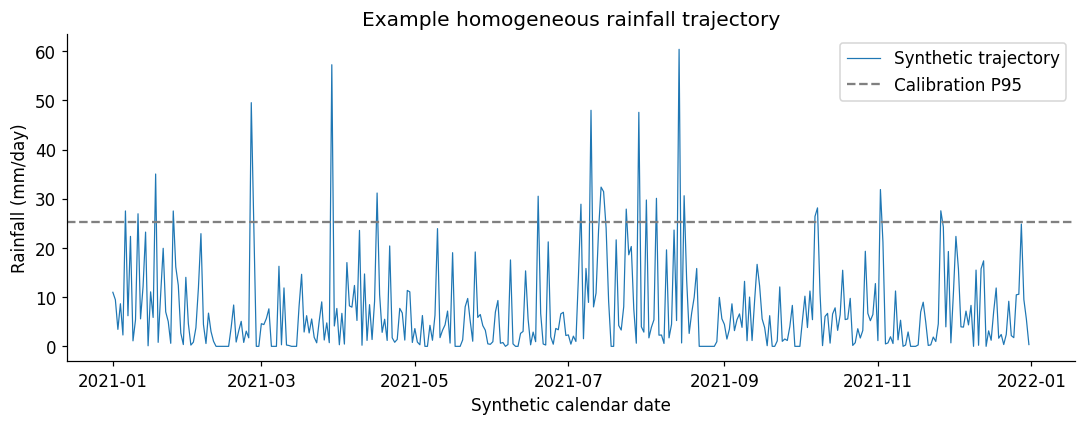

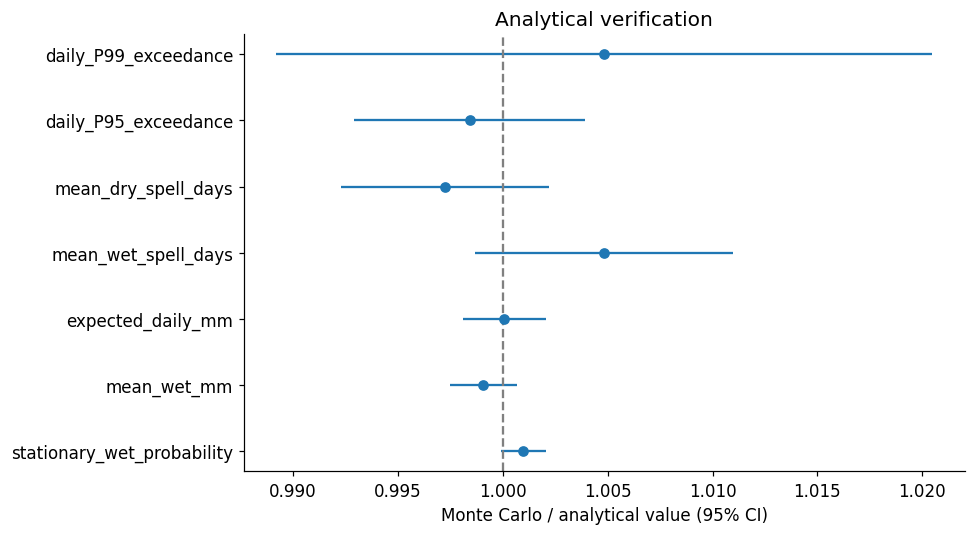

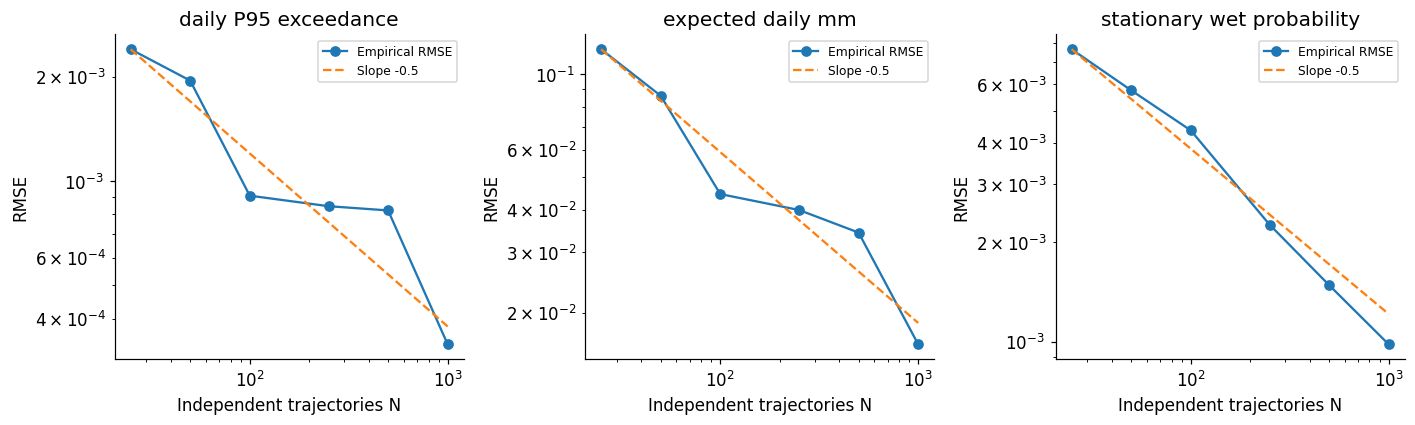

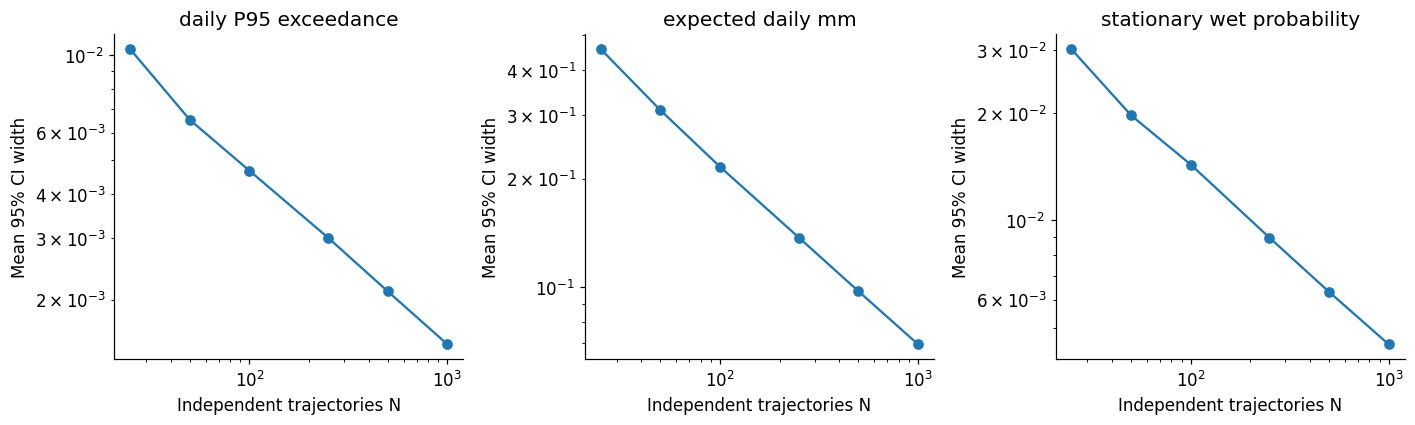

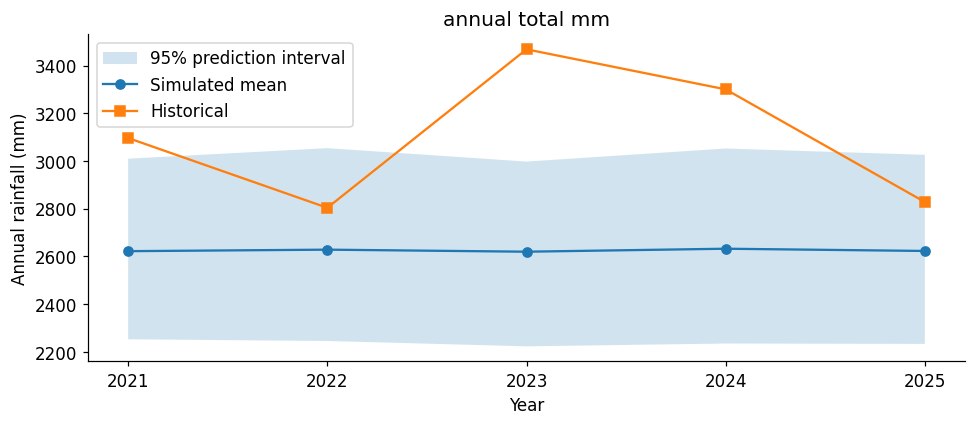

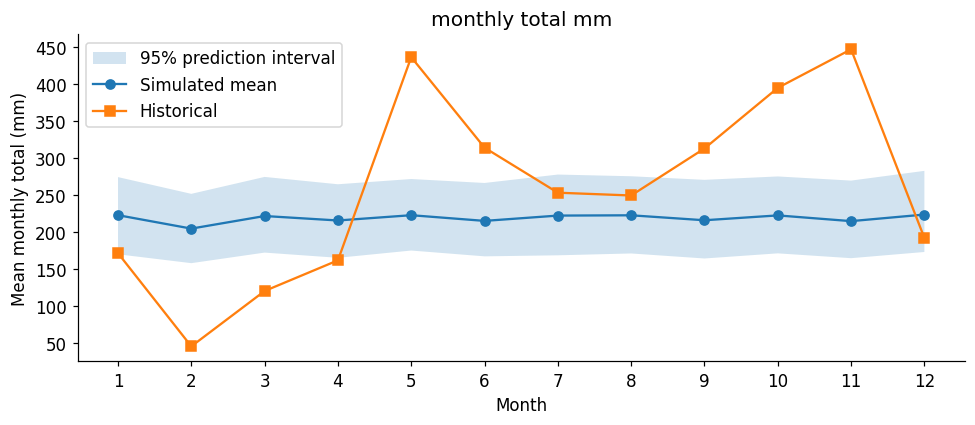

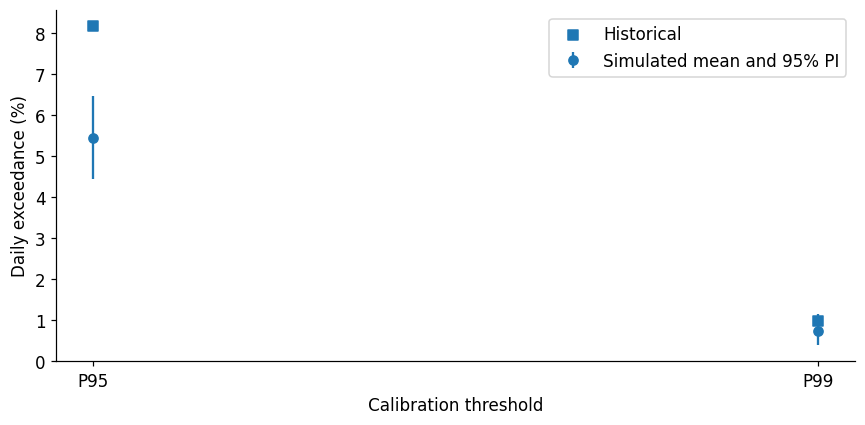

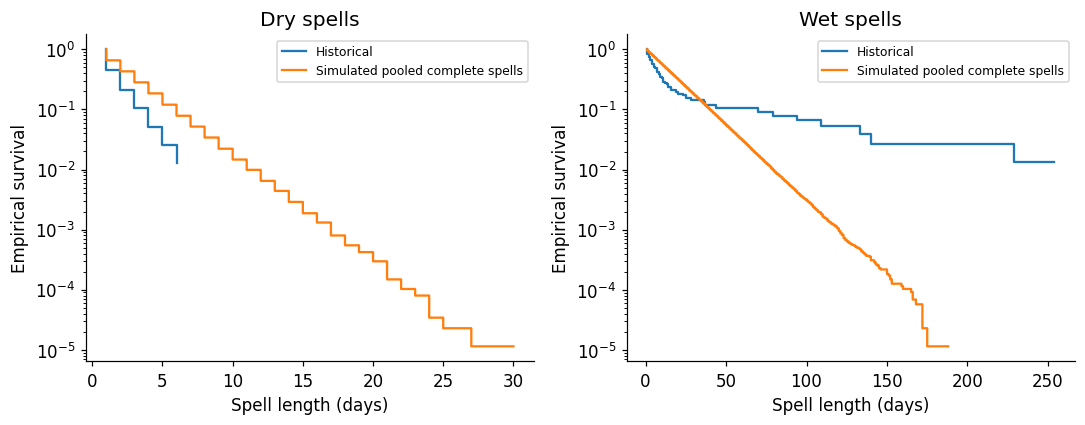

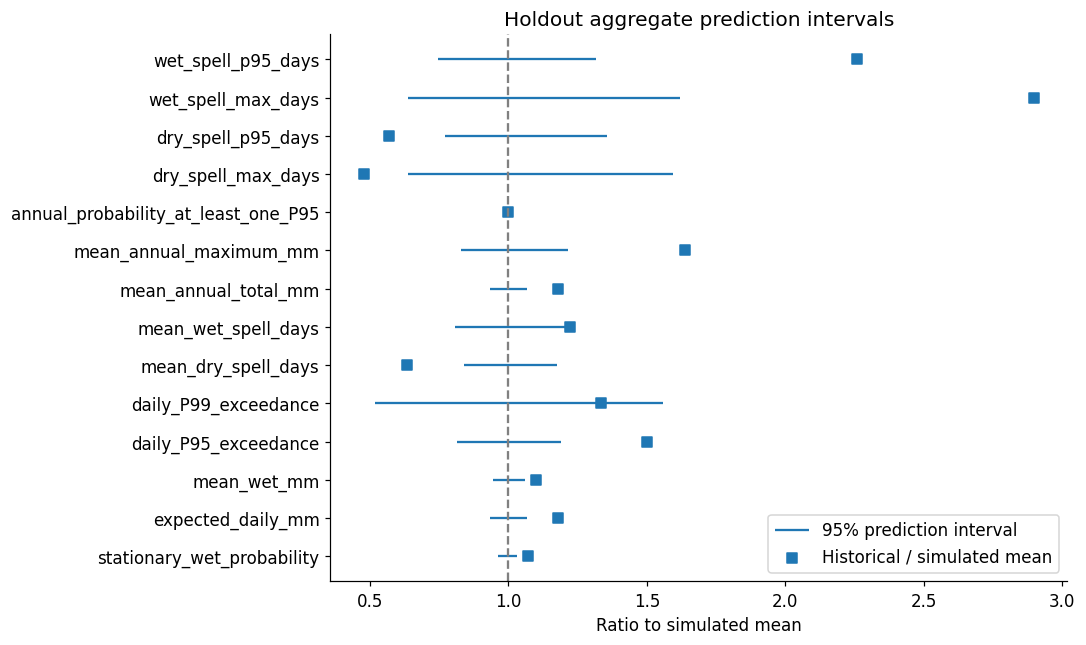

In [22]:
%%scientific
# C22
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(calendar[:365],hold_amounts[0,:365],lw=.8,label='Synthetic trajectory')
ax.axhline(q95,ls='--',color='gray',label='Calibration P95')
ax.set(xlabel='Synthetic calendar date',ylabel='Rainfall (mm/day)',title='Example homogeneous rainfall trajectory')
ax.legend()
finish(fig,'F15_synthetic_trajectory')
fig,ax=plt.subplots(figsize=(9,5))
ratios=analytical_mc['mean']/analytical_mc.analytical
ax.errorbar(ratios,range(len(ratios)),xerr=[ratios-analytical_mc.ci_low/analytical_mc.analytical,analytical_mc.ci_high/analytical_mc.analytical-ratios],fmt='o')
ax.axvline(1,color='gray',ls='--')
ax.set(yticks=range(len(ratios)),yticklabels=analytical_mc.metric,xlabel='Monte Carlo / analytical value (95% CI)',title='Analytical verification')
finish(fig,'F16_analytical_verification')
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,(metric,group) in zip(axs,convergence.groupby('metric')):
    nvals=group.replications.to_numpy()
    ax.loglog(nvals,group.rmse,'o-',label='Empirical RMSE')
    ax.loglog(nvals,group.rmse.iloc[0]*(nvals/nvals[0])**-.5,'--',label='Slope -0.5')
    ax.set(xlabel='Independent trajectories N',ylabel='RMSE',title=metric.replace('_',' '))
    ax.legend(fontsize=8)
finish(fig,'F17_convergence')
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,(metric,group) in zip(axs,convergence.groupby('metric')):
    ax.loglog(group.replications,group.mean_ci_width,'o-')
    ax.set(xlabel='Independent trajectories N',ylabel='Mean 95% CI width',title=metric.replace('_',' '))
finish(fig,'F18_ci_width')
def comparison_plot(metric,filename,xlabel,ylabel):
    group=holdout[holdout.metric==metric]
    pos=np.arange(len(group))
    fig,ax=plt.subplots(figsize=(9,4))
    ax.fill_between(pos,group.pi_low,group.pi_high,alpha=.2,label='95% prediction interval')
    ax.plot(pos,group['mean'],'o-',label='Simulated mean')
    ax.plot(pos,group.historical,'s-',label='Historical')
    ax.set(xticks=pos,xticklabels=group.group,xlabel=xlabel,ylabel=ylabel,title=metric.replace('_',' '))
    ax.legend()
    finish(fig,filename)
comparison_plot('annual_total_mm','F19_annual_holdout','Year','Annual rainfall (mm)')
comparison_plot('monthly_total_mm','F20_monthly_holdout','Month','Mean monthly total (mm)')
fig,ax=plt.subplots(figsize=(8,4))
group=holdout[holdout.metric.isin(['daily_P95_exceedance','daily_P99_exceedance'])]
pos=np.arange(2)
ax.errorbar(pos,100*group['mean'],yerr=[100*(group['mean']-group.pi_low),100*(group.pi_high-group['mean'])],fmt='o',label='Simulated mean and 95% PI')
ax.scatter(pos,100*group.historical,marker='s',label='Historical')
ax.set(xticks=pos,xticklabels=['P95','P99'],ylabel='Daily exceedance (%)',xlabel='Calibration threshold')
ax.legend()
finish(fig,'F21_extreme_holdout')
fig,axs=plt.subplots(1,2,figsize=(10,4))
for state,ax in enumerate(axs):
    obs=complete_spells(observed_states[0],state)
    sim=np.concatenate([complete_spells(row,state) for row in hold_states])
    for values,label in [(obs,'Historical'),(sim,'Simulated pooled complete spells')]:
        sorted_values=np.sort(values)
        ax.step(sorted_values,1-np.arange(len(values))/len(values),where='pre',label=label)
    ax.set(xlabel='Spell length (days)',ylabel='Empirical survival',yscale='log',title=['Dry spells','Wet spells'][state])
    ax.legend(fontsize=8)
finish(fig,'F22_spell_holdout')
fig,ax=plt.subplots(figsize=(10,6))
group=holdout[(holdout.group=='all') & (holdout['mean']>0)]
pos=np.arange(len(group))
ax.hlines(pos,group.pi_low/group['mean'],group.pi_high/group['mean'],label='95% prediction interval')
ax.scatter(group.historical/group['mean'],pos,marker='s',label='Historical / simulated mean')
ax.axvline(1,ls='--',color='gray')
ax.set(yticks=pos,yticklabels=group.metric,xlabel='Ratio to simulated mean',title='Holdout aggregate prediction intervals')
ax.legend()
finish(fig,'F23_holdout_intervals')

In [ ]:
%%scientific
# C23
(PROCESSED_DIR/'simulation_config.json').write_text(json.dumps({**EXPERIMENT,'primary_threshold_mm':float(q95),'secondary_threshold_mm':float(q99),'holdout_initial_state':int(cal.is_wet.iloc[-1]),'stream_namespaces':{'tests':0,'verification':1,'convergence':2,'holdout':3,'annual':4}},indent=2)+'\n')
new_files={'C18':['simulation_verification.csv'],'C19':['monte_carlo_analytical.csv','annual_simulation_uncertainty.csv'],'C20':['convergence_batches.csv','convergence_results.csv','convergence_slopes.csv','convergence_timing.csv'],'C21':['holdout_comparison.csv','holdout_trajectory_statistics.csv','holdout_aggregate_errors.csv'],'C23':['simulation_config.json','execution_runtime.csv']}
for cell,files in new_files.items():
    for filename in files:
        manifest.loc[len(manifest)]=[f'data/processed/{filename}',cell,filename.replace('_',' ')]
for name in FIGURE_DATA:
    if int(name[1:3])>=15:
        manifest.loc[len(manifest)]=[f'figures/{name}.png','C22',name.replace('_',' ')]
manifest.loc[manifest.path.str.endswith(('figure_data.json','output_manifest.csv')),'cell']='C23'
(PROCESSED_DIR/'figure_data.json').write_text(json.dumps(FIGURE_DATA,default=str,sort_keys=True),encoding='utf-8')
manifest.to_csv(PROCESSED_DIR/'output_manifest.csv',index=False)
pd.DataFrame([{'elapsed_seconds':time.perf_counter()-RUN_START,'python':platform.python_version(),'bootstrap_seconds':BOOTSTRAP_SECONDS,'execution_mode':EXECUTION_MODE}]).to_csv(PROCESSED_DIR/'execution_runtime.csv',index=False)
assert len(FIGURE_DATA)==23 and manifest.path.is_unique and all((OUTPUT/path).is_file() for path in manifest.path)
print('Complete pipeline:',len(manifest),'outputs; seconds:',time.perf_counter()-RUN_START)

### Execution provenance for this revision

The saved S005 outputs are retained for reference. The new seasonal results and figures below were computed from the raw-data calibration using Python 3.13.5, NumPy 2.3.5, pandas 2.2.3, SciPy 1.17.0 and Matplotlib 3.10.8. The release now pins pandas 2.3.3 for the requested Python 3.14 migration; installation was unavailable in the local runner. The new pinned environment, Windows, and fresh Colab compatibility are **not yet verified**. Run all to regenerate the outputs in the requested environment. Two independent local processes executed all scientific source cells in sequence, excluding the notebook bootstrap (57.51 s and 58.25 s). All 69 non-timing outputs matched byte-for-byte; only the three timing files differed.

### Seasonal model and controlled sensitivity

The seasonal chain uses destination-date matrices and carries the previous state across all boundaries. For row vector $\pi_t=\pi_{t-1}P_t$, wet probability is $\pi_{t,1}$. Expected rainfall is $\pi_{t,1}E[X_t\mid X_t\geq\tau]$ and exceedance is $\pi_{t,1}\bar F_t(u)/\bar F_t(\tau)$. Explicit calibration-end initialisation is used, not annual stationarity. The holdout comparison shares independent trajectory-level random streams with the homogeneous baseline. The seasonal extension was predefined; historical holdout findings are already visible and no further tuning is performed.

Sensitivity scales transition odds by $kp/(1-p+kp)$ and Gamma scale by $k\beta$, keeping thresholds and shape fixed. Annual event probability uses the substochastic matrix $P\operatorname{diag}(1,1-r)$, where $r$ is the conditional wet-day tail probability; the chance of any event in $D$ days is $1-\pi(P\operatorname{diag}(1,1-r))^D\mathbf{1}$. Paired differences use the same random draws across scenarios; replications remain independent. These are mathematical perturbations, not climate projections. Complete spell means may differ from theoretical means due to censoring and finite horizons. Intervals condition on fitted parameters.

The shared statistics key `stationary_wet_probability` is retained for cross-model tables, but for the seasonal model it denotes the horizon-average wet-day probability, not an annually stationary law. The sensitivity experiment uses 500 trajectories per unique scenario, 365 days each, with a cache of conditional amount transforms for the five scales; this reduces computation without changing the mathematical experiment. Exact binomial intervals are used for annual-event marginals; paired t intervals approximate uncertainty in scenario differences. When every pair has the same event indicator, a degenerate interval does not establish certainty about the true paired effect.


In [ ]:
%%scientific
# C24
S6 = dict(reps=EXPERIMENT['holdout_reps'], annual_days=365,
          multipliers=[0.8, 0.9, 1.0, 1.1, 1.2], sensitivity_reps=500)
season_models = {r['season']: (np.array([[r['p00'], r['p01']],
                                        [r['p10'], r['p11']]]),
                              r['shape'], r['scale_mm'], WET)
                 for r in seasonal_rows}


def calendar_ensemble(dates, reps: int, models: dict, initial: int,
                      seed: int = SEED, namespace: tuple = (3,)):
    """Use destination-date parameters and preserve state across boundaries.

    Matching seed/namespace pairs deliberately share occurrence and amount uniforms.
    Distinct child streams correspond to independent trajectories.
    """
    dates = pd.DatetimeIndex(dates)
    assert len(dates) and dates.equals(pd.date_range(dates[0], periods=len(dates)))
    assert initial in (0, 1) and reps > 0
    labels = np.array([season_map[m] for m in dates.month])
    for model in models.values():
        validate(*model)
    u = np.empty((reps, len(dates)))
    v = np.empty_like(u)
    for i, child in enumerate(np.random.SeedSequence(seed, spawn_key=namespace).spawn(reps)):
        generator = np.random.default_rng(child)
        generator.random()  # same origin draw consumption as homogeneous ensemble
        u[i] = generator.random(len(dates))
        v[i] = generator.random(len(dates))
    states = np.empty(u.shape, dtype=np.int8)
    previous = np.full(reps, initial, dtype=np.int8)
    for j, label in enumerate(labels):
        matrix = models[label][0]
        previous = (u[:, j] < matrix[previous, 1]).astype(np.int8)
        states[:, j] = previous
    amounts = np.zeros(u.shape)
    for label, (_, shape, scale, lower) in models.items():
        wet = (states == 1) & (labels == label)[None, :]
        amounts[wet] = sample_amounts(v[wet], shape, scale, lower)
    return states, amounts


def calendar_expectations(dates, models: dict, initial: int):
    """Propagate the probability vector; no annual stationary approximation."""
    probability = np.eye(2)[initial]
    rows = []
    for date in dates:
        matrix, shape, scale, lower = models[season_map[date.month]]
        probability = probability @ matrix
        denominator = gammaincc(shape, lower / scale)
        mean = shape * scale * gammaincc(shape + 1, lower / scale) / denominator
        rows.append([probability[1], probability[1] * mean,
                     probability[1] * gammaincc(shape, q95 / scale) / denominator,
                     probability[1] * gammaincc(shape, q99 / scale) / denominator])
    return pd.DataFrame(rows, index=dates, columns=['stationary_wet_probability',
        'expected_daily_mm', 'daily_P95_exceedance', 'daily_P99_exceedance'])

In [ ]:
%%scientific
# C25
checks = []
def check(label, condition):
    assert condition, label
    checks.append(dict(test=label, passed=True))

check('All twelve months', [season_map[m] for m in range(1,13)] ==
      ['NEM','NEM','FIM','FIM','SWM','SWM','SWM','SWM','SWM','SIM','SIM','NEM'])
check('Leap day NEM', season_map[pd.Timestamp('2024-02-29').month]=='NEM')
for name, model in season_models.items():
    validate(*model)
    check(name+' parameter domain', True)
origin = int(cal.is_wet.iloc[-1])
identical = {name: MODEL for name in seasons}
reduced = calendar_ensemble(calendar, S6['reps'], identical, origin)
check('Exact reduction to homogeneous occurrence', np.array_equal(reduced[0], hold_states))
check('Exact reduction to homogeneous amounts', np.array_equal(reduced[1], hold_amounts))
# Deterministic alternating transition across both seasonal and annual boundaries.
alternating = (np.array([[0.,1.],[1.,0.]]), alpha,beta,WET)
for start in ['2023-12-30','2024-02-28','2024-04-29','2024-09-29']:
    dates = pd.date_range(start, periods=4)
    states, amounts = calendar_ensemble(dates, 2, {s:alternating for s in seasons}, 0)
    check('Continuity '+start, np.array_equal(states, np.tile([1,0,1,0],(2,1))))
# Distinct destination matrices verify selection, not merely continuity.
forced = {s:(np.array([[1.,0.],[1.,0.]]),alpha,beta,WET) for s in seasons}
forced['FIM'] = (np.array([[0.,1.],[0.,1.]]),alpha,beta,WET)
check('Destination season switch', np.array_equal(calendar_ensemble(pd.date_range('2024-02-28',periods=4),1,forced,1)[0],[[0,0,1,1]]))
season_states, season_amounts = calendar_ensemble(calendar,S6['reps'],season_models,origin)
check('Dry rainfall zero', np.all(season_amounts[season_states==0]==0))
check('Wet support', np.all(season_amounts[season_states==1]>=WET))
repeat = calendar_ensemble(calendar,S6['reps'],season_models,origin)
check('Same seed reproducibility', np.array_equal(repeat[1],season_amounts))
del repeat, reduced
season_stats = trajectory_stats(season_states,season_amounts,q95,q99)
expected = calendar_expectations(calendar,season_models,origin)
expected.to_csv(PROCESSED_DIR/'seasonal_daily_expectations.csv',index_label='date')
season_verify = []
for metric, target in expected.mean().items():
    result = uncertainty(season_stats[metric])
    error = abs(result['mean']-target)
    tolerance = EXPERIMENT['sigma']*result['mcse']+ATOL
    season_verify.append(dict(metric=metric,analytical=target,**result,absolute_error=error,tolerance=tolerance,passed=error<=tolerance))
    check('Analytical '+metric,error<=tolerance)
season_verify = pd.DataFrame(season_verify)
season_verify.to_csv(PROCESSED_DIR/'seasonal_analytical.csv',index=False)
pd.DataFrame(checks).to_csv(PROCESSED_DIR/'seasonal_verification.csv',index=False)
display(season_verify,pd.DataFrame(checks))

test,passed
All twelve months,True
Leap day NEM,True
NEM parameter domain,True
FIM parameter domain,True
SWM parameter domain,True
SIM parameter domain,True
Exact reduction to homogeneous occurrence,True
Exact reduction to homogeneous amounts,True
Continuity 2023-12-30,True
Continuity 2024-02-28,True


metric,analytical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,tolerance,passed
stationary_wet_probability,0.860800,1000,0.861053,0.000382,0.860303,0.861802,0.837349,0.883352,0.000252,0.001528,True
expected_daily_mm,7.189990,1000,7.184172,0.007198,7.170047,7.198297,6.728689,7.627754,0.005818,0.028793,True
daily_P95_exceedance,0.051428,1000,0.051405,0.000168,0.051075,0.051735,0.041621,0.062432,0.000023,0.000673,True
daily_P99_exceedance,0.008166,1000,0.008199,0.000064,0.008073,0.008326,0.004381,0.012596,0.000033,0.000257,True


In [ ]:
%%scientific
# C26
# Reuse the exact S005 aggregation logic with seasonal arrays, retaining baseline outputs.

def seasonal_comparison():
    hold_rows=[]
    def compare(metric,group,actual,simulated):
        result=uncertainty(simulated)
        hold_rows.append(dict(metric=metric,group=str(group),historical=float(actual),**result,absolute_error=abs(result['mean']-actual),relative_error=abs(result['mean']-actual)/abs(actual) if actual else np.nan,inside_pi=result['pi_low']<=actual<=result['pi_high']))
    for metric in season_stats:
        compare(metric,'all',observed_stats[metric].iloc[0],season_stats[metric])
    years=calendar.year.unique()
    annual_sim=[]
    annual_obs=[]
    maxima_sim=[]
    maxima_obs=[]
    events_sim=[]
    events_obs=[]
    for year in years:
        mask=calendar.year==year
        totals=season_amounts[:,mask].sum(axis=1)
        actual=observed_amounts[:,mask].sum()
        maxima=season_amounts[:,mask].max(axis=1)
        actual_max=observed_amounts[:,mask].max()
        event=(season_amounts[:,mask]>q95).any(axis=1)
        actual_event=(observed_amounts[:,mask]>q95).any()
        annual_sim.append(totals)
        annual_obs.append(actual)
        maxima_sim.append(maxima)
        maxima_obs.append(actual_max)
        events_sim.append(event)
        events_obs.append(actual_event)
        compare('annual_total_mm',year,actual,totals)
        compare('annual_maximum_mm',year,actual_max,maxima)
        compare('annual_probability_at_least_one_P95',year,actual_event,event)
        interval = stats.binomtest(int(event.sum()),len(event)).proportion_ci(confidence_level=EXPERIMENT['confidence'],method='exact')
        hold_rows[-1].update(ci_low=interval.low,ci_high=interval.high,ci_method='exact binomial')
    compare('mean_annual_total_mm','all',np.mean(annual_obs),np.mean(annual_sim,axis=0))
    compare('mean_annual_maximum_mm','all',np.mean(maxima_obs),np.mean(maxima_sim,axis=0))
    compare('annual_probability_at_least_one_P95','all',np.mean(events_obs),np.mean(events_sim,axis=0))
    for month in range(1,13):
        masks=[(calendar.month==month)&(calendar.year==year) for year in years]
        compare('monthly_total_mm',month,np.mean([observed_amounts[:,m].sum() for m in masks]),np.mean([season_amounts[:,m].sum(axis=1) for m in masks],axis=0))
    for season in seasons:
        mask=evaluation.season.to_numpy()==season
        for metric,actual,simulated in [('season_daily_mm',observed_amounts[:,mask].mean(),season_amounts[:,mask].mean(axis=1)),('season_wet_frequency',observed_states[:,mask].mean(),season_states[:,mask].mean(axis=1)),('season_P95_frequency',(observed_amounts[:,mask]>q95).mean(),(season_amounts[:,mask]>q95).mean(axis=1)),('season_P99_frequency',(observed_amounts[:,mask]>q99).mean(),(season_amounts[:,mask]>q99).mean(axis=1))]:
            compare(metric,season,actual,simulated)
    for state, label in [(0,'dry'),(1,'wet')]:
        empirical_runs = complete_spells(observed_states[0],state)
        simulated_runs = [complete_spells(row,state) for row in season_states]
        for statistic, function in [('max',np.max),('p95',lambda a: np.quantile(a,.95))]:
            compare(f'{label}_spell_{statistic}_days','all',function(empirical_runs),np.array([function(run) if len(run) else np.nan for run in simulated_runs]))
    holdout=pd.DataFrame(hold_rows)
    holdout.to_csv(PROCESSED_DIR/'seasonal_holdout.csv',index=False)
    aggregate_errors=pd.DataFrame([dict(metric=label,mae=np.mean(abs(g.historical-g['mean'])),rmse=np.sqrt(np.mean((g.historical-g['mean'])**2))) for label,g in holdout[holdout.metric.isin(['monthly_total_mm','season_daily_mm'])].groupby('metric')])
    display(holdout,aggregate_errors)
    return holdout, aggregate_errors
seasonal_holdout, seasonal_errors = seasonal_comparison()

In [ ]:
%%scientific
# C27
# Paired aggregate comparisons use identical random inputs per trajectory.
comparative = pd.concat([holdout.assign(model='homogeneous'), seasonal_holdout.assign(model='seasonal')], ignore_index=True)
comparative.to_csv(PROCESSED_DIR/'comparative_holdout.csv',index=False)
errors = pd.concat([aggregate_errors.assign(model='homogeneous'), seasonal_errors.assign(model='seasonal')],ignore_index=True)
for metric in ['season_P95_frequency','season_P99_frequency','season_wet_frequency']:
    for model, group in comparative[comparative.metric==metric].groupby('model'):
        delta=group['mean']-group.historical
        errors.loc[len(errors)] = [metric,np.mean(abs(delta)),np.sqrt(np.mean(delta**2)),model]
base_errors=errors[errors.model=='homogeneous'].set_index('metric')
for measure in ['mae','rmse']:
    errors[measure+'_change_pct']=[100*(row[measure]/base_errors.loc[row.metric,measure]-1) for _,row in errors.iterrows()]
errors.to_csv(PROCESSED_DIR/'comparative_errors.csv',index=False)
paired=[]
for metric in hold_stats:
    paired.append(dict(metric=metric,**uncertainty(season_stats[metric]-hold_stats[metric])))
pd.DataFrame(paired).to_csv(PROCESSED_DIR/'comparative_paired.csv',index=False)
display(errors,comparative[comparative.group=='all'])

metric,mae,rmse,model,mae_change_pct,rmse_change_pct
monthly_total_mm,105.719305,126.525434,homogeneous,0.000000,0.000000
season_daily_mm,3.727141,4.090769,homogeneous,0.000000,0.000000
monthly_total_mm,57.428591,73.479342,seasonal,-45.678236,-41.925241
season_daily_mm,1.390144,1.510139,seasonal,-62.702138,-63.084218
season_P95_frequency,0.058641,0.066153,homogeneous,0.000000,0.000000
season_P95_frequency,0.027719,0.037138,seasonal,-52.730594,-43.861325
season_P99_frequency,0.007369,0.008830,homogeneous,0.000000,0.000000
season_P99_frequency,0.005368,0.006658,seasonal,-27.156663,-24.598500
season_wet_frequency,0.100055,0.102370,homogeneous,0.000000,0.000000
season_wet_frequency,0.067201,0.100901,seasonal,-32.835364,-1.434988


metric,group,historical,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,absolute_error,relative_error,inside_pi,ci_method,model
stationary_wet_probability,all,0.922234,1000,0.860408,0.000503,0.859421,0.861395,0.826930,0.888280,0.061826,0.067040,False,NaN,homogeneous
expected_daily_mm,all,8.486637,1000,7.187763,0.007949,7.172164,7.203363,6.701484,7.665457,1.298874,0.153049,False,NaN,homogeneous
mean_wet_mm,all,9.202257,1000,8.353910,0.007851,8.338505,8.369316,7.882894,8.844488,0.848346,0.092189,False,NaN,homogeneous
daily_P95_exceedance,all,0.081599,1000,0.054338,0.000168,0.054008,0.054669,0.044359,0.064622,0.027261,0.334081,False,NaN,homogeneous
daily_P99_exceedance,all,0.009858,1000,0.007386,0.000064,0.007260,0.007512,0.003834,0.011501,0.002472,0.250722,True,NaN,homogeneous
mean_dry_spell_days,all,1.844156,1000,2.907323,0.007895,2.891830,2.922816,2.445721,3.416693,1.063167,0.576506,False,NaN,homogeneous
mean_wet_spell_days,all,21.855263,1000,17.889937,0.059484,17.773210,18.006665,14.460082,21.929602,3.965326,0.181436,True,NaN,homogeneous
mean_annual_total_mm,all,3099.320000,1000,2624.971172,2.903157,2619.274187,2630.668156,2447.381853,2799.424853,474.348828,0.153049,False,NaN,homogeneous
mean_annual_maximum_mm,all,103.620000,1000,63.215785,0.200983,62.821387,63.610182,52.437930,76.830111,40.404215,0.389927,False,NaN,homogeneous
annual_probability_at_least_one_P95,all,1.000000,1000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,True,NaN,homogeneous


In [ ]:
%%scientific
# C28
def odds_scale(p: float, multiplier: float) -> float:
    """Scale odds, not probability or percentage points."""
    return multiplier*p/(1-p+multiplier*p)


def scenario_model(k01: float, k11: float, kb: float):
    matrix=P.copy()
    for i,k in enumerate([k01,k11]):
        matrix[i,1]=odds_scale(P[i,1],k)
        matrix[i,0]=1-matrix[i,1]
    return matrix,alpha,beta*kb,WET


def scenario_expectations(model, days: int):
    """Stationary marginal risk and exact annual event probability via survival recursion."""
    matrix,shape,scale,lower=model
    prob=stationary(matrix)
    denominator=gammaincc(shape,lower/scale)
    mean=shape*scale*gammaincc(shape+1,lower/scale)/denominator
    results={'stationary_wet_probability':prob[1], 'expected_daily_mm':prob[1]*mean,
             'mean_wet_mm':mean,'mean_wet_spell_days':1/matrix[1,0]}
    for label,threshold in [('P95',q95),('P99',q99)]:
        tail=gammaincc(shape,threshold/scale)/denominator
        risk=prob[1]*tail
        survival=prob @ np.linalg.matrix_power(matrix @ np.diag([1,1-tail]),days)
        results.update({f'daily_{label}_exceedance':risk,
                        f'annual_count_{label}':days*risk,
                        f'annual_event_{label}':1-survival.sum()})
    return results


# Cache common uniform draws and the five possible intensity transformations.
# Each scenario still uses its own stationary origin probability.
sensitivity_u = np.empty((S6['sensitivity_reps'], S6['annual_days']))
sensitivity_v = np.empty_like(sensitivity_u)
sensitivity_origins = np.empty(S6['sensitivity_reps'])
for i, child in enumerate(np.random.SeedSequence(SEED, spawn_key=(6,)).spawn(S6['sensitivity_reps'])):
    generator = np.random.default_rng(child)
    sensitivity_origins[i] = generator.random()
    sensitivity_u[i] = generator.random(S6['annual_days'])
    sensitivity_v[i] = generator.random(S6['annual_days'])
amount_cache = {}


def scenario_statistics(model):
    matrix, shape, scale, lower = model
    origins = (sensitivity_origins < stationary(matrix)[1]).astype(np.int8)
    states = generate_states(matrix, sensitivity_u, origins)
    if scale not in amount_cache:
        amount_cache[scale] = sample_amounts(sensitivity_v, shape, scale, lower)
    amounts = np.where(states == 1, amount_cache[scale], 0.)
    result=trajectory_stats(states,amounts,q95,q99)
    for label,threshold in [('P95',q95),('P99',q99)]:
        result[f'annual_count_{label}']=(amounts>threshold).sum(axis=1)
        result[f'annual_event_{label}']=(amounts>threshold).any(axis=1).astype(float)
    return result

baseline_scenario=scenario_statistics(MODEL)
baseline_theory=scenario_expectations(MODEL,S6['annual_days'])
scenario_rows=[]
settings=[]
for axis in ['p01','p11','beta']:
    for k in S6['multipliers']:
        settings.append((axis,k if axis=='p01' else 1.,k if axis=='p11' else 1.,k if axis=='beta' else 1.))
for k11 in S6['multipliers']:
    for kb in S6['multipliers']:
        settings.append(('joint',1.,k11,kb))
cache={ (1.,1.,1.): baseline_scenario }
for axis,k01,k11,kb in settings:
    model=scenario_model(k01,k11,kb)
    validate(*model)
    key=(k01,k11,kb)
    if key not in cache:
        cache[key]=scenario_statistics(model)
    values=cache[key]
    theory=scenario_expectations(model,S6['annual_days'])
    for metric,target in theory.items():
        result=uncertainty(values[metric])
        paired_values=values[metric]-baseline_scenario[metric]
        difference=uncertainty(paired_values)
        if metric.startswith('annual_event'):
            interval=stats.binomtest(int(values[metric].sum()),len(values)).proportion_ci(method='exact')
            result.update(ci_low=interval.low,ci_high=interval.high)
        scenario_rows.append(dict(axis=axis,k01=k01,k11=k11,kbeta=kb,p01=model[0][0,1],p11=model[0][1,1],beta_mm=model[2],metric=metric,analytical=target,analytical_delta=target-baseline_theory[metric],analytical_relative_pct=100*(target/baseline_theory[metric]-1),**result,paired_delta=difference['mean'],paired_relative_pct=100*difference['mean']/baseline_scenario[metric].mean(),paired_ci_low=difference['ci_low'],paired_ci_high=difference['ci_high'],paired_n=difference['n']))
sensitivity=pd.DataFrame(scenario_rows)
sensitivity.to_csv(PROCESSED_DIR/'sensitivity_scenarios.csv',index=False)
display(sensitivity[(sensitivity.metric=='daily_P95_exceedance') & (sensitivity.axis!='joint')])

axis,k01,k11,kbeta,p01,p11,beta_mm,metric,analytical,analytical_delta,analytical_relative_pct,n,mean,mcse,ci_low,ci_high,pi_low,pi_high,paired_delta,paired_relative_pct,paired_ci_low,paired_ci_high,paired_n
p01,0.8,1.0,1.0,0.295923,0.943967,11.343819,daily_P95_exceedance,0.053262,-0.001221,-2.241852,500,0.053030,0.000511,0.052027,0.054034,0.032877,0.073973,-0.001249,-2.301635,-0.001420,-0.001078,500
p01,0.9,1.0,1.0,0.321038,0.943967,11.343819,daily_P95_exceedance,0.053933,-0.000550,-1.008945,500,0.053710,0.000512,0.052704,0.054715,0.032877,0.076712,-0.000570,-1.049869,-0.000689,-0.000451,500
p01,1.0,1.0,1.0,0.344423,0.943967,11.343819,daily_P95_exceedance,0.054483,0.000000,0.000000,500,0.054279,0.000512,0.053274,0.055285,0.032877,0.076712,0.000000,0.000000,0.000000,0.000000,500
p01,1.1,1.0,1.0,0.366250,0.943967,11.343819,daily_P95_exceedance,0.054941,0.000458,0.840927,500,0.054696,0.000510,0.053694,0.055698,0.034178,0.076712,0.000416,0.767212,0.000321,0.000512,500
p01,1.2,1.0,1.0,0.386672,0.943967,11.343819,daily_P95_exceedance,0.055329,0.000846,1.552579,500,0.055058,0.000512,0.054052,0.056063,0.035616,0.076712,0.000778,1.433475,0.000639,0.000918,500
p11,1.0,0.8,1.0,0.344423,0.930926,11.343819,daily_P95_exceedance,0.052765,-0.001718,-3.153757,500,0.052701,0.000513,0.051694,0.053709,0.032877,0.076712,-0.001578,-2.907329,-0.001768,-0.001388,500
p11,1.0,0.9,1.0,0.344423,0.938126,11.343819,daily_P95_exceedance,0.053700,-0.000783,-1.437542,500,0.053556,0.000510,0.052554,0.054558,0.032877,0.076712,-0.000723,-1.332526,-0.000858,-0.000588,500
p11,1.0,1.0,1.0,0.344423,0.943967,11.343819,daily_P95_exceedance,0.054483,0.000000,0.000000,500,0.054279,0.000512,0.053274,0.055285,0.032877,0.076712,0.000000,0.000000,0.000000,0.000000,500
p11,1.0,1.1,1.0,0.344423,0.948800,11.343819,daily_P95_exceedance,0.055149,0.000666,1.221646,500,0.054921,0.000511,0.053917,0.055924,0.035616,0.076712,0.000641,1.181102,0.000507,0.000776,500
p11,1.0,1.2,1.0,0.344423,0.952866,11.343819,daily_P95_exceedance,0.055721,0.001238,2.272636,500,0.055485,0.000515,0.054473,0.056497,0.035616,0.076712,0.001205,2.220876,0.001011,0.001400,500


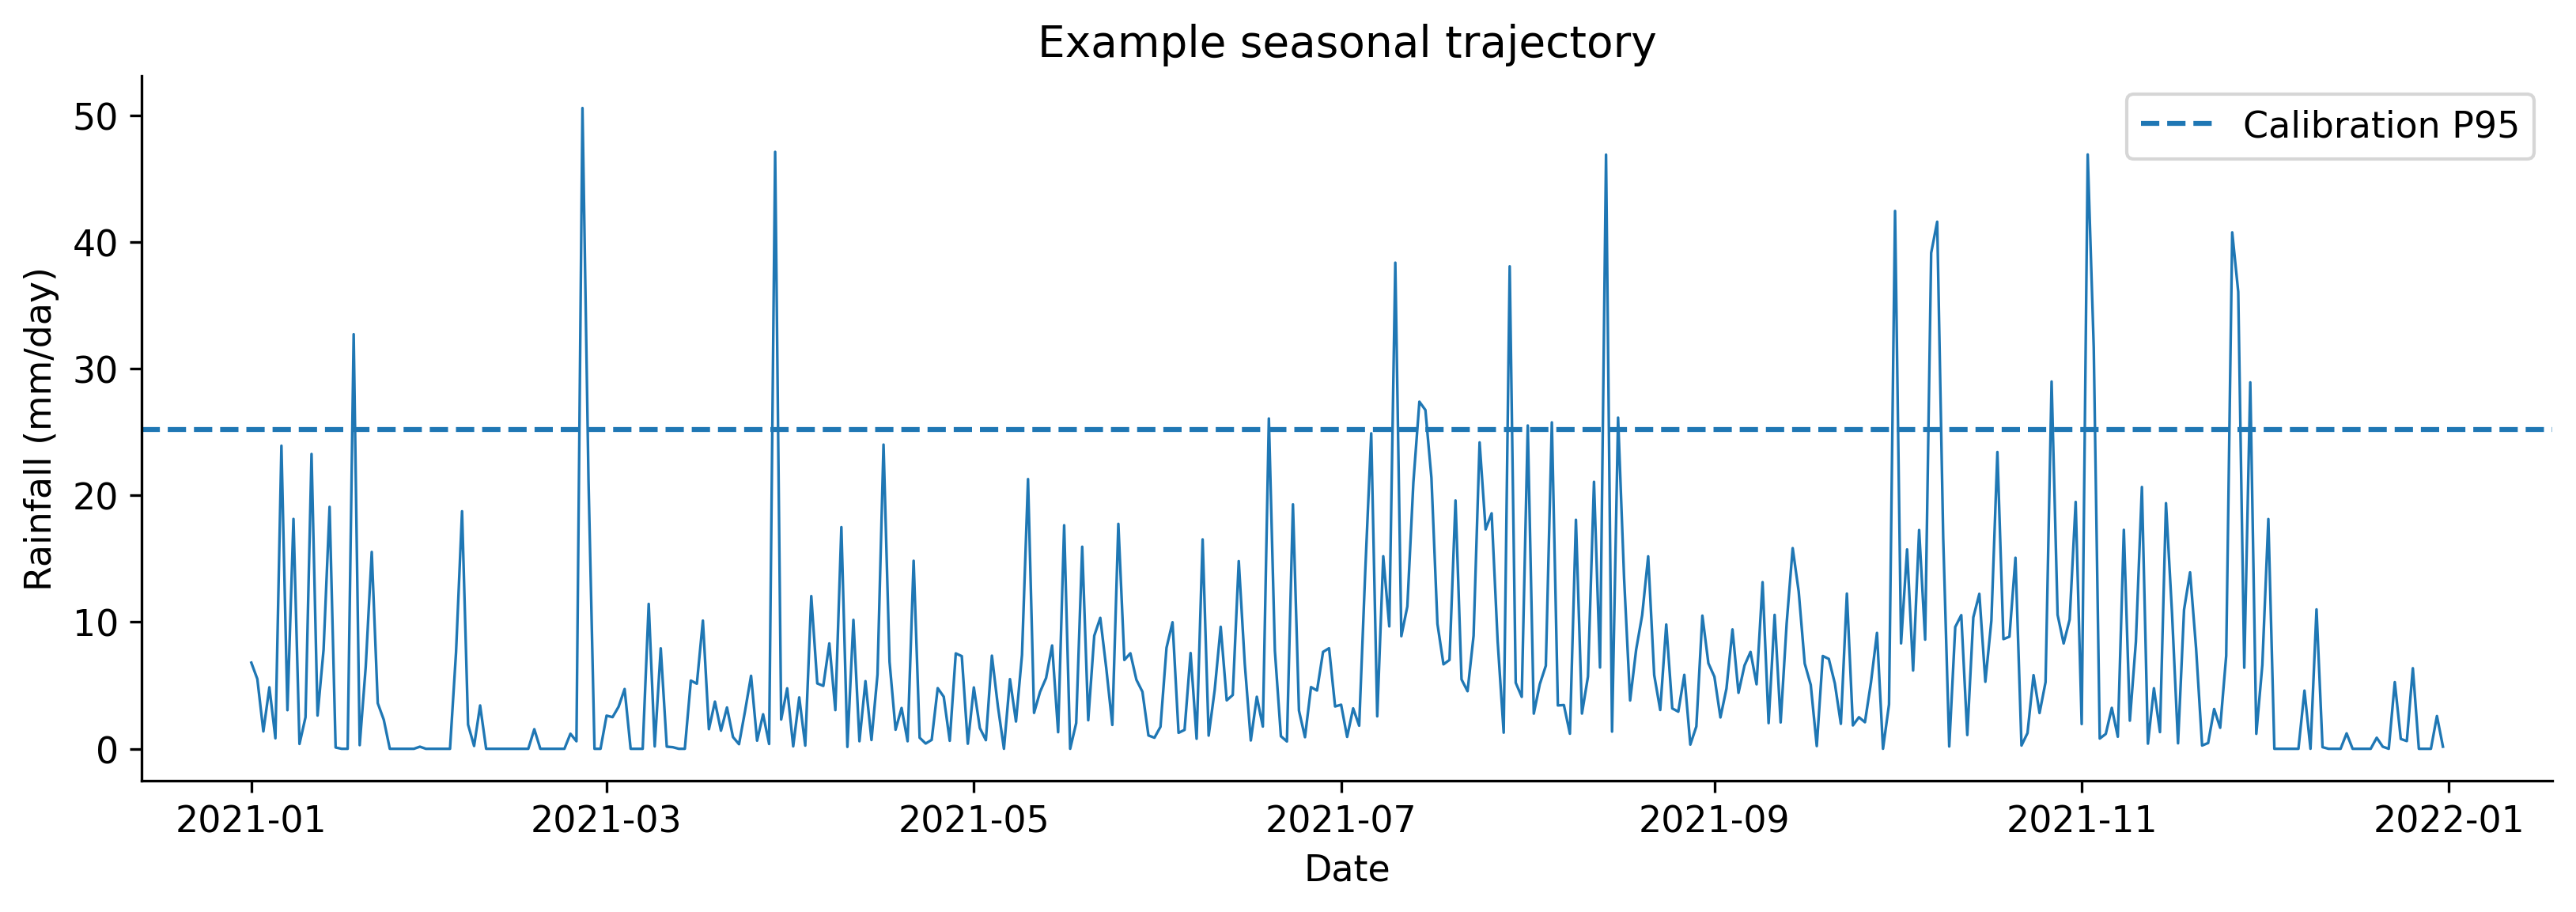

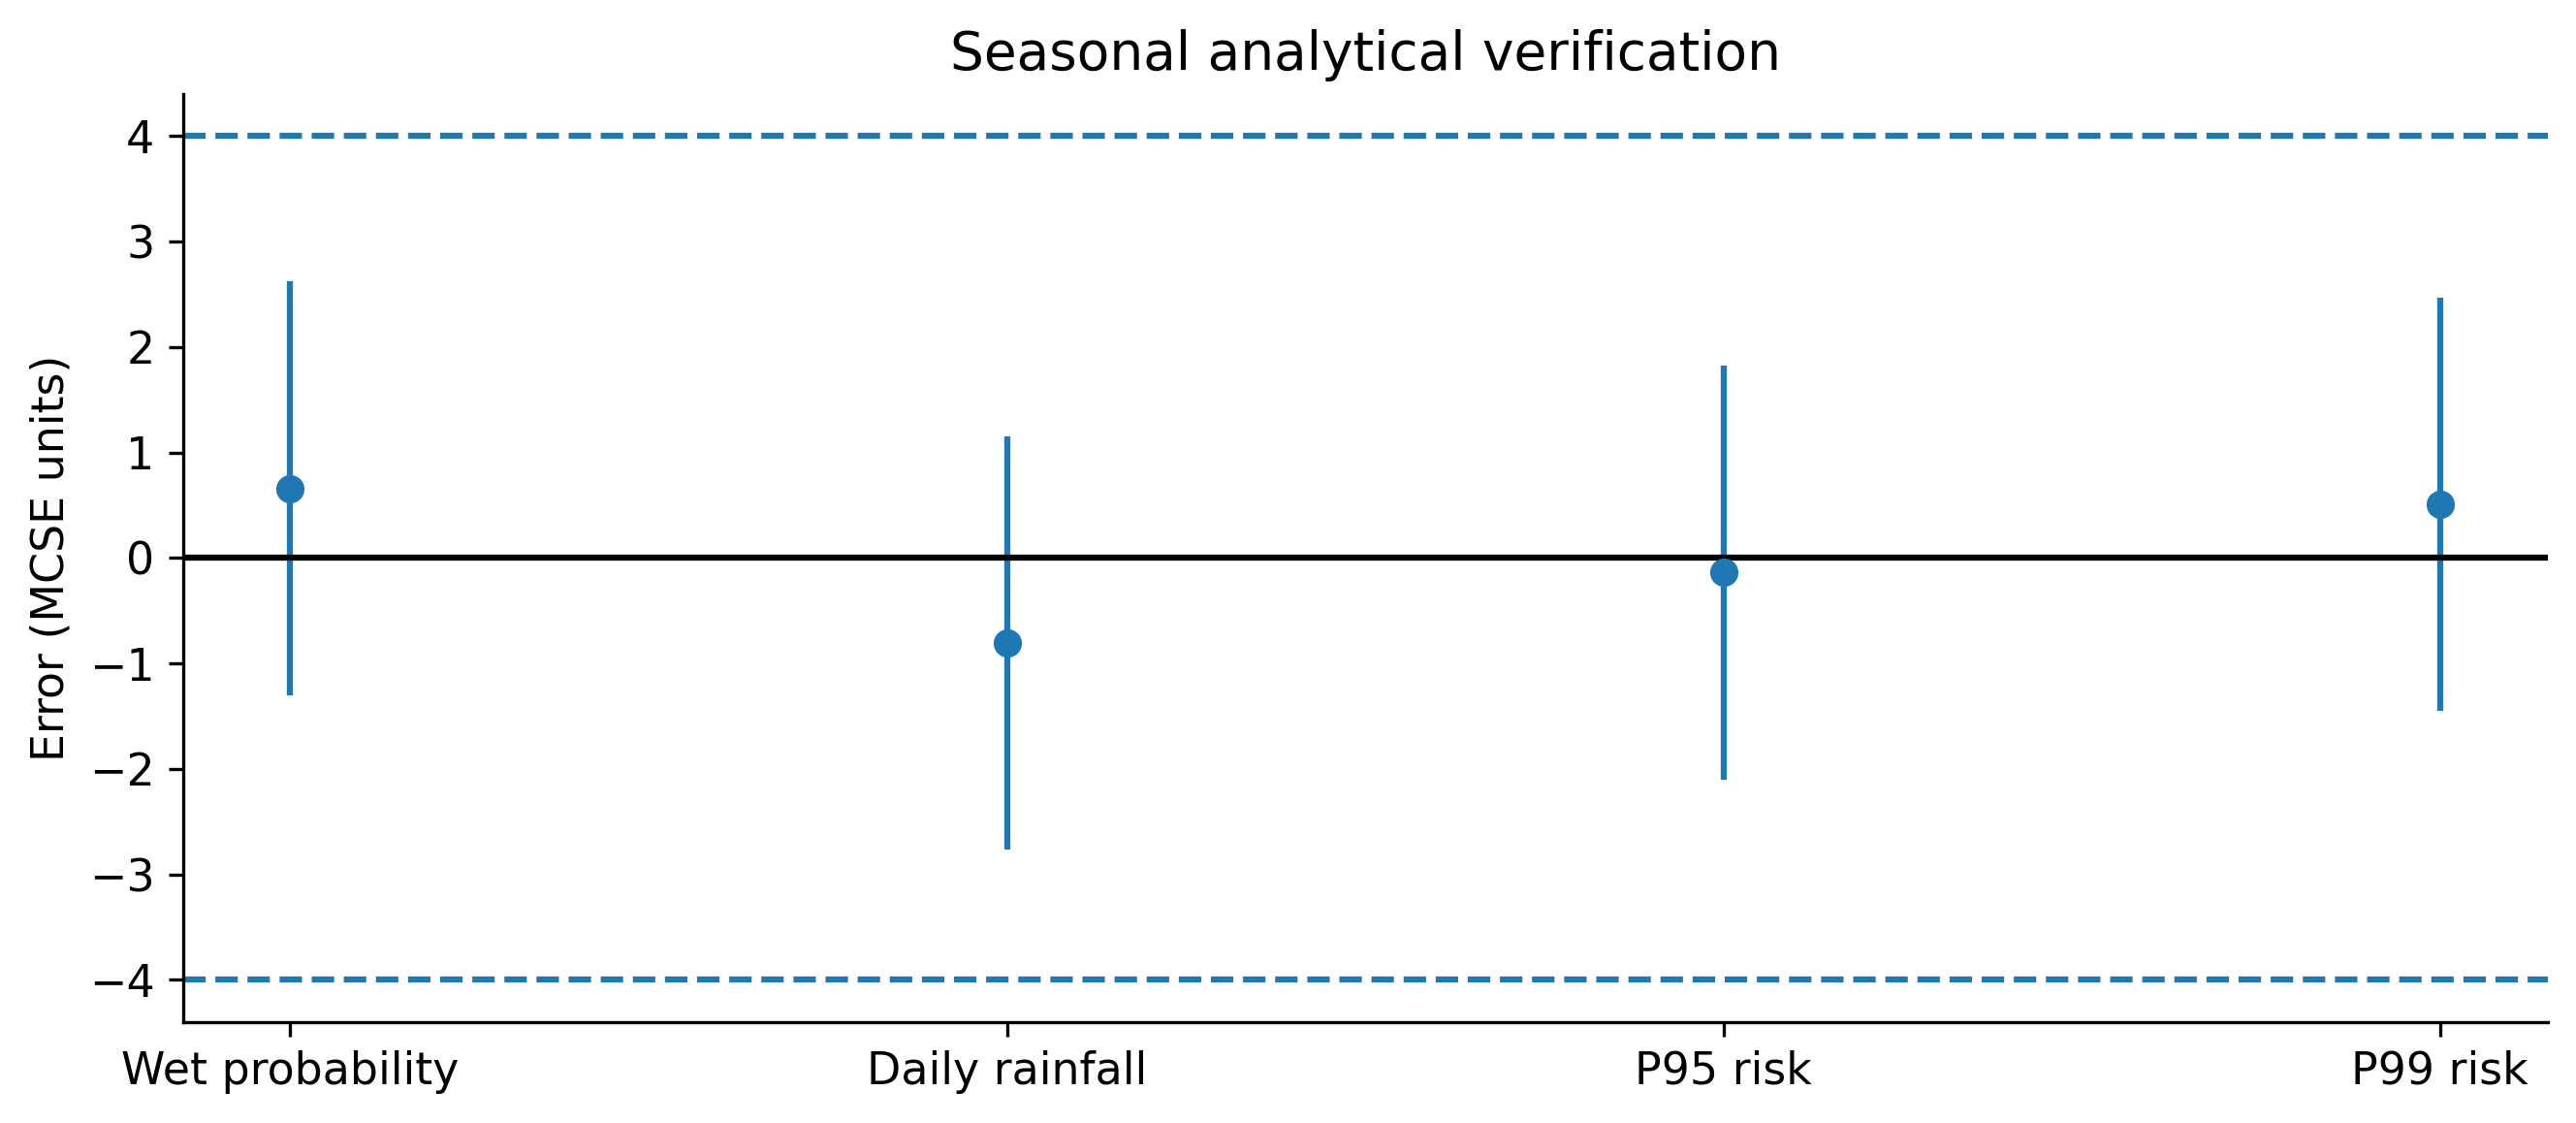

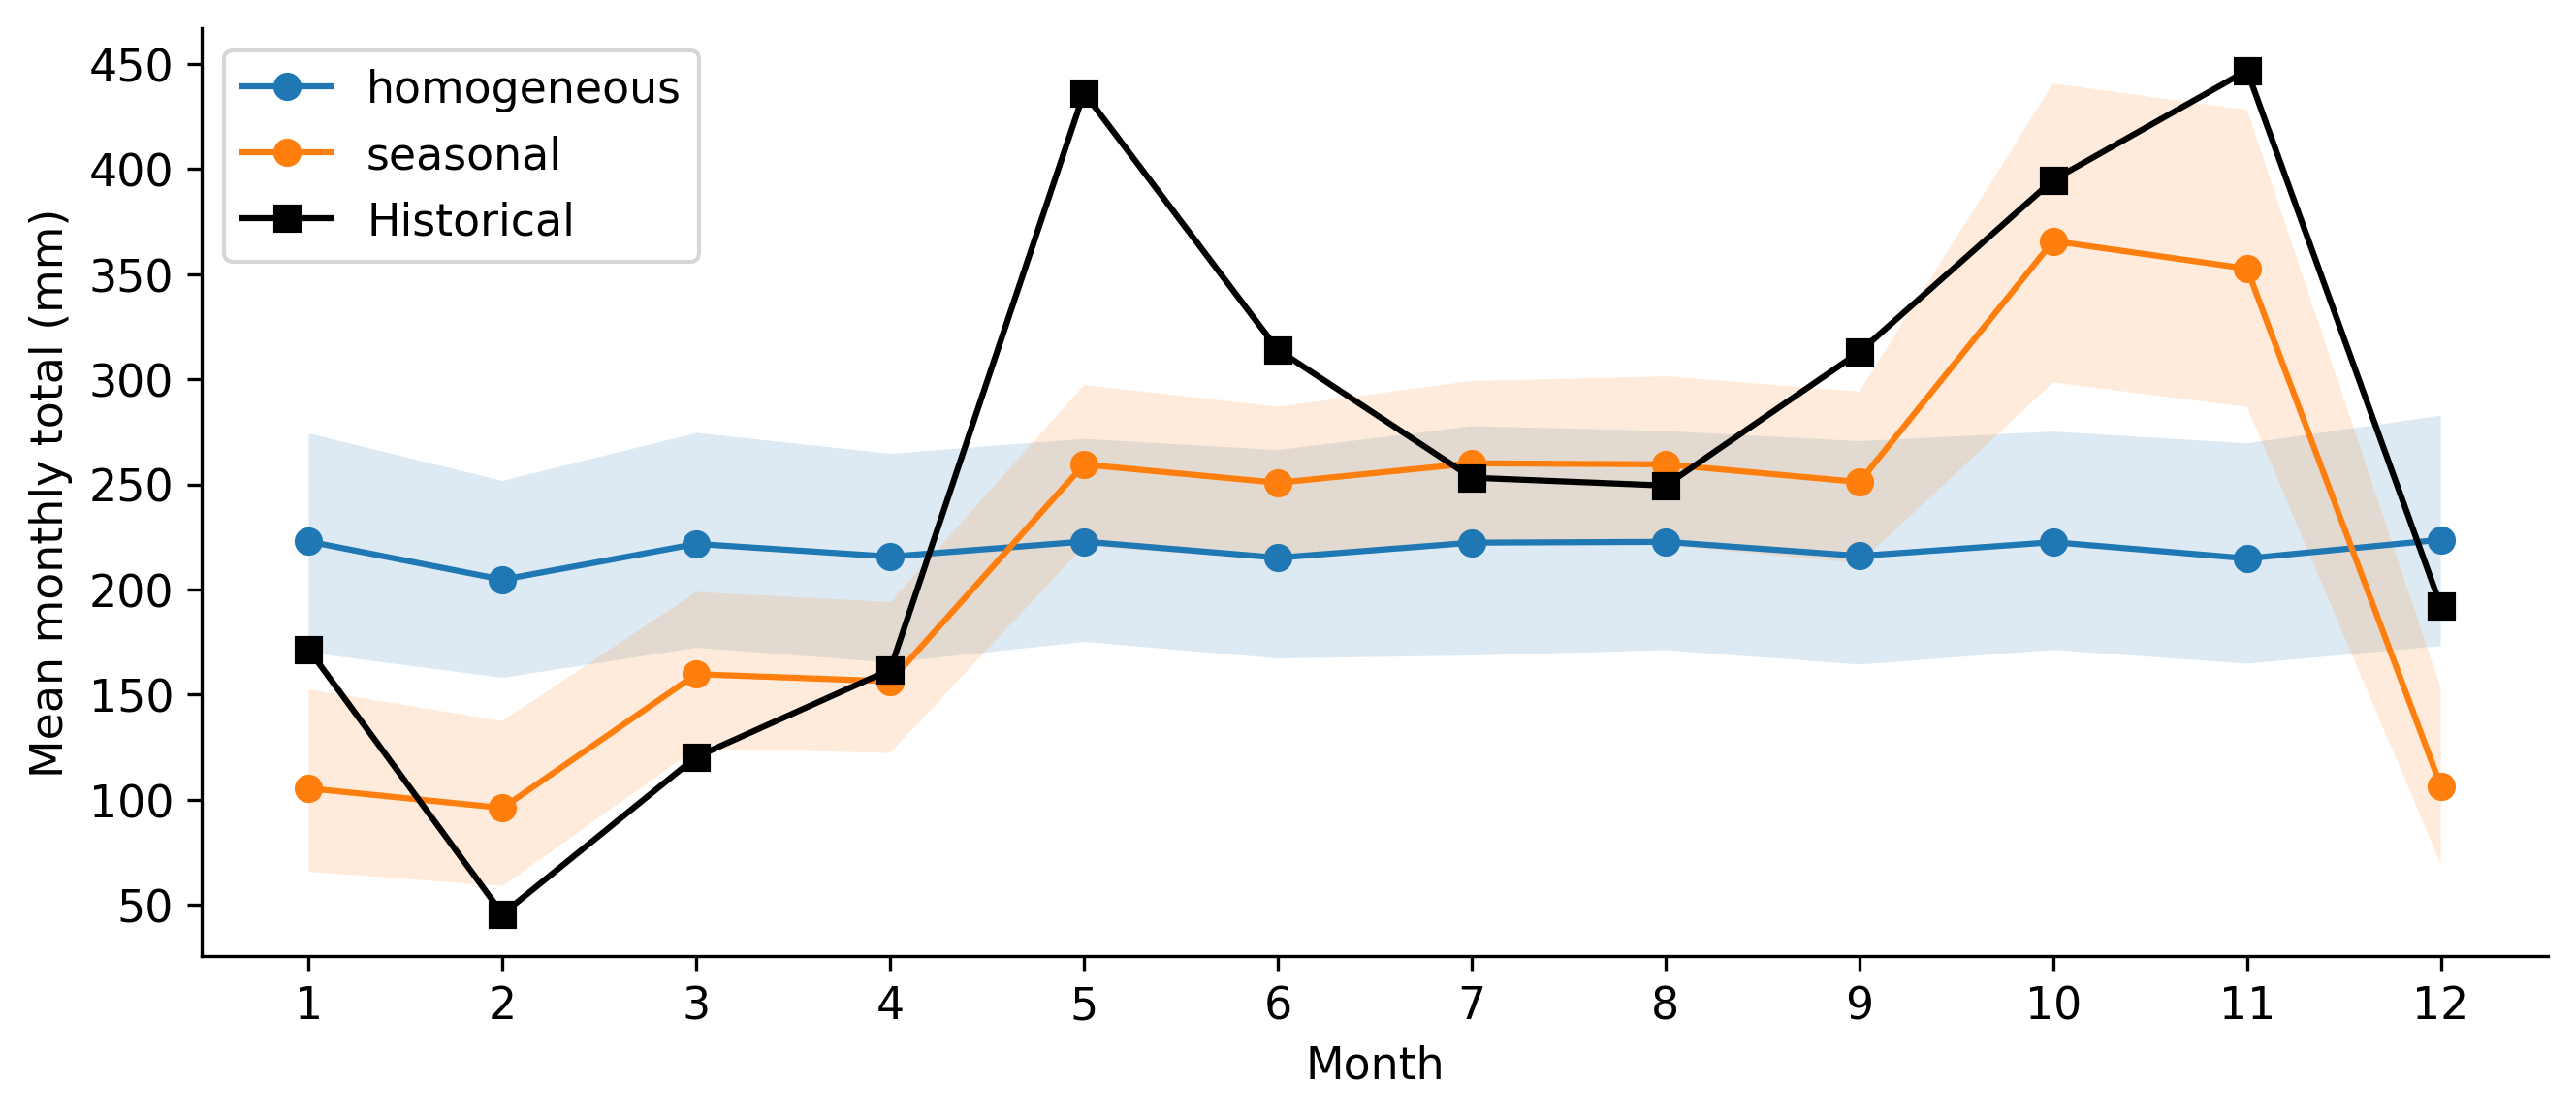

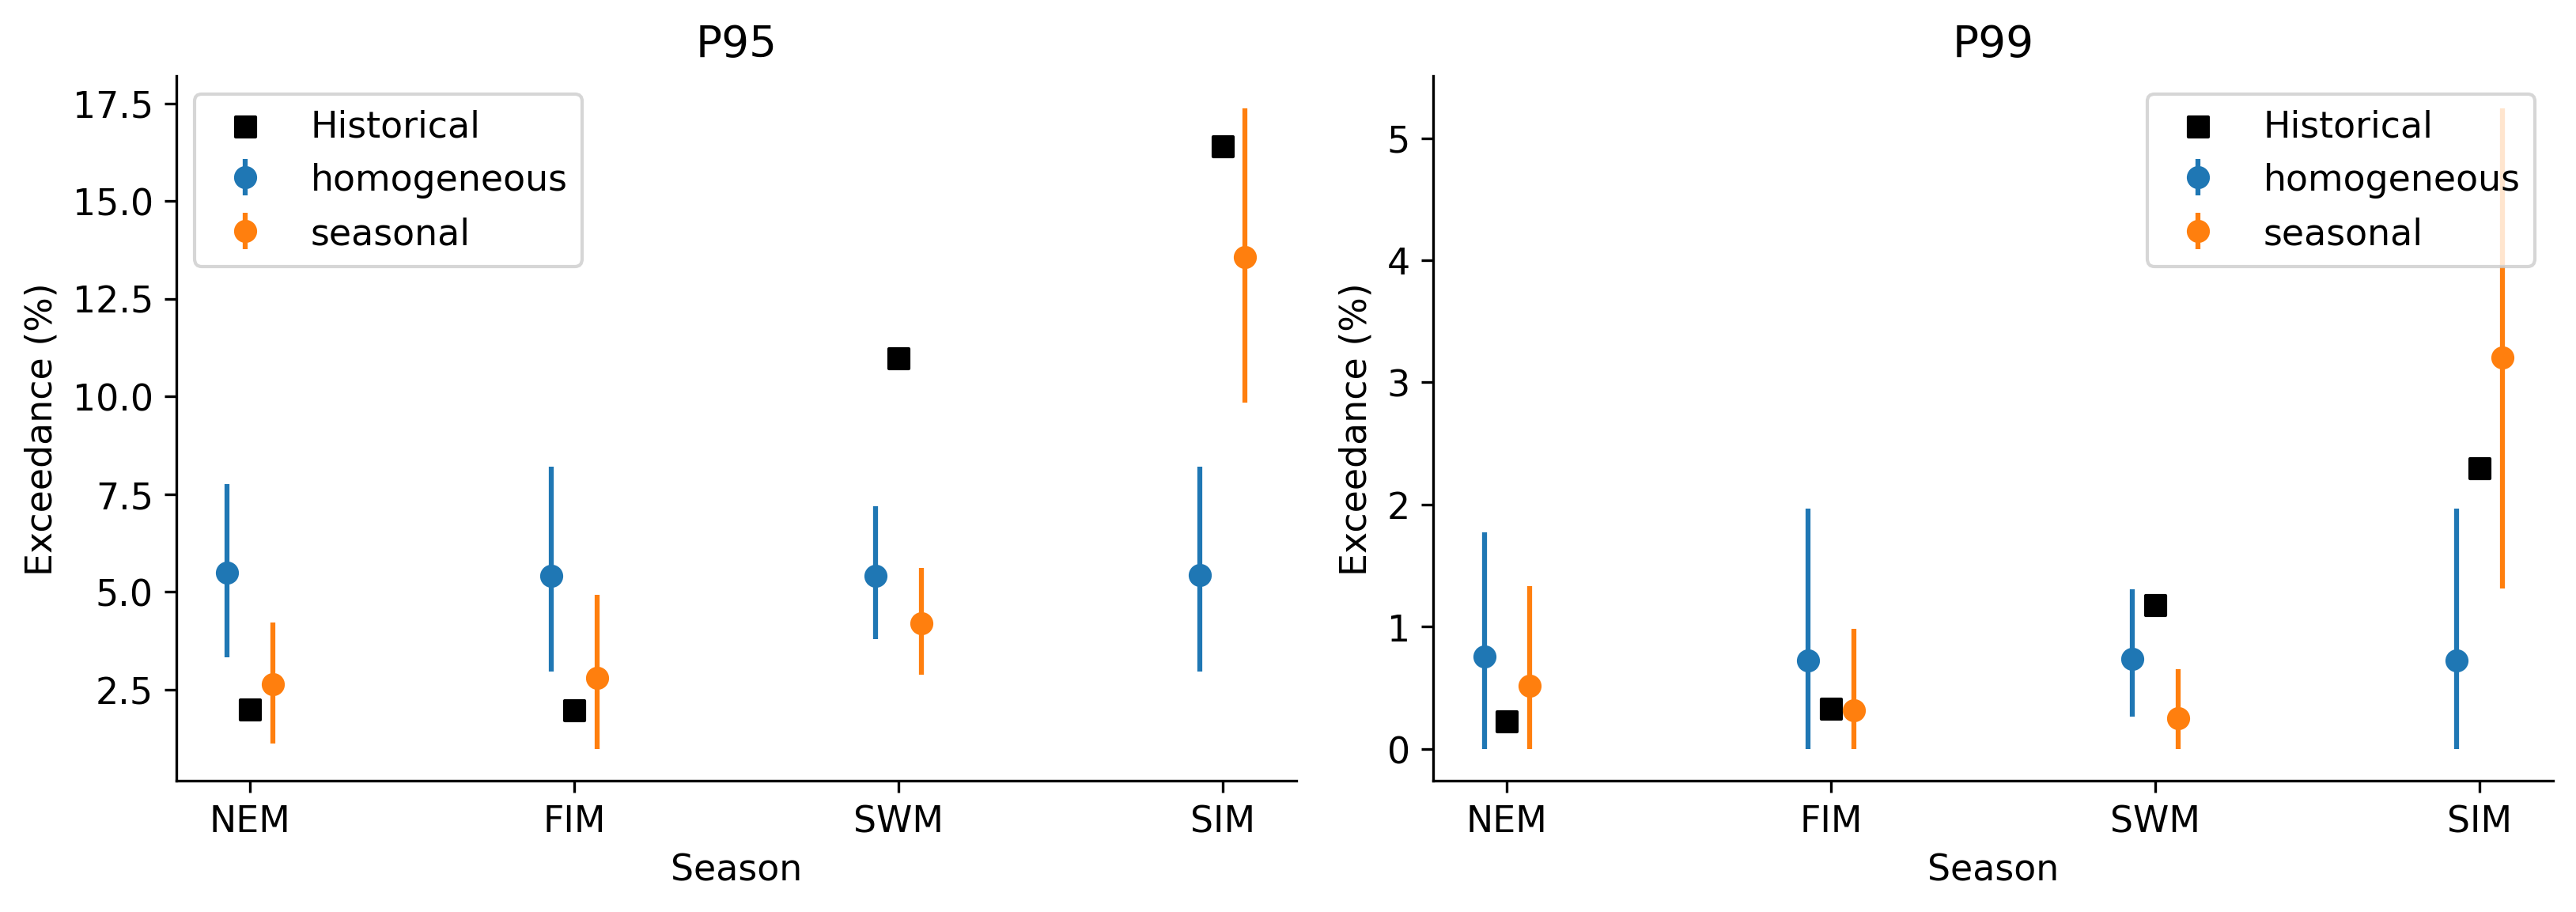

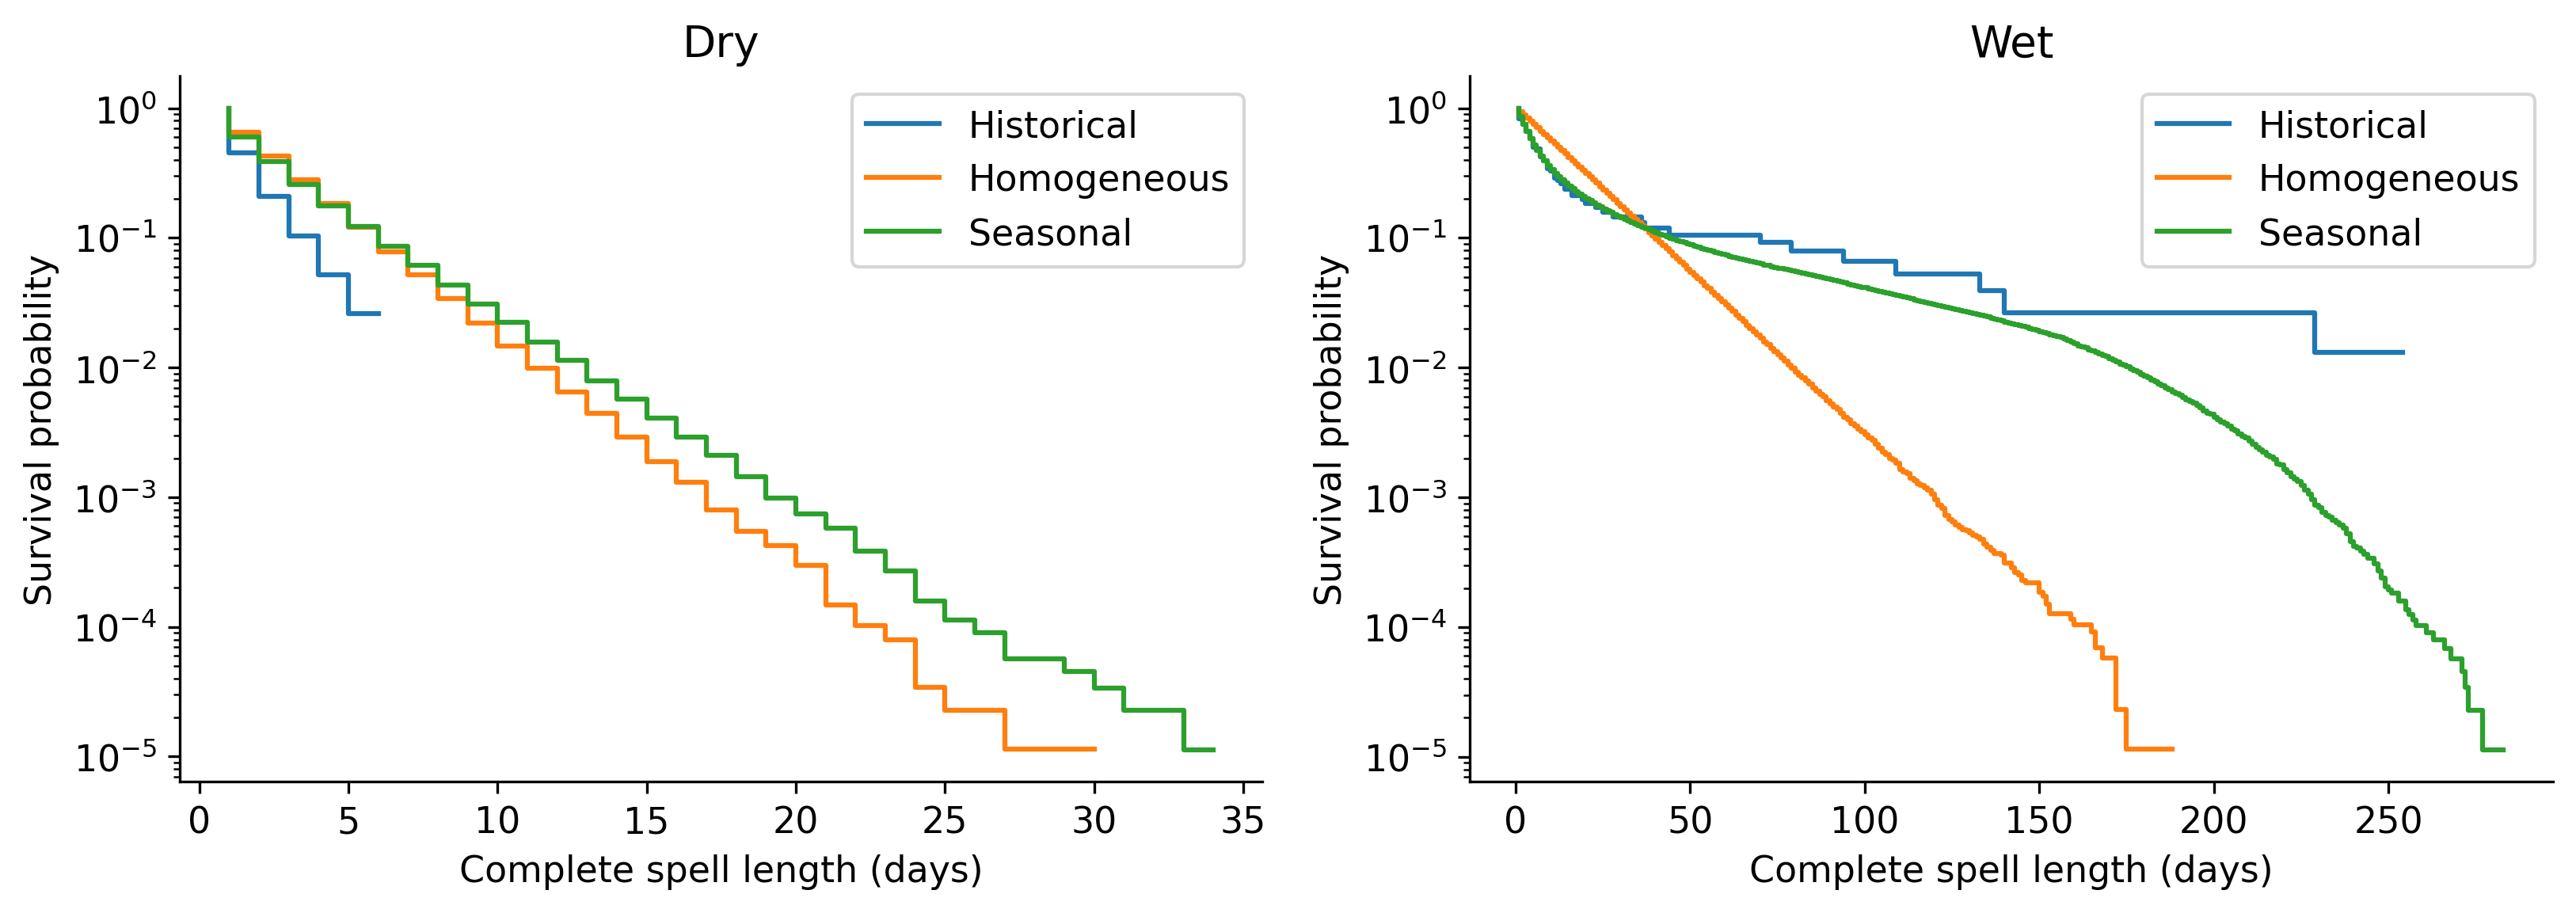

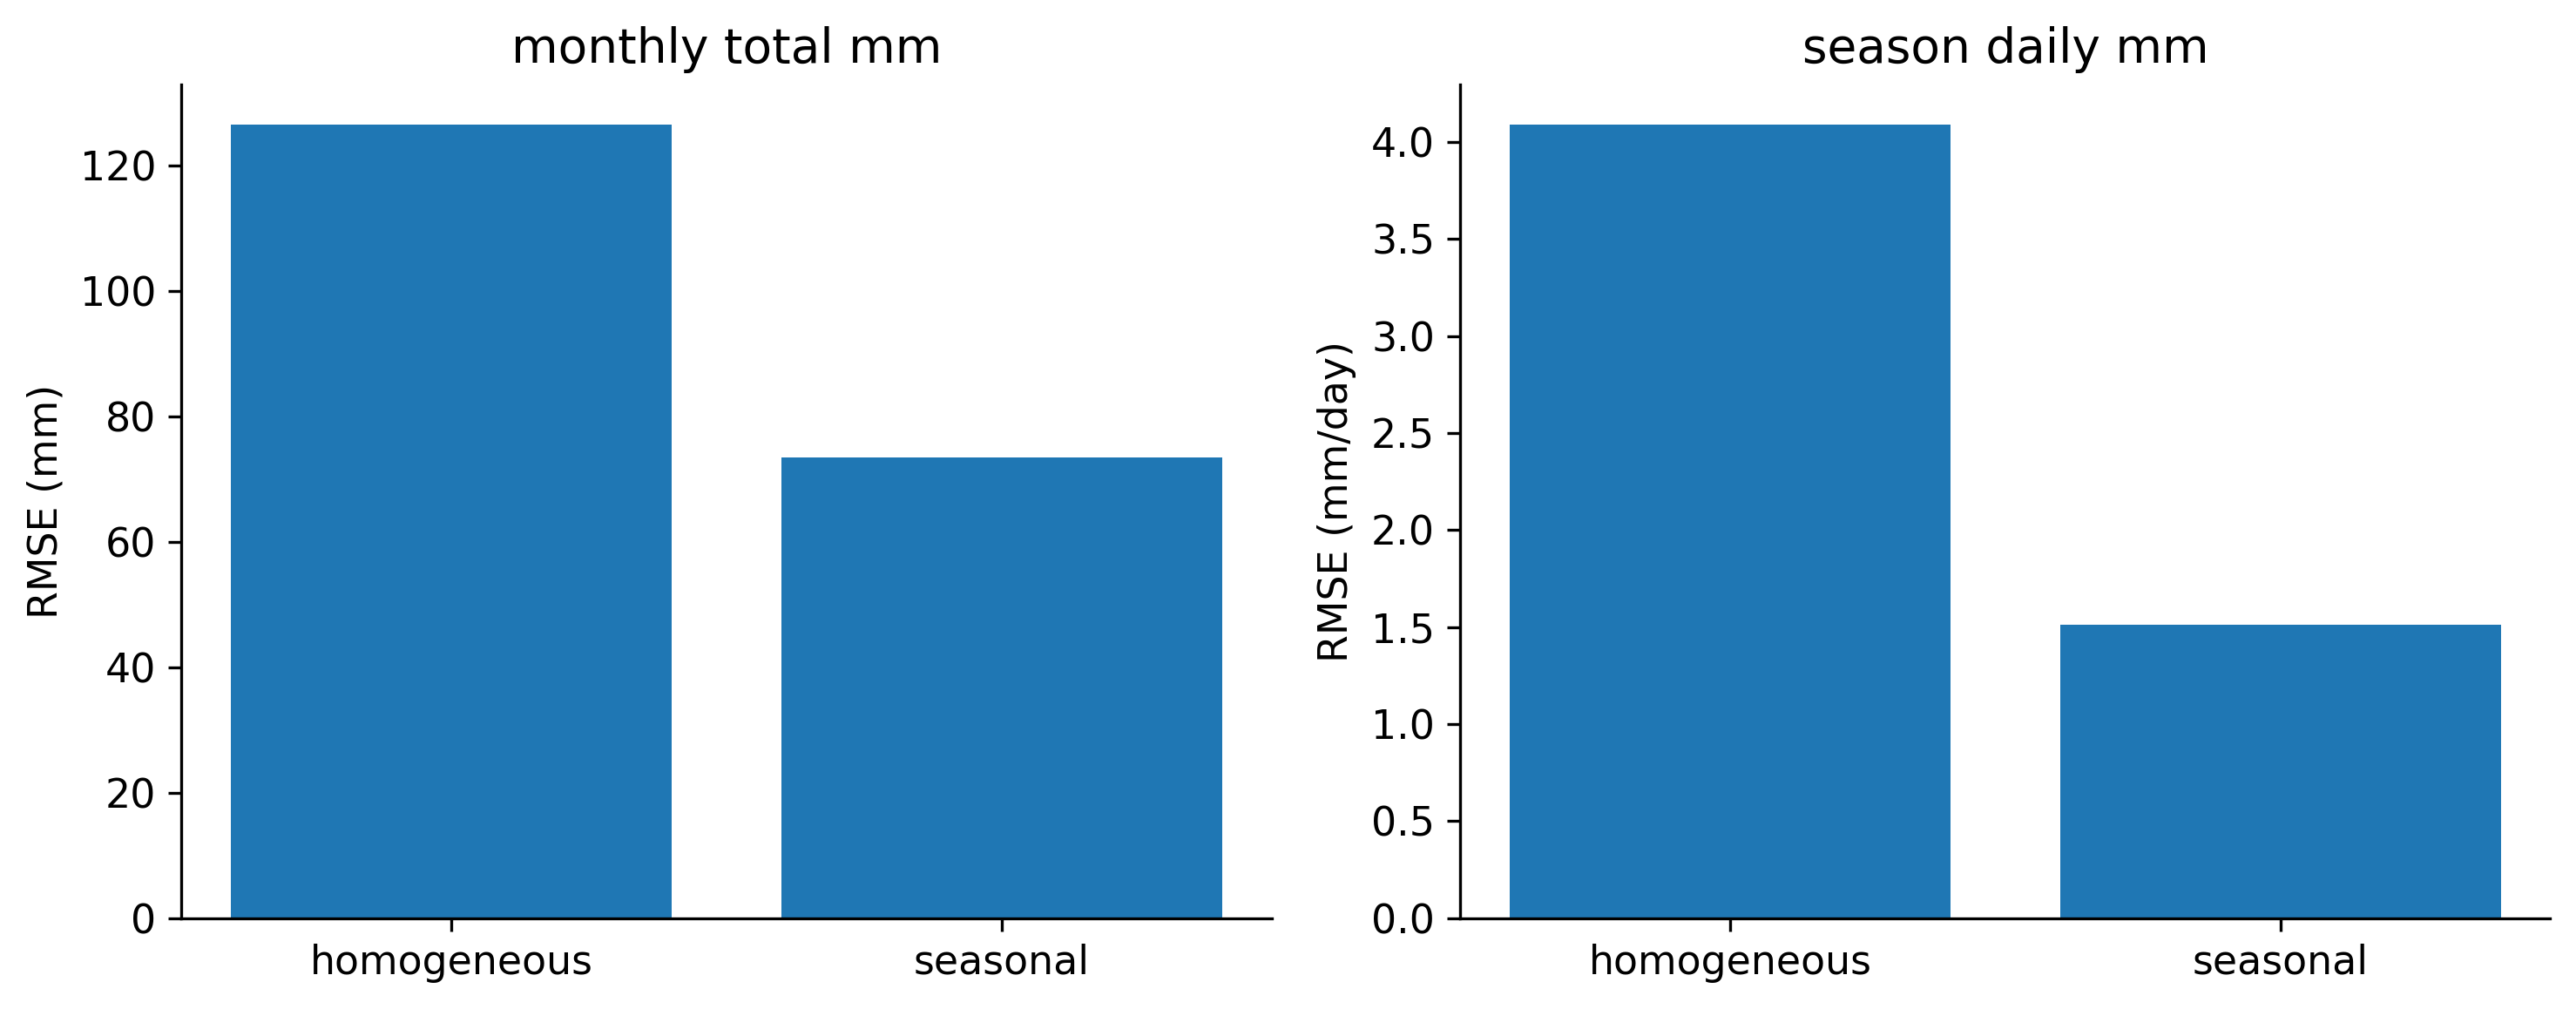

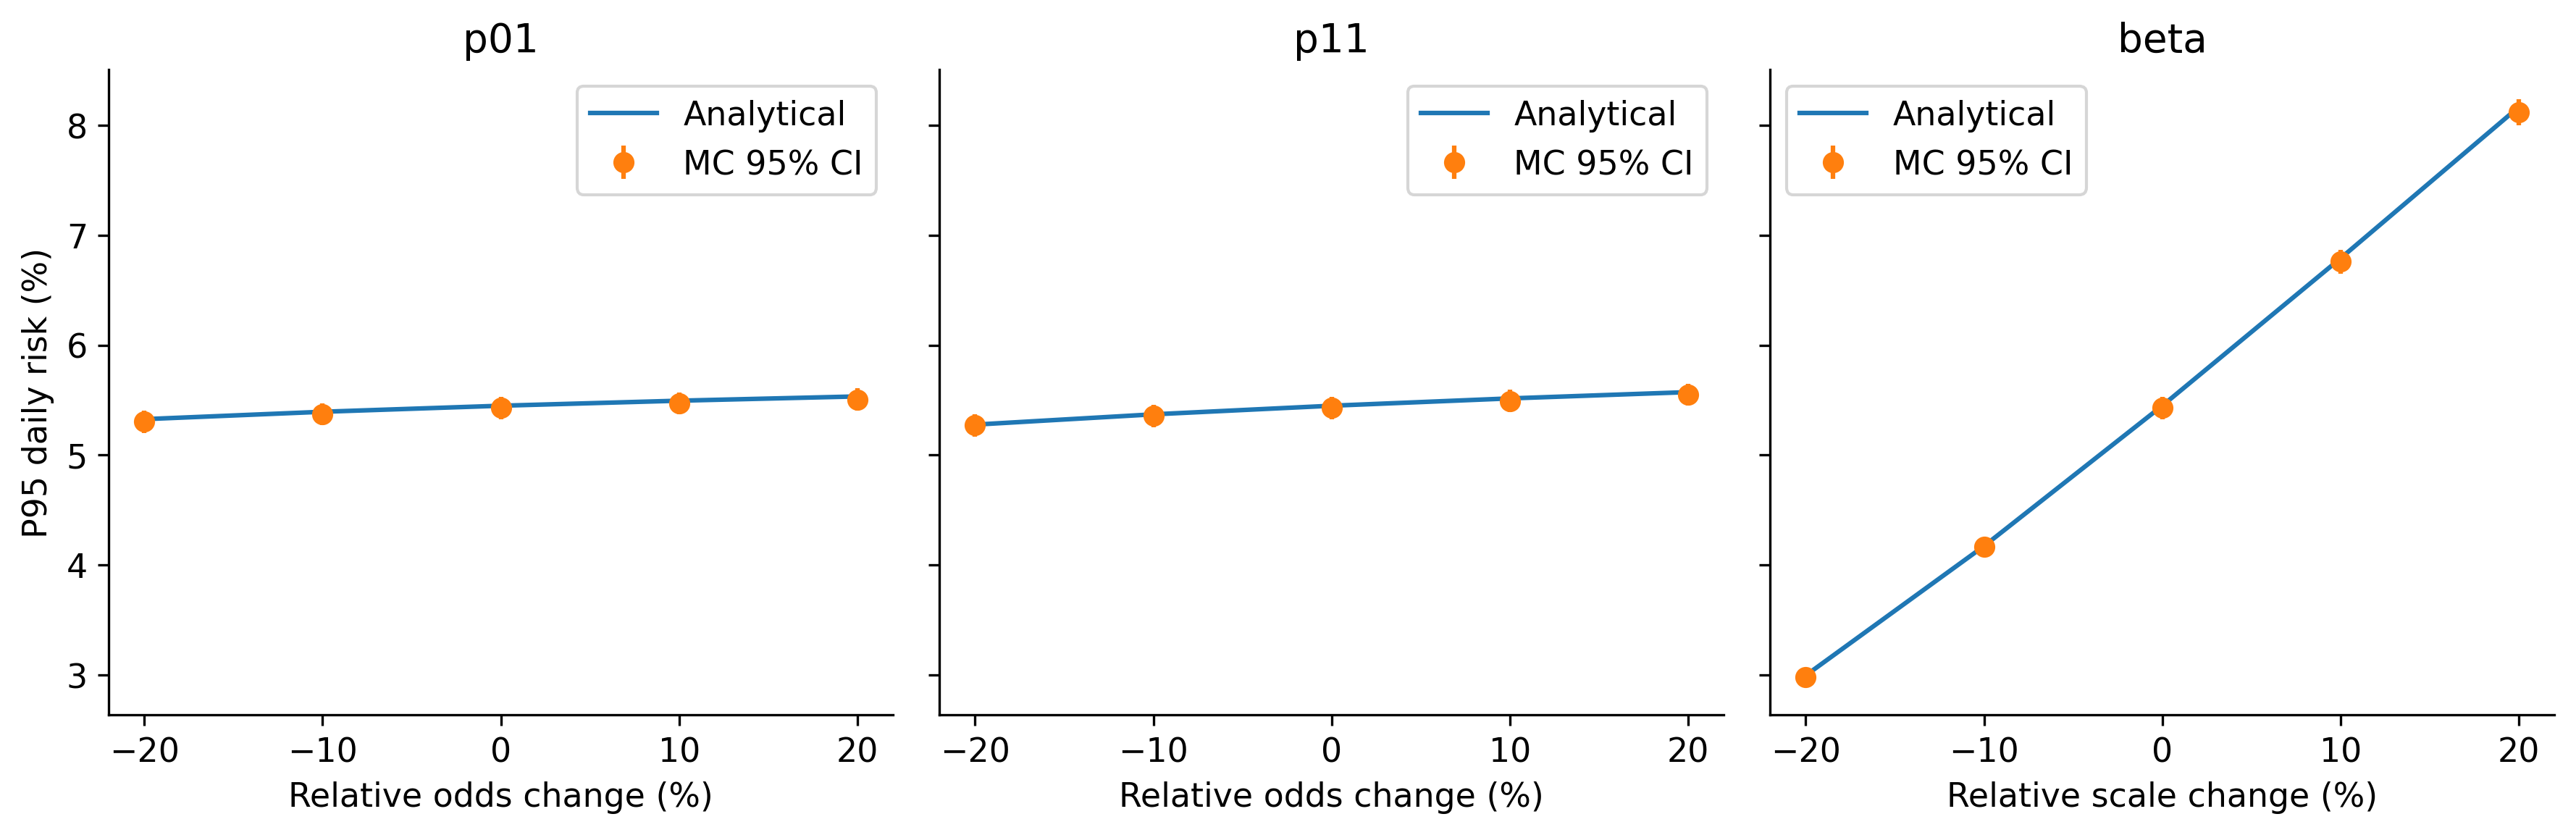

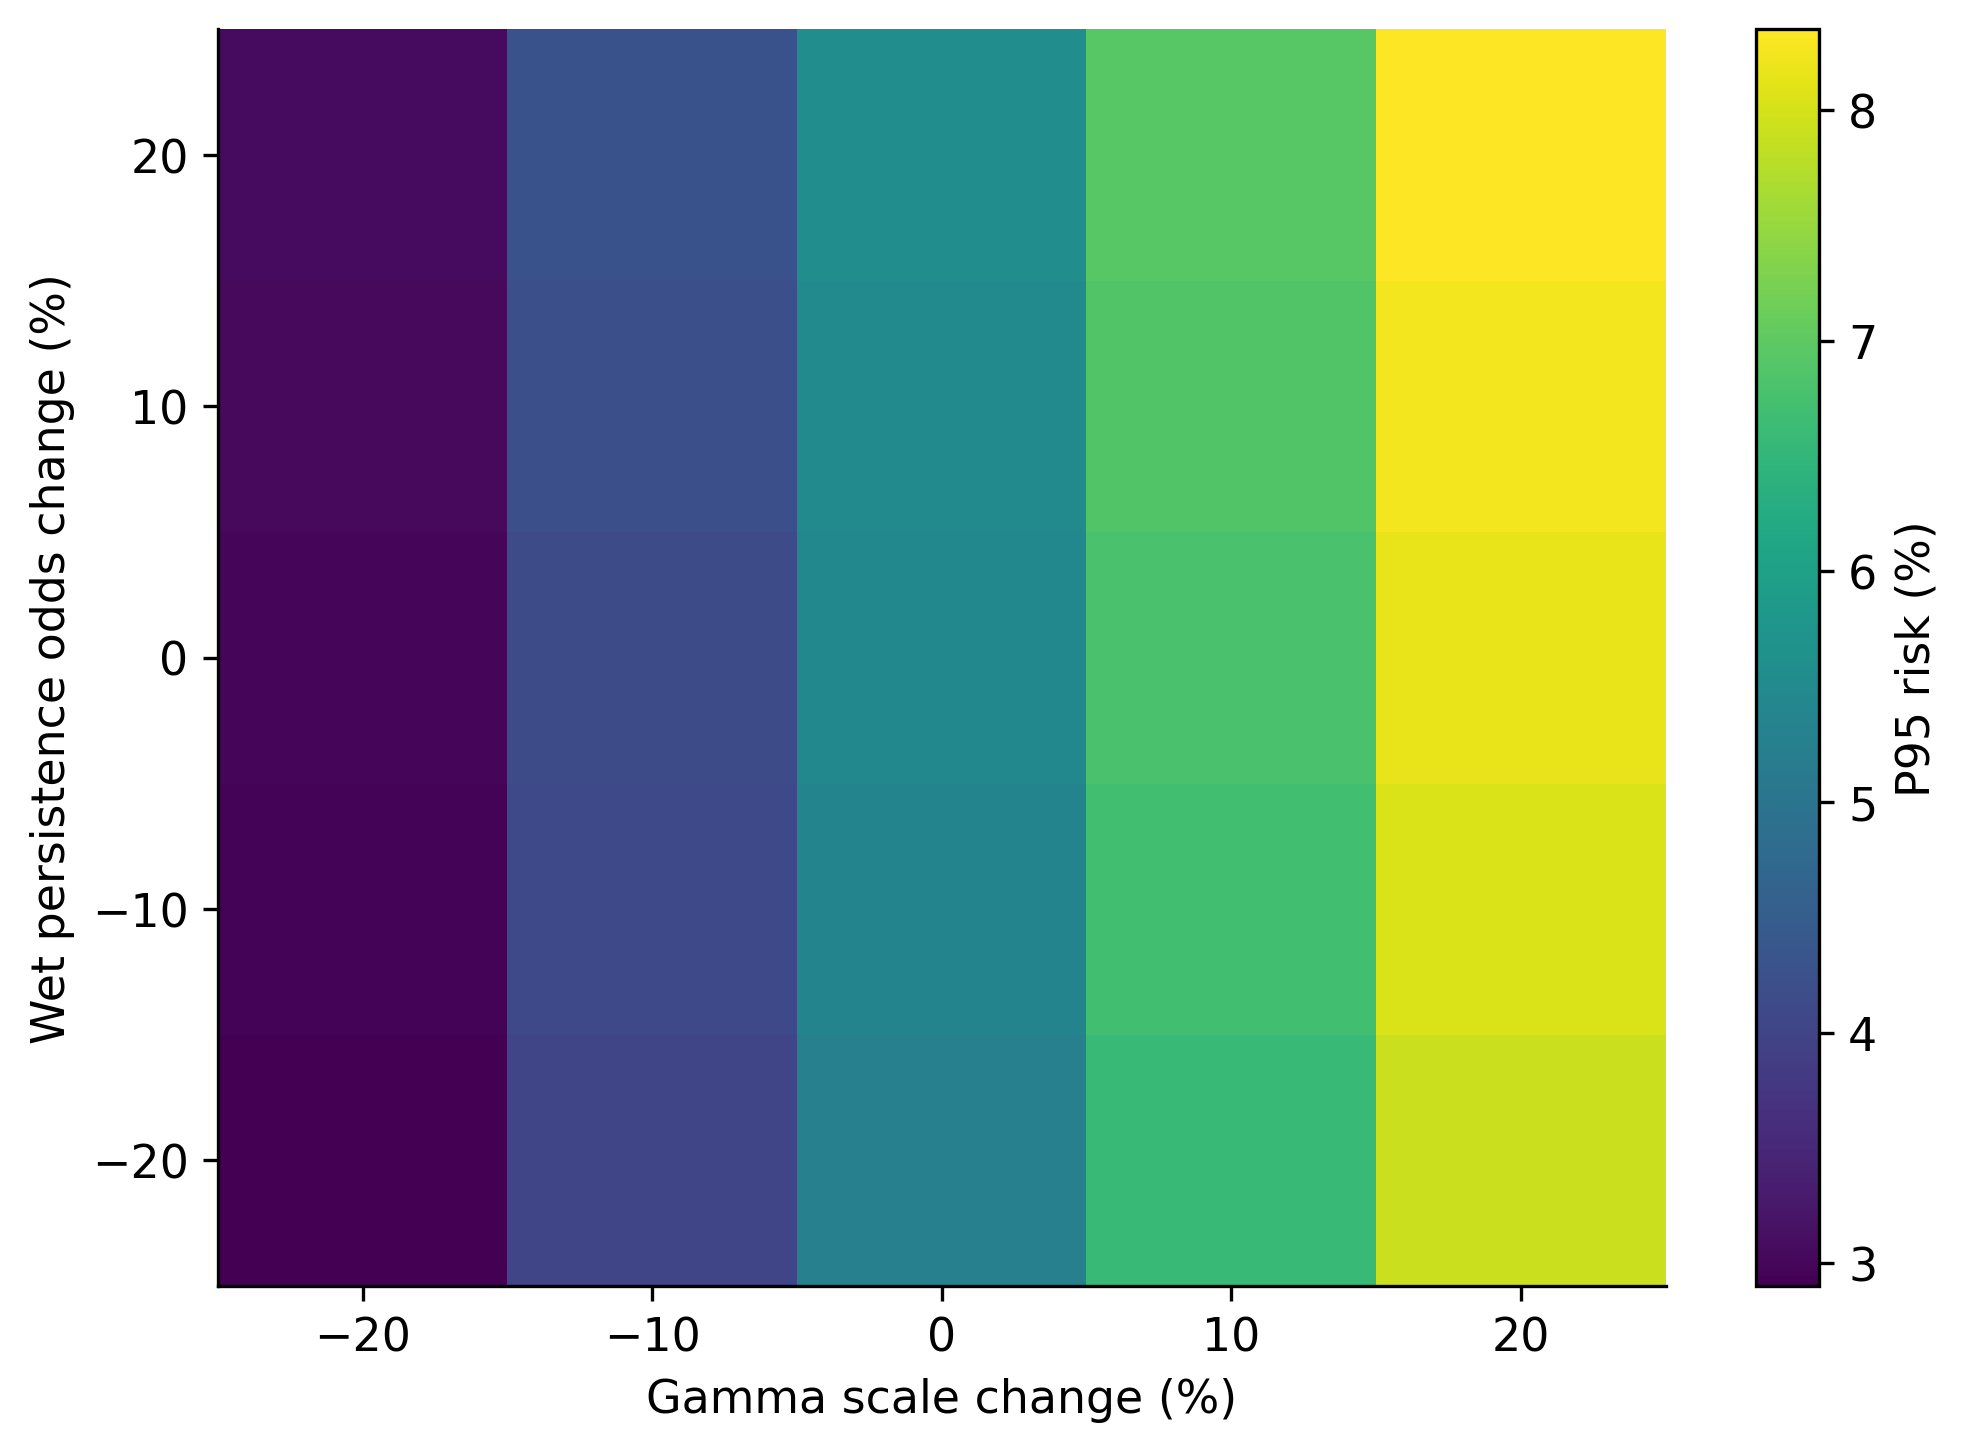

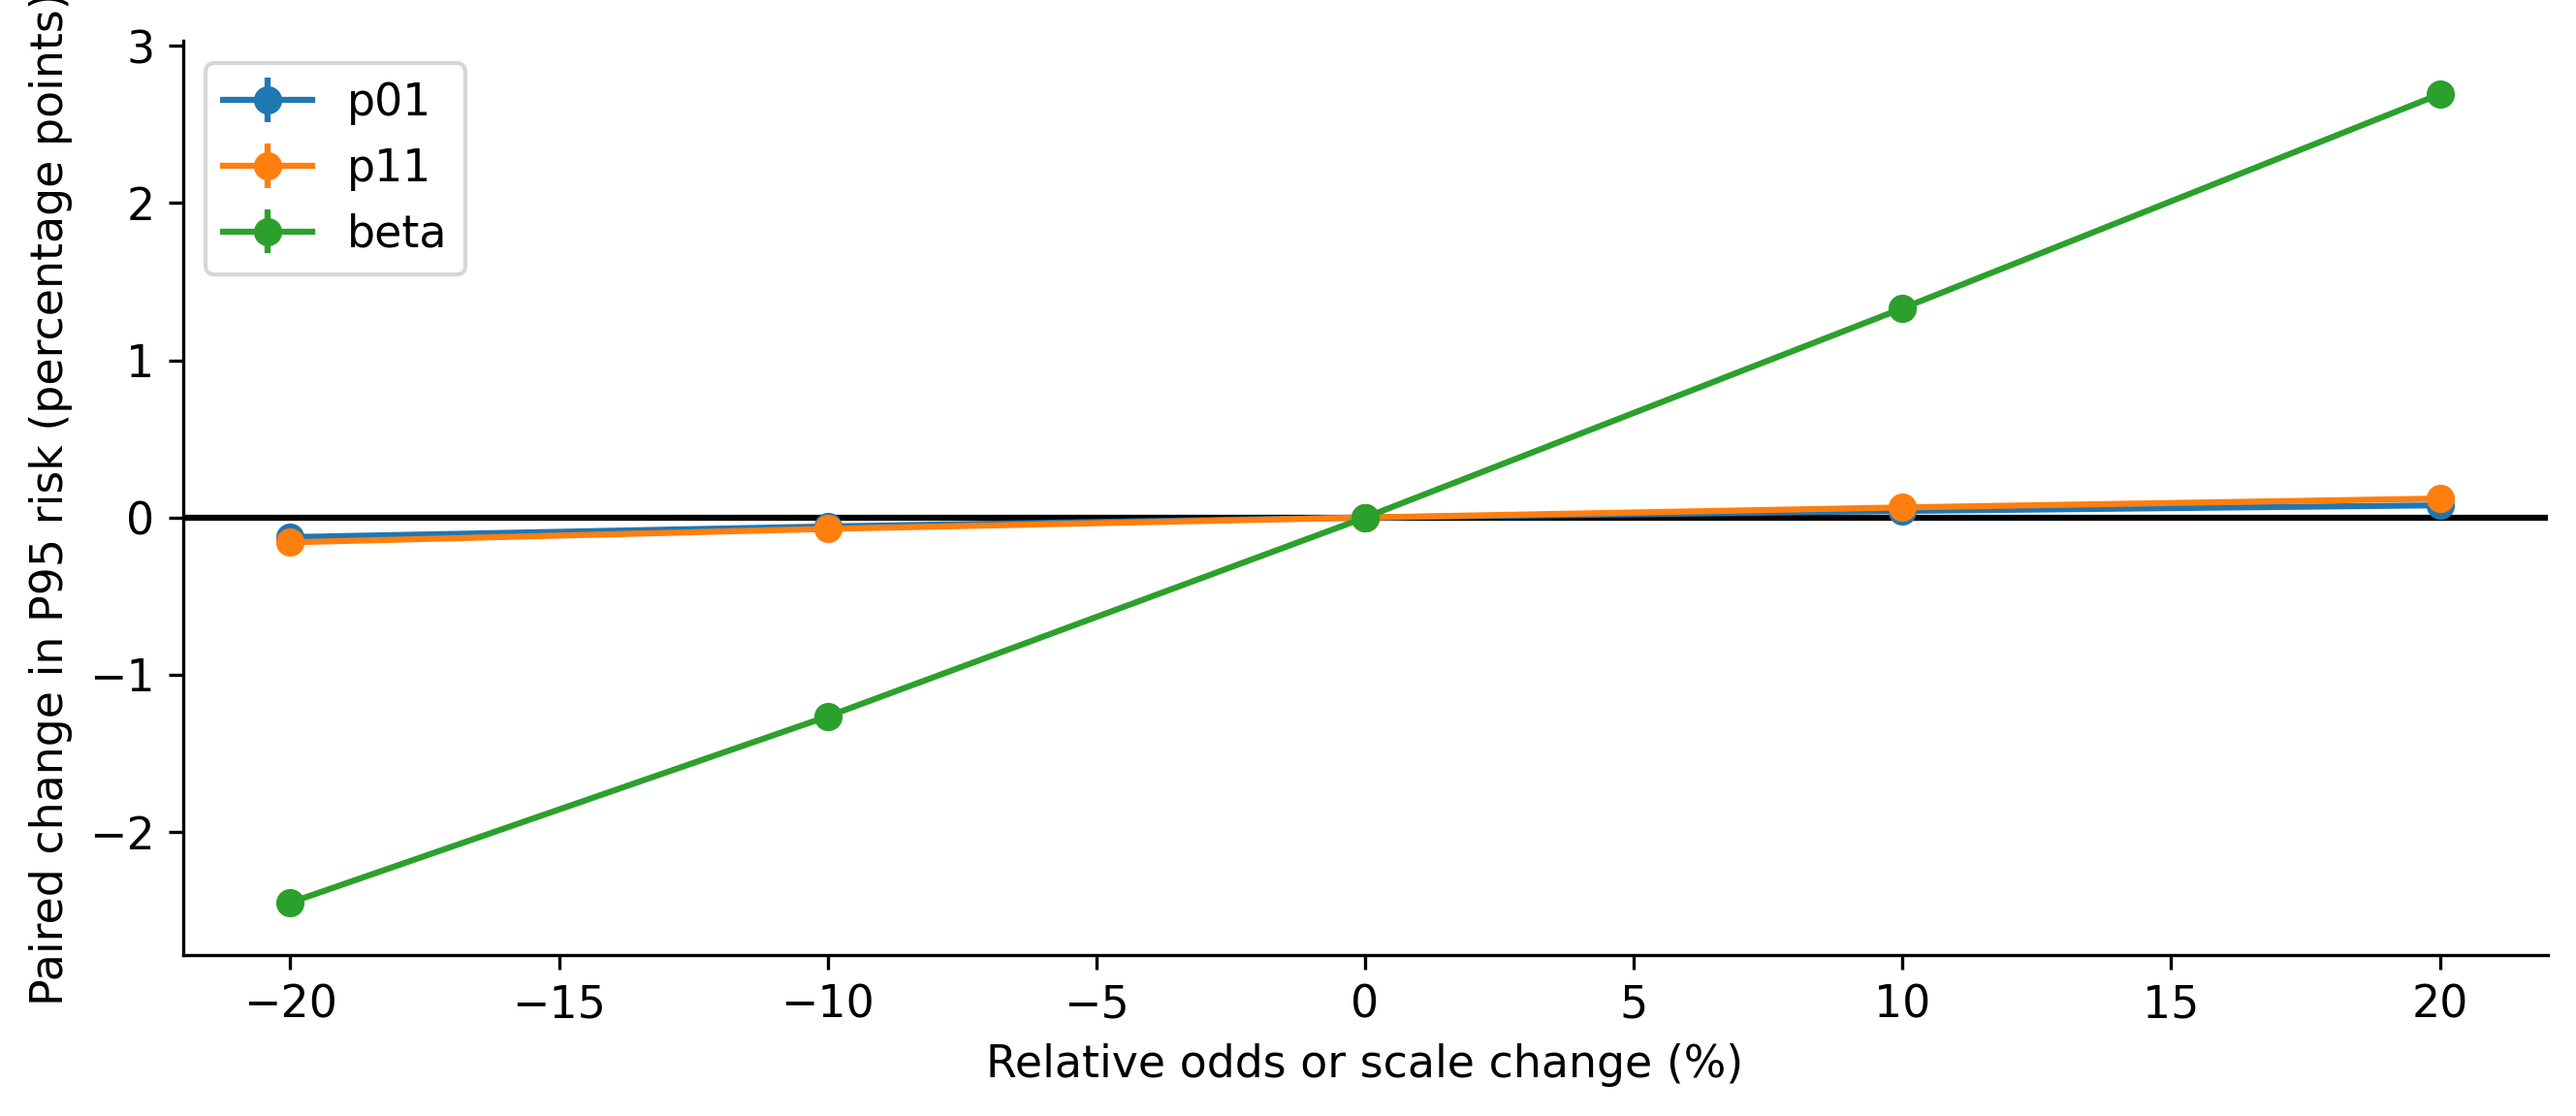

In [ ]:
%%scientific
# C29
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(calendar[:365],season_amounts[0,:365],lw=.8)
ax.axhline(q95,ls='--',label='Calibration P95')
ax.set(xlabel='Date',ylabel='Rainfall (mm/day)',title='Example seasonal trajectory'); ax.legend()
finish(fig,'F24_seasonal_trajectory')
fig,ax=plt.subplots(figsize=(9,4))
ratio=(season_verify['mean']-season_verify.analytical)/season_verify.mcse
ax.errorbar(range(len(ratio)),ratio,yerr=1.96,fmt='o'); ax.axhline(0,color='black'); ax.axhline(4,ls='--'); ax.axhline(-4,ls='--')
ax.set(xticks=range(4),xticklabels=['Wet probability','Daily rainfall','P95 risk','P99 risk'],ylabel='Error (MCSE units)',title='Seasonal analytical verification')
finish(fig,'F25_seasonal_verification')
fig,ax=plt.subplots(figsize=(9,4))
for model,group in comparative[comparative.metric=='monthly_total_mm'].groupby('model'):
    x=group.group.astype(int).to_numpy(); ax.plot(x,group['mean'],marker='o',label=model); ax.fill_between(x,group.pi_low,group.pi_high,alpha=.15)
ax.plot(x,group.historical,color='black',marker='s',label='Historical'); ax.set(xticks=range(1,13),xlabel='Month',ylabel='Mean monthly total (mm)'); ax.legend()
finish(fig,'F26_comparative_monthly')
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,metric in zip(axs,['season_P95_frequency','season_P99_frequency']):
    for i,(model,g) in enumerate(comparative[comparative.metric==metric].groupby('model')):
        ax.errorbar(np.arange(4)+(i-.5)*.14,g['mean']*100,yerr=[(g['mean']-g.pi_low)*100,(g.pi_high-g['mean'])*100],fmt='o',label=model)
    ax.scatter(range(4),g.historical*100,marker='s',color='black',label='Historical'); ax.set(xticks=range(4),xticklabels=seasons,ylabel='Exceedance (%)',xlabel='Season',title=metric.split('_')[1]); ax.legend()
finish(fig,'F27_comparative_seasonal_extremes')
fig,axs=plt.subplots(1,2,figsize=(11,4))
for state,ax in enumerate(axs):
    for label,array in [('Historical',observed_states),('Homogeneous',hold_states),('Seasonal',season_states)]:
        runs=np.concatenate([complete_spells(row,state) for row in array]); x=np.arange(1,runs.max()+1); y=np.array([(runs>=k).mean() for k in x]); ax.step(x,y,label=label)
    ax.set(yscale='log',xlabel='Complete spell length (days)',ylabel='Survival probability',title=['Dry','Wet'][state]); ax.legend()
finish(fig,'F28_comparative_spells')
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,metric in zip(axs,['monthly_total_mm','season_daily_mm']):
    g=errors[errors.metric==metric]; ax.bar(g.model,g.rmse); ax.set(ylabel='RMSE (mm)' if metric=='monthly_total_mm' else 'RMSE (mm/day)',title=metric.replace('_',' '))
finish(fig,'F29_comparative_errors')
fig,axs=plt.subplots(1,3,figsize=(12,4),sharey=True)
for ax,axis,col in zip(axs,['p01','p11','beta'],['k01','k11','kbeta']):
    g=sensitivity[(sensitivity.axis==axis)&(sensitivity.metric=='daily_P95_exceedance')]; x=(g[col]-1)*100
    ax.plot(x,g.analytical*100,label='Analytical'); ax.errorbar(x,g['mean']*100,yerr=[(g['mean']-g.ci_low)*100,(g.ci_high-g['mean'])*100],fmt='o',label='MC 95% CI'); ax.set(xlabel='Relative '+('scale' if axis=='beta' else 'odds')+' change (%)',title=axis); ax.legend()
axs[0].set_ylabel('P95 daily risk (%)'); finish(fig,'F30_sensitivity_curves')
fig,ax=plt.subplots(figsize=(7,5)); grid=sensitivity[(sensitivity.axis=='joint')&(sensitivity.metric=='daily_P95_exceedance')].pivot(index='k11',columns='kbeta',values='analytical')*100
im=ax.imshow(grid,origin='lower',aspect='auto'); fig.colorbar(im,ax=ax,label='P95 risk (%)'); ax.set(xticks=range(5),yticks=range(5),xticklabels=['−20','−10','0','10','20'],yticklabels=['−20','−10','0','10','20'],xlabel='Gamma scale change (%)',ylabel='Wet persistence odds change (%)'); finish(fig,'F31_joint_sensitivity')
fig,ax=plt.subplots(figsize=(9,4))
for axis,col in zip(['p01','p11','beta'],['k01','k11','kbeta']):
    g=sensitivity[(sensitivity.axis==axis)&(sensitivity.metric=='daily_P95_exceedance')]; ax.errorbar((g[col]-1)*100,g.paired_delta*100,yerr=[(g.paired_delta-g.paired_ci_low)*100,(g.paired_ci_high-g.paired_delta)*100],marker='o',label=axis)
ax.axhline(0,color='black'); ax.set(xlabel='Relative odds or scale change (%)',ylabel='Paired change in P95 risk (percentage points)'); ax.legend(); finish(fig,'F32_extreme_risk_changes')

In [ ]:
%%scientific
# C30
model_export.update(schema_version=2, season_by_month={str(k):v for k,v in season_map.items()},transition_season='destination_date',initial_state_semantics='day_before_first_date',holdout_initial_state=origin)
(PROCESSED_DIR/'model_parameters.json').write_text(json.dumps(model_export,indent=2,allow_nan=False)+'\n')
(PROCESSED_DIR/'seasonal_sensitivity_config.json').write_text(json.dumps({**S6,'seed':SEED,'primary_threshold_mm':float(q95),'secondary_threshold_mm':float(q99),'paired_holdout_namespace':[3],'sensitivity_namespace':[6]},indent=2)+'\n')
for cell,names in {'C25':['seasonal_daily_expectations.csv','seasonal_analytical.csv','seasonal_verification.csv'],'C26':['seasonal_holdout.csv'],'C27':['comparative_holdout.csv','comparative_errors.csv','comparative_paired.csv'],'C28':['sensitivity_scenarios.csv'],'C30':['seasonal_sensitivity_config.json','seasonal_execution_runtime.csv']}.items():
    for name in names:
        manifest.loc[len(manifest)]=[f'data/processed/{name}',cell,name.replace('_',' ')]
for name in FIGURE_DATA:
    if int(name[1:3])>=24:
        manifest.loc[len(manifest)]=[f'figures/{name}.png','C29',name.replace('_',' ')]
manifest.loc[manifest.path.str.endswith(('figure_data.json','output_manifest.csv','model_parameters.json')),'cell']='C30'
manifest.loc[len(manifest)]=['figures/README.md','C30','Generated figure inventory']
(PROCESSED_DIR/'figure_data.json').write_text(json.dumps(FIGURE_DATA,default=str,sort_keys=True),encoding='utf-8')
(OUTPUT/'figures'/'README.md').write_text('# Scientific figures\n\nGenerated by the notebook at 300 DPI.\n\n'+ '\n'.join(f'- [{Path(r.path).name}]({Path(r.path).name}) — {r.cell}: {r.description}' for r in manifest.itertuples() if r.path.endswith('.png'))+'\n',encoding='utf-8')
pd.DataFrame([{'elapsed_seconds':time.perf_counter()-RUN_START,'python':platform.python_version(),'pandas':pd.__version__, 'execution_scope':'complete notebook workflow'}]).to_csv(PROCESSED_DIR/'seasonal_execution_runtime.csv',index=False)
manifest.to_csv(PROCESSED_DIR/'output_manifest.csv',index=False)
assert len(FIGURE_DATA)==32 and manifest.path.is_unique and all((OUTPUT/path).is_file() for path in manifest.path)
print('Complete seasonal pipeline:',len(manifest),'outputs; elapsed:',time.perf_counter()-RUN_START)

Local scientific source test: 32 figure entries and 72 manifest entries; complete scientific source execution.


## 6. Discussion and limitations

Daily provider totals are a comparison product, not independent rain-gauge observations. Differences can reflect accumulation boundaries, rounding or provider processing/model selection; residuals cannot identify the exact mechanism without acquisition metadata. The midnight identity isolates the effect of the timestamp convention. Best Match may introduce discontinuities. Historical holdout summaries are not forecast skill. Gamma fitting and Markov calibration are complete; analytical simulation verification and holdout evaluation are reported above.

Local execution found the uncorrected totals match the supplied daily product to floating-point precision; corrected MAE 0.406067 mm, RMSE 1.303786 mm and maximum difference 22 mm. The verified midnight identity explains the differences. Retain the approved corrected series; revisit the accumulation convention only with documented evidence. Previous-run regression benchmarks: calibration P95 = 25.2 mm; P99 = 46.296 mm. Both are recalculated in C05. No positive trace totals were removed. Figures and tables: modified Open-Meteo data, CC BY 4.0.

First-order occurrence is a baseline, not a claim that tropical spell persistence is adequately captured; Wilson Kemsley et al. [3] found model-order preference varies by diagnostic. Stern and Coe [1] motivate seasonal occurrence and amounts; Wilks [2] and Jin et al. [5] motivate tail comparisons. The continuous truncated likelihood approximates rounded rainfall measurements. Conditional amounts may be serially dependent, and homogeneous parameters obscure seasonal changes. Gamma remains the approved baseline; alternative fits are diagnostic. No holdout data enter estimation, and homogeneous Monte Carlo simulation is implemented; browser simulation remains deferred.

Homogeneity cannot reproduce systematic seasonal variation. Gamma underestimates the far tail; geometric spells miss exceptional wet persistence. Holdout statistics assess aggregate realism, not forecasts. Rainfall exceedance is not flood risk; drainage, antecedent moisture and exposure are absent. Confidence intervals condition on fitted parameters. Best Match provenance and midnight discrepancy remain unresolved.

Seasonal modelling improves monthly climatology RMSE by 41.93% and seasonal mean rainfall RMSE by 63.08%, but overall P95 frequency remains underestimated and is slightly worse than in the homogeneous model. Maximum complete wet-spell length is better represented but the observed 254 days remains above the simulated prediction interval. In the controlled perturbation range, Gamma scale dominates marginal extreme risk: a +20% scale increases analytical P95 probability by about 49.9%. Persistence materially changes wet-spell duration. These are mathematical sensitivity results, not empirical causal interventions or climate projections. The predefined seasonal model was fitted only to calibration data; prior holdout findings are already visible.


## 7. References

1. R. D. Stern and R. Coe, “A model fitting analysis of daily rainfall data,” Journal of the Royal Statistical Society: Series A, vol. 147, no. 1, pp. 1–34, 1984. https://academic.oup.com/jrsssa/article/147/1/1/7106047
   - Relevance: Seasonally varying occurrence and conditional rainfall amounts; dry-spell analysis.

2. D. S. Wilks, “Multisite generalization of a daily stochastic precipitation generation model,” Journal of Hydrology, vol. 210, pp. 178–191, 1998. https://doi.org/10.1016/S0022-1694(98)00186-3
   - Relevance: Mixed exponential amounts and spatial dependence; motivates comparison rather than adopting a multisite model.

3. S. Wilson Kemsley, T. J. Osborn, S. Dorling, C. Wallace, and J. Parker, “Selecting Markov chain orders for generating daily precipitation series across different Köppen climate regimes,” International Journal of Climatology, accepted manuscript, 2021. https://doi.org/10.1002/joc.7175
   - Relevance: Model-order performance depends on metric; tropical spell lengths merit particular attention.

4. S. Wilson Kemsley, T. J. Osborn, S. R. Dorling, and C. Wallace, “Pattern scaling the parameters of a Markov-chain gamma-distribution daily precipitation generator,” International Journal of Climatology, online 2023. https://doi.org/10.1002/joc.8320
   - Relevance: Monthly transition probabilities and gamma parameters; pattern scaling requires external climate information.

5. H. G. Jin, S. Hong, and Y. Kim, “Synthetic rainfall modeling using a modified hybrid gamma-GP distribution,” Applied Sciences, vol. 15, art. 9563, 2025. https://doi.org/10.3390/app15179563
   - Relevance: Hybrid body-tail modelling and seasonal variability; not evidence of local fit.

6. S. Sohrabi and F. P. Brissette, “Evaluation of a stochastic weather generator for long-term ensemble streamflow forecasts,” Hydrological Sciences Journal, vol. 66, no. 3, pp. 474–487, 2021. https://doi.org/10.1080/02626667.2021.1873343
   - Relevance: Ensemble evaluation against historical resampling; gamma tail limitations.

7. A. Deoras, A. G. Turner, K. M. R. Hunt, and I. M. S. P. Jayawardena, “The influence of weather patterns and the Madden-Julian Oscillation on extreme precipitation over Sri Lanka,” Geophysical Research Letters, vol. 50, e2023GL103727, 2023. https://doi.org/10.1029/2023GL103727
   - Relevance: Seasonality and persistence of extremes; national thresholds are not Colombo thresholds.

8. J. Muñoz-Sabater et al., “ERA5-Land: a state-of-the-art global reanalysis dataset for land applications,” Earth System Science Data, vol. 13, pp. 4349–4383, 2021. https://doi.org/10.5194/essd-13-4349-2021
   - Relevance: Reanalysis resolution and land-surface methodology; finer resolution does not guarantee local rainfall accuracy.

Dataset attribution is separate in `data/README.md`.